# Task 3: corrected protocol v2

This portable Task 3 section is intended for later integration with Tasks 1 and 2. Only this notebook, the five assignment CSVs, and the listed Python packages are needed. There are no repository imports or pre-existing result-file dependencies.

**Protocol correction after the original test results were observed:** all original model settings and finalist identities are retained. This is not a newly untouched test. Development/test periods refer to return realization dates. Every training target is observed strictly before its prediction day. Features are known at close t and predict the next trading day; the main backtest retains the same-close execution assumption. Delayed execution is reported separately.

Run all cells in order; the 62 development experiments can take several hours. Outputs and figures are generated under `results/corrected_v2`. All historical comparisons below are labeled as original-protocol results.

In [1]:
from pathlib import Path
import os
# Edit only this directory if your CSVs are elsewhere.
DATA_DIR = Path(os.environ.get("TASK3_DATA_DIR", "instructions-data"))
OUTPUT_DIR = Path("results/corrected_v2")

## Input checks and reproducibility
Required packages: numpy, pandas, scipy, scikit-learn, matplotlib; Jupyter also needs ipykernel. A missing CSV is reported explicitly. Files ending in `.webloc` are shortcuts, not CSV data.

In [2]:
"""Portable protocol loading, input checks, and reproducibility fingerprints."""
import hashlib
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import platform
import sys
from datetime import datetime, timezone

PROTOCOL_VERSION = 'corrected_v2'
DATA_FILES = ('eq_returns.csv', 'eq_indicator.csv', 'eq_stock_metadata.csv',
              'psych_bullish.csv', 'psych_bearish.csv')
PACKAGES = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy',
            'scikit-learn': 'sklearn', 'matplotlib': 'matplotlib'}


def preflight(data_dir):
    """Fail before fitting, with all missing CSVs and dependencies in one message."""
    data_dir = Path(data_dir).expanduser()
    missing = [str(data_dir / name) for name in DATA_FILES if not (data_dir / name).is_file()]
    packages = [name for name, module in PACKAGES.items() if importlib.util.find_spec(module) is None]
    if missing or packages:
        raise FileNotFoundError('Task 3 input check failed.\nMissing CSVs: ' +
                                (', '.join(missing) or 'none') + '\nMissing packages: ' +
                                (', '.join(packages) or 'none') +
                                '\nSet DATA_DIR (notebook) or --data-dir (script) to the CSV directory.')
    return data_dir




def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str, allow_nan=False) + '\n')


def run_manifest(data_dir, config, source_hashes):
    """Fingerprints refer to actual bytes, not assumed package or data versions."""
    return {'protocol_version': PROTOCOL_VERSION, 'created_utc': datetime.now(timezone.utc).isoformat(),
            'python': sys.version, 'platform': platform.platform(),
            'packages': {p: importlib.metadata.version(p) for p in PACKAGES},
            'data_sha256': {p: file_sha256(Path(data_dir) / p) for p in DATA_FILES},
            'source_sha256': source_hashes, 'configuration': config,
            'status': 'running', 'test_status': 'correction_after_original_results_observed'}


def prepare_output(output_dir):
    """A separate namespace prevents old command invocations from overwriting history."""
    out = Path(output_dir)
    if 'corrected_v2' not in out.parts:
        raise ValueError('output directory must be inside a corrected_v2 namespace')
    out.mkdir(parents=True, exist_ok=True)
    (out / 'cache').mkdir(exist_ok=True)
    return out


In [3]:
DATA_DIR = preflight(DATA_DIR)
print("All five CSVs and required packages found.")

All five CSVs and required packages found.


## Fixed configuration and experiment definitions
The exact original penalties and the 62 named development configurations are replayed. Corrected scores do not trigger new finalist selection. Two predictions before the first scheduled refit supply boundary and delay coverage; scheduled refit dates from 1990 (2010 for sentiment) remain unchanged.

In [4]:
CONFIG = {'development_period': ['1990-01-01', '2010-12-31'],
 'test_period': ['2011-01-01', '2013-12-31'],
 'features': ['rev_1',
              'rev_1_hl5',
              'rev_1_hl10',
              'rev_5',
              'rev_5_hl5',
              'rev_5_hl10',
              'rev_21',
              'rev_21_hl5',
              'rev_21_hl10',
              'mom_12_1',
              'vol_level',
              'rev_5_sec',
              'rev_5_sec_hl5',
              'rev_5_sec_hl10',
              'rev_21_sec',
              'rev_21_sec_hl5',
              'rev_21_sec_hl10',
              'mom_12_1_sec'],
 'finalists': [{'name': 'lasso',
                'source_exp_id': 'E012',
                'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639},
                'refit_every': 63,
                'train_window_days': 756,
                'subsample': None,
                'pred_smoothing_halflife': 0},
               {'name': 'rf',
                'source_exp_id': 'E058',
                'spec': {'model': 'rf', 'max_depth': 12, 'min_samples_leaf': 200},
                'refit_every': 252,
                'train_window_days': 756,
                'subsample': 200000,
                'pred_smoothing_halflife': 0},
               {'name': 'mlp',
                'source_exp_id': 'E059',
                'spec': {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60},
                'refit_every': 252,
                'train_window_days': 756,
                'subsample': None,
                'pred_smoothing_halflife': 0},
               {'name': 'mlp_slow',
                'source_exp_id': 'E066',
                'spec': {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60},
                'refit_every': 252,
                'train_window_days': 756,
                'subsample': None,
                'pred_smoothing_halflife': 5}],
 'baselines': [{'name': 'baseline_rev_5',
                'source_exp_id': 'E005',
                'rule': '-vadj_c.rolling(5, min_periods=3).mean()'},
               {'name': 'baseline_mom_12_1',
                'source_exp_id': 'E006',
                'rule': 'vadj_c.rolling(231, min_periods=231).sum().shift(21)'}],
 'protocol_version': 'corrected_v2',
 'purpose': 'Corrections after original test results were observed; no new finalist selection.',
 'period_convention': 'realization dates',
 'train_cutoff': 'target_realization_date < prediction_date',
 'panel_start': '1981-05-22',
 'first_refit': '1990-01-01',
 'seed': 42,
 'min_predictions': 100,
 'output_dir': 'results/corrected_v2',
 'warmup': 'One extra fit before the first scheduled refit supplies the first outcome and one-day '
           'delay; regular refit dates are unchanged.',
 'execution_assumption': 'Features known at close t, returns t to t+1; same-close execution '
                         'assumed, delayed execution reported separately.',
 'historical_harness_commit': 'cceeb15e720d5b637c2082d1da9a74c5f101496a'}

EXPERIMENTS = [{'source_exp_id': 'E005',
  'name': 'baseline_rev_5',
  'kind': 'baseline',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'rule': 'rev_5'},
 {'source_exp_id': 'E006',
  'name': 'baseline_mom_12_1',
  'kind': 'baseline',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'rule': 'mom_12_1'},
 {'source_exp_id': 'E007',
  'name': 'lasso_3y_a0',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.01657268816836561}},
 {'source_exp_id': 'E008',
  'name': 'lasso_3y_a1',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.006629075267346245}},
 {'source_exp_id': 'E009',
  'name': 'lasso_3y_a2',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0026516301069384983}},
 {'source_exp_id': 'E010',
  'name': 'lasso_3y_a3',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0010606520427753994}},
 {'source_exp_id': 'E011',
  'name': 'lasso_3y_a4',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.00042426081711015973}},
 {'source_exp_id': 'E012',
  'name': 'lasso_3y_a5',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E013',
  'name': 'lasso_5y_a0',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 1260,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.01657268816836561}},
 {'source_exp_id': 'E014',
  'name': 'lasso_5y_a1',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 1260,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.006629075267346245}},
 {'source_exp_id': 'E015',
  'name': 'lasso_5y_a2',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 1260,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0026516301069384983}},
 {'source_exp_id': 'E016',
  'name': 'lasso_5y_a3',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 1260,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0010606520427753994}},
 {'source_exp_id': 'E017',
  'name': 'lasso_5y_a4',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 1260,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.00042426081711015973}},
 {'source_exp_id': 'E018',
  'name': 'lasso_5y_a5',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 1260,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E019',
  'name': 'lasso_expanding_a0',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.01657268816836561}},
 {'source_exp_id': 'E020',
  'name': 'lasso_expanding_a1',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.006629075267346245}},
 {'source_exp_id': 'E021',
  'name': 'lasso_expanding_a2',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0026516301069384983}},
 {'source_exp_id': 'E022',
  'name': 'lasso_expanding_a3',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0010606520427753994}},
 {'source_exp_id': 'E023',
  'name': 'lasso_expanding_a4',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.00042426081711015973}},
 {'source_exp_id': 'E024',
  'name': 'lasso_expanding_a5',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E025',
  'name': 'rf_3y_d4_l200',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 4, 'min_samples_leaf': 200}},
 {'source_exp_id': 'E026',
  'name': 'rf_3y_d4_l1000',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 4, 'min_samples_leaf': 1000}},
 {'source_exp_id': 'E027',
  'name': 'rf_3y_d6_l200',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 6, 'min_samples_leaf': 200}},
 {'source_exp_id': 'E028',
  'name': 'rf_3y_d6_l1000',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 6, 'min_samples_leaf': 1000}},
 {'source_exp_id': 'E029',
  'name': 'rf_3y_d8_l200',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 8, 'min_samples_leaf': 200}},
 {'source_exp_id': 'E030',
  'name': 'rf_3y_d8_l1000',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 8, 'min_samples_leaf': 1000}},
 {'source_exp_id': 'E031',
  'name': 'mlp_3y_h16_a0.0001',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'mlp', 'hidden': 16, 'alpha': 0.0001}},
 {'source_exp_id': 'E032',
  'name': 'mlp_3y_h16_a0.01',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'mlp', 'hidden': 16, 'alpha': 0.01}},
 {'source_exp_id': 'E033',
  'name': 'mlp_3y_h32_a0.0001',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001}},
 {'source_exp_id': 'E034',
  'name': 'mlp_3y_h32_a0.01',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'mlp', 'hidden': 32, 'alpha': 0.01}},
 {'source_exp_id': 'E035',
  'name': 'lasso_raw_target',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'raw',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E036',
  'name': 'control_negative_permuted_target',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'permuted',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E037',
  'name': 'control_positive_leaky_features',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'leaky',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E038',
  'name': 'sent_lasso_return_18_a5',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '2009-07-13',
  'first_refit': '2010-01-01',
  'period': ['2010-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E039',
  'name': 'sent_lasso_return_18+sentiment_13_a5',
  'kind': 'fit',
  'feature_set': 'return_18+sentiment_13',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '2009-07-13',
  'first_refit': '2010-01-01',
  'period': ['2010-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E040',
  'name': 'sent_lasso_return_18_a2',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '2009-07-13',
  'first_refit': '2010-01-01',
  'period': ['2010-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0026516301069384983}},
 {'source_exp_id': 'E041',
  'name': 'sent_lasso_return_18+sentiment_13_a2',
  'kind': 'fit',
  'feature_set': 'return_18+sentiment_13',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '2009-07-13',
  'first_refit': '2010-01-01',
  'period': ['2010-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0026516301069384983}},
 {'source_exp_id': 'E042',
  'name': 'sent_lasso_sentiment_13_a5',
  'kind': 'fit',
  'feature_set': 'sentiment_13',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '2009-07-13',
  'first_refit': '2010-01-01',
  'period': ['2010-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'lasso', 'alpha': 0.0001697043268440639}},
 {'source_exp_id': 'E043',
  'name': 'sent_rf_return_18+sentiment_13',
  'kind': 'fit',
  'feature_set': 'return_18+sentiment_13',
  'target_variant': 'demeaned',
  'train_window': None,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '2009-07-13',
  'first_refit': '2010-01-01',
  'period': ['2010-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 4, 'min_samples_leaf': 1000}},
 {'source_exp_id': 'E044',
  'name': 'lasso_nodemean',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': False,
  'source': 'E012'},
 {'source_exp_id': 'E045',
  'name': 'lasso_hl2',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E012',
  'halflife': 2},
 {'source_exp_id': 'E046',
  'name': 'lasso_hl5',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E012',
  'halflife': 5},
 {'source_exp_id': 'E047',
  'name': 'lasso_hl10',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E012',
  'halflife': 10},
 {'source_exp_id': 'E048',
  'name': 'rf_nodemean',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': False,
  'source': 'E029'},
 {'source_exp_id': 'E049',
  'name': 'rf_hl2',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E029',
  'halflife': 2},
 {'source_exp_id': 'E050',
  'name': 'rf_hl5',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E029',
  'halflife': 5},
 {'source_exp_id': 'E051',
  'name': 'rf_hl10',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E029',
  'halflife': 10},
 {'source_exp_id': 'E052',
  'name': 'mlp_nodemean',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': False,
  'source': 'E033'},
 {'source_exp_id': 'E053',
  'name': 'mlp_hl2',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E033',
  'halflife': 2},
 {'source_exp_id': 'E054',
  'name': 'mlp_hl5',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E033',
  'halflife': 5},
 {'source_exp_id': 'E055',
  'name': 'mlp_hl10',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E033',
  'halflife': 10},
 {'source_exp_id': 'E056',
  'name': 'ext_lasso_3y_ols',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'ols'}},
 {'source_exp_id': 'E057',
  'name': 'ext_rf_3y_d10_l200',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 10, 'min_samples_leaf': 200}},
 {'source_exp_id': 'E058',
  'name': 'ext_rf_3y_d12_l200',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': 200000,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'rf', 'max_depth': 12, 'min_samples_leaf': 200}},
 {'source_exp_id': 'E059',
  'name': 'ext_mlp_3y_h32_cap60',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60}},
 {'source_exp_id': 'E060',
  'name': 'ext_mlp_3y_h64',
  'kind': 'fit',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 252,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'spec': {'model': 'mlp', 'hidden': 64, 'alpha': 0.0001}},
 {'source_exp_id': 'E061',
  'name': 'delay1_lasso',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E012',
  'delay': 1},
 {'source_exp_id': 'E062',
  'name': 'delay1_rf',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E058',
  'delay': 1},
 {'source_exp_id': 'E063',
  'name': 'delay1_mlp',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E059',
  'delay': 1},
 {'source_exp_id': 'E064',
  'name': 'delay1_mlp_slow',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E066',
  'delay': 1},
 {'source_exp_id': 'E065',
  'name': 'delay1_baseline_rev_5',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E005',
  'delay': 1},
 {'source_exp_id': 'E066',
  'name': 'mlp_cap60_hl5',
  'kind': 'transform',
  'feature_set': 'return_18',
  'target_variant': 'demeaned',
  'train_window': 756,
  'refit_every': 63,
  'subsample': None,
  'panel_start': '1981-05-22',
  'first_refit': '1990-01-01',
  'period': ['1990-01-01', '2010-12-31'],
  'demean': True,
  'source': 'E059',
  'halflife': 5}]

SOURCE_HASHES = {'src/task3_protocol.py': 'fce2476aafac0024e183ce15f644c96cbb85e56573f388b5f98e350f439b2ab0', 'src/task3_data.py': '0228145c1c158f8de556abd56018e6631b5c283ebfbcb905ad012cfddbd42755', 'src/task3_features.py': 'f8ef7dc2c902d56a6f16d59802d18d0d17163563e7822e3c854a5d2decbae9f0', 'src/task3_train.py': 'a6bd0154474b00c6d65753cbb43ee97ef0648e20bd178cac84d62ea697205e7d', 'src/task3_models.py': '6b1675718483db10907bd20662d21cbffa99d60ec498edbb2d1aea556879a1c9', 'src/task3_walkforward.py': '829f7f3c19782ce6ad1d54efd39b08957dc4fe5dce9738c9258735f8bd86e88d', 'src/task3_eval.py': '06d9f3595c9465df51d918882f6d5219b9eb55b59a07a6f94b7bdf0823a49404', 'src/task3_experiments.py': '625a8bd7d73a902d9015062cf3d8a40137626eee73356a8c3dc2ac786e2f31f9', 'src/task3_runtime.py': '71a8dc958b34d8beb3eb5dc84dd7a17a2fe1516cee8553d2b44db82a5097caa6', 'src/task3_posthoc.py': 'd6433c4acd5393bd202242209890c66a3bd0930aa18f611d1dd175eb39b28305', 'src/task3_corrected.py': '9d95a107c638d8c24349ef6e2cbbc8d344b3399750bf6db755d25df300c14fe3', 'src/task3_figures.py': 'fa762b9dd39b7f6111adec1b6f0065eaf1144f1c6869350757b4f244b14cfeb9'}

HISTORICAL_TEST = [{'name': 'lasso',
  'source_exp_id': 'E012',
  'test_sharpe': 1.0667038051030253,
  'test_sharpe_2011': '1.3142418276547518',
  'test_sharpe_2012': '0.6410514844579993',
  'test_sharpe_2013': '1.220846149085349',
  'test_mean_ic': '0.01441505251666139',
  'test_ic_tstat': '2.6735297955573856',
  'test_holding_period': 1.484064,
  'test_corr_market': 0.38182426419347654,
  'test_min_preds_per_day': '496',
  'test_days': '753',
  'expected_low': '0.6',
  'expected_high': '2.4',
  'within_expected': 'True',
  'dev_sharpe_1990_2010': '4.064015861557251',
  'dev_sharpe_1990_1994': '7.483973891560143',
  'dev_sharpe_1995_1999': '4.767984588340016',
  'dev_sharpe_2000_2004': '2.601208078452798',
  'dev_sharpe_2005_2010': '1.8082499048433147',
  'dev_holding_period': '1.3946933'},
 {'name': 'rf',
  'source_exp_id': 'E058',
  'test_sharpe': 3.6500943089360782,
  'test_sharpe_2011': '3.2012124562897744',
  'test_sharpe_2012': '3.6883589458794708',
  'test_sharpe_2013': '4.150622911928722',
  'test_mean_ic': '0.0179998215845406',
  'test_ic_tstat': '5.55273096985289',
  'test_holding_period': 0.94437987,
  'test_corr_market': 0.3938383086560764,
  'test_min_preds_per_day': '496',
  'test_days': '753',
  'expected_low': '1.2',
  'expected_high': '3.3',
  'within_expected': 'False',
  'dev_sharpe_1990_2010': '5.783744112245525',
  'dev_sharpe_1990_1994': '10.186007870909506',
  'dev_sharpe_1995_1999': '6.490541793459501',
  'dev_sharpe_2000_2004': '4.138907855217049',
  'dev_sharpe_2005_2010': '2.69727150887763',
  'dev_holding_period': '1.0877331'},
 {'name': 'mlp',
  'source_exp_id': 'E059',
  'test_sharpe': 3.008701778381821,
  'test_sharpe_2011': '2.018509928808803',
  'test_sharpe_2012': '3.2222409440653297',
  'test_sharpe_2013': '4.089911542226689',
  'test_mean_ic': '0.018019612507084625',
  'test_ic_tstat': '5.653849381070967',
  'test_holding_period': 1.043227,
  'test_corr_market': 0.3094790165554819,
  'test_min_preds_per_day': '496',
  'test_days': '753',
  'expected_low': '1.2',
  'expected_high': '3.3',
  'within_expected': 'True',
  'dev_sharpe_1990_2010': '5.394350090936452',
  'dev_sharpe_1990_1994': '9.19797327549714',
  'dev_sharpe_1995_1999': '6.333719053922979',
  'dev_sharpe_2000_2004': '3.857336471478624',
  'dev_sharpe_2005_2010': '2.687479725384993',
  'dev_holding_period': '1.2696854'},
 {'name': 'mlp_slow',
  'source_exp_id': 'E066',
  'test_sharpe': 1.3988779346383444,
  'test_sharpe_2011': '0.10719940530796007',
  'test_sharpe_2012': '1.541303928726612',
  'test_sharpe_2013': '2.8540524770340343',
  'test_mean_ic': '0.0073752398563280966',
  'test_ic_tstat': '1.839007881169613',
  'test_holding_period': 4.509712,
  'test_corr_market': 0.40121762514642084,
  'test_min_preds_per_day': '496',
  'test_days': '753',
  'expected_low': '0.35',
  'expected_high': '2.0',
  'within_expected': 'True',
  'dev_sharpe_1990_2010': '2.5310379351571153',
  'dev_sharpe_1990_1994': '4.018581063741596',
  'dev_sharpe_1995_1999': '3.457702245114622',
  'dev_sharpe_2000_2004': '1.7094389534039658',
  'dev_sharpe_2005_2010': '1.4294674507131764',
  'dev_holding_period': '5.561514556080913'},
 {'name': 'baseline_rev_5',
  'source_exp_id': 'E005',
  'test_sharpe': 0.7248519099681869,
  'test_sharpe_2011': '1.554739912767936',
  'test_sharpe_2012': '-0.31992280794081074',
  'test_sharpe_2013': '0.8490335396862607',
  'test_mean_ic': '0.0080085008931312',
  'test_ic_tstat': '1.866777874505341',
  'test_holding_period': 1.611977,
  'test_corr_market': 0.15400278074910867,
  'test_min_preds_per_day': '496',
  'test_days': '753',
  'expected_low': '0.2',
  'expected_high': '1.8',
  'within_expected': 'True',
  'dev_sharpe_1990_2010': '2.1757299765873666',
  'dev_sharpe_1990_1994': '4.08693769435408',
  'dev_sharpe_1995_1999': '2.591199274036234',
  'dev_sharpe_2000_2004': '1.394910746613251',
  'dev_sharpe_2005_2010': '1.2531352259139603',
  'dev_holding_period': '1.5621845991568175'},
 {'name': 'baseline_mom_12_1',
  'source_exp_id': 'E006',
  'test_sharpe': 0.7861936132038022,
  'test_sharpe_2011': '0.7489855841425599',
  'test_sharpe_2012': '0.4827414587526081',
  'test_sharpe_2013': '1.152568775508702',
  'test_mean_ic': '0.01878967462802936',
  'test_ic_tstat': '3.2079136438413327',
  'test_holding_period': 11.436157,
  'test_corr_market': 0.12000585228188411,
  'test_min_preds_per_day': '491',
  'test_days': '753',
  'expected_low': '-0.4',
  'expected_high': '0.8',
  'within_expected': 'True',
  'dev_sharpe_1990_2010': '0.5196106315996423',
  'dev_sharpe_1990_1994': '0.850497216375393',
  'dev_sharpe_1995_1999': '1.2226901008628837',
  'dev_sharpe_2000_2004': '-0.0124196175336374',
  'dev_sharpe_2005_2010': '0.2343221320288065',
  'dev_holding_period': '10.907478989825472'}]

## Implementation: data

In [5]:
"""Task 3 data pipeline: load, clean, volatility-adjust, build targets.

Extracted from notebooks/task3.ipynb (cells 1, 2 and 3). The logic is copied
unchanged; the only difference is that notebook globals became function
arguments and return values.

FROZEN after Phase 0: import this module, never edit it.
"""
import numpy as np
import pandas as pd
from pathlib import Path


def load_data(data_dir="data"):
    """Read the three equity CSVs and apply the cleaning decided in the notebook.

    Why: every later step needs returns, membership and metadata that share
    exactly the same stock ids (strings) in exactly the same order.

    Returns
        ret  : (days x stocks) daily excess returns, NaN where no data
        ind  : (days x stocks) 1 if S&P 500 member that day, else 0
        meta : metadata indexed by the same stock ids (columns permno, cname, gics)
    """
    DATA = Path(data_dir)
    ret = pd.read_csv(DATA / "eq_returns.csv", index_col="date", parse_dates=True)
    ind = pd.read_csv(DATA / "eq_indicator.csv", index_col="date", parse_dates=True)
    meta = pd.read_csv(DATA / "eq_stock_metadata.csv")

    # Duplicate permnos: pandas renamed the 2nd copy 'XXXX.1' -> make it 'XXXX_b'
    fix = lambda cols: [c[:-2] + "_b" if c.endswith(".1") else c for c in cols]
    ret.columns, ind.columns = fix(ret.columns), fix(ind.columns)

    # Give metadata the same IDs (2nd occurrence of a permno -> '_b')
    meta["id"] = meta.permno.astype(str)
    meta.loc[meta.permno.duplicated(), "id"] += "_b"
    meta = meta.set_index("id")

    # Drop securities with no data at all
    empty = ret.columns[ret.notna().sum() == 0]
    ret, ind, meta = ret.drop(columns=empty), ind.drop(columns=empty), meta.drop(index=empty)
    return ret, ind, meta


def ewma_vol(R, beta1=0.97, beta2=0.99, var0=0.02**2, burn_in=100):
    """R: (T, N) raw returns with NaN. Returns sigma_hat (T, N): estimate at the END of day t.

    Why: dividing a return by the stock's recent volatility makes returns
    comparable across stocks and across calm and turbulent periods.
    sig[t] uses returns of days 0..t only (the loop never looks ahead).
    """
    T, N = R.shape
    mu = np.zeros(N)
    var = np.full(N, var0)
    seen = np.zeros(N, dtype=int)
    sig = np.full((T, N), np.nan)
    for t in range(T):
        r = R[t]
        obs = ~np.isnan(r)
        mu[obs] = (1 - beta2) * r[obs] + beta2 * mu[obs]          # eq (3)
        a = r[obs] - mu[obs]
        var[obs] = (1 - beta1) * a**2 + beta1 * var[obs]          # eq (2)
        seen[obs] += 1
        ok = seen >= burn_in                                      # carry estimate forward over gaps
        sig[t, ok] = np.sqrt(var[ok])
    return sig


def build_targets(data_dir="data"):
    """Run the whole pipeline and return everything the experiments need.

    Returns ret, ind, meta, sig, vadj, vadj_c, Y, mem where
        sig    : EWMA volatility, sig[t] known at the close of day t
        vadj   : vol-adjusted return, vadj[t] = ret[t] / sig[t-1]
        vadj_c : vadj clipped to [-5, 5]  (features and training targets only)
        Y      : vadj shifted so that Y[t] is the return of day t+1 (evaluation only)
        mem    : True where the stock is an S&P 500 member that day
    """
    ret, ind, meta = load_data(data_dir)

    sig = pd.DataFrame(ewma_vol(ret.values), index=ret.index, columns=ret.columns)
    vadj = ret / sig.shift(1)            # r_t / sigma_{t-1}  <- the critical shift

    vadj_c = vadj.clip(-5, 5)      # features / training targets only
    Y = vadj.shift(-1)             # Y[t] = realized vol-adj return on day t+1 (UNclipped)
    mem = ind.astype(bool)
    return ret, ind, meta, sig, vadj, vadj_c, Y, mem


## Implementation: features

In [6]:
"""Task 3 features: return-based and sentiment-based, ranked across members each day.

Rule for every feature: the value at row t uses only information available
at the close of trading day t. Each feature is computed per stock, then
ranked among that day's index members and scaled to [-0.5, 0.5]. A missing
rank becomes 0 (neutral). Smoothed versions are an EWMA over time of the
ranked, filled feature.

Features are stored as float32 to halve memory; a rank among about 500
stocks needs only three significant digits.
"""
from pathlib import Path

import numpy as np
import pandas as pd

RETURN_HALFLIVES = [5, 10]        # smoothing half-lives (days) for return features
SENT_HALFLIVES = [5, 21]          # smoothing half-lives (days) for sentiment features
SECTOR_FEATURES = ["rev_5", "rev_21", "mom_12_1"]
# Return features that get smoothed versions. Momentum and volatility are left out:
# they already move slowly, so their smoothed versions were near-copies of the
# originals (correlation 0.97 to 0.99) and were dropped.
RETURN_SMOOTHED = ["rev_1", "rev_5", "rev_21", "rev_5_sec", "rev_21_sec"]
SENT_SMOOTHED = ["sent_bull", "sent_bear", "sent_net", "sent_act"]
SENT_MAP_END = "2010-12-31"       # the sentiment column mapping uses no data after this day


def rank_cs(x, mem):
    """Rank x across members on each day and scale to [-0.5, 0.5]. Missing stays NaN.

    Why: ranks put every feature on the same scale every day and remove
    the influence of extreme values. Uses row t of x and mem only.
    """
    x = x.where(mem)                    # keep members of the SAME day only
    n = x.notna().sum(axis=1)           # how many members have a value that day
    r = x.rank(axis=1)                  # 1 = smallest ... n = largest, ties get the average rank
    den = (n - 1).where(n > 1)          # one value alone cannot be ranked -> NaN
    return r.sub(1).div(den, axis=0) - 0.5


def sector_relative(x, mem, sector):
    """Subtract from x the same-day mean of x among members of the same sector.

    Why: removes moves shared by a whole sector, leaving the stock-specific
    part. sector is a Series stock id -> 2-digit GICS code. Uses row t only.
    """
    x = x.where(mem)                    # keep members of the SAME day only
    out = pd.DataFrame(np.nan, index=x.index, columns=x.columns)
    for s in sorted(sector.unique()):
        cols = sector.index[sector == s]
        sector_mean = x[cols].mean(axis=1)                      # same-day mean, no time shift
        out.loc[:, cols] = x[cols].sub(sector_mean, axis=0).values
    return out


def ewma_smooth(x, halflife):
    """EWMA over time, per stock: s[t] = a * x[t] + (1 - a) * s[t-1], a = 1 - 0.5**(1/halflife).

    Why: a smoother signal changes more slowly, so positions are held longer.
    Row t depends on rows up to and including t only.
    """
    return x.ewm(halflife=halflife, adjust=False).mean()     # recursive, looks backwards only


def rank_fill_smooth(raw, mem, halflives, smoothed):
    """Rank each raw feature, fill missing ranks with 0, and add the smoothed versions.

    smoothed lists the base features that get one smoothed version per half-life.

    Returns (feats, n_valid): feats maps feature name -> float32 table, and
    n_valid maps base feature name -> number of members with a real
    (not filled) rank on each day, used to report coverage.
    """
    feats, n_valid = {}, {}
    for name in list(raw):
        ranked = rank_cs(raw.pop(name), mem)      # pop frees the raw table once it is ranked
        n_valid[name] = ranked.notna().sum(axis=1)
        filled = ranked.fillna(0.0)               # missing -> neutral
        feats[name] = filled.astype("float32")
        if name in smoothed:
            for h in halflives:
                feats[f"{name}_hl{h}"] = ewma_smooth(filled, h).astype("float32")
    return feats, n_valid


def build_return_features(vadj_c, sig, mem, meta):
    """Build the 18 return-based features from clipped vol-adjusted returns and volatility.

    vadj_c[t] and sig[t] are both known at the close of day t.
    Returns (feats, n_valid), see rank_fill_smooth().
    """
    sector = meta["gics"].astype(str).str[:2]     # first 2 GICS digits = sector
    raw = {}
    raw["rev_1"] = vadj_c                                                   # day t only
    raw["rev_5"] = vadj_c.rolling(5, min_periods=3).mean()                  # days t-4..t
    raw["rev_21"] = vadj_c.rolling(21, min_periods=15).mean()               # days t-20..t
    # rolling(231) at row u covers days u-230..u; shift(21) puts row u = t-21 at row t,
    # so row t covers days t-251..t-21 (the most recent month is skipped)
    raw["mom_12_1"] = vadj_c.rolling(231, min_periods=231).sum().shift(21)
    raw["vol_level"] = np.log(sig)                                          # sig[t]: returns up to day t
    for name in SECTOR_FEATURES:
        raw[name + "_sec"] = sector_relative(raw[name], mem, sector)
    return rank_fill_smooth(raw, mem, RETURN_HALFLIVES, RETURN_SMOOTHED)


def load_sentiment(data_dir="data"):
    """Read bullish and bearish sentiment (rows = CALENDAR days, columns = permno strings)."""
    DATA = Path(data_dir)
    bull = pd.read_csv(DATA / "psych_bullish.csv", index_col="date", parse_dates=True)
    bear = pd.read_csv(DATA / "psych_bearish.csv", index_col="date", parse_dates=True)
    return bull, bear


def sentiment_column_map(sent_columns, ret, sent_start, sent_end=SENT_MAP_END):
    """Decide which equity id each sentiment column (a permno) belongs to.

    Why: 19 permnos exist twice in the equity data (ids 'X' and 'X_b'), and
    the sentiment file does not say which of the two it describes. Rule from
    the group: if exactly one of the two has returns between sent_start and
    sent_end, use that one; if both do, use neither. sent_end is the last
    development day, so the decision never depends on test-period data.

    Returns (col_map, report): col_map maps permno -> equity id for the
    columns that are kept; report maps every duplicated permno to what was done.
    """
    col_map, report = {}, {}
    for p in sent_columns:
        a, b = p, p + "_b"
        if b not in ret.columns:                  # not a duplicated permno
            if a in ret.columns:                  # (absent = security dropped as empty)
                col_map[p] = a
            continue
        has_a = a in ret.columns and ret[a].loc[sent_start:sent_end].notna().any()   # days sent_start..sent_end
        has_b = ret[b].loc[sent_start:sent_end].notna().any()                        # days sent_start..sent_end
        if has_a and has_b:
            report[p] = "excluded: both securities have returns"
        elif has_a:
            col_map[p], report[p] = a, f"mapped to {a}"
        elif has_b:
            col_map[p], report[p] = b, f"mapped to {b}"
        else:
            report[p] = "unused: neither security has returns"
    return col_map, report


def align_sentiment(sent, trading_days):
    """Move calendar-day sentiment onto the trading day where it first becomes usable.

    Timing rule: sentiment dated d may include posts after that day's close,
    so it is usable only at the close of the first trading day STRICTLY AFTER d.
    Friday, Saturday and Sunday all land on Monday and are averaged (NaN = no
    messages is ignored; if all are NaN the result is NaN).
    """
    # position of the first trading day strictly after each calendar day d
    pos = trading_days.searchsorted(sent.index, side="right")
    keep = pos < len(trading_days)                   # no later trading day -> never usable
    usable_day = trading_days[pos[keep]]
    return sent[keep].groupby(usable_day).mean()     # row t holds sentiment dated before t only


def build_sentiment_features(bull, bear, col_map, mem):
    """Build the 13 sentiment features on the trading days of the sentiment period.

    bullish, bearish, net = bullish - bearish, activity = bullish + bearish,
    each ranked across members, plus smoothed versions and a 0/1 flag that
    says whether the stock had any usable sentiment that day.
    Returns (feats, n_valid), see rank_fill_smooth().
    """
    trading_days = mem.index
    days = trading_days[trading_days > bull.index[0]]     # first usable day is after the first sentiment day
    keep = list(col_map)

    def to_equity_table(sent):
        """Align to trading days and relabel permno columns as equity ids."""
        aligned = align_sentiment(sent, trading_days)
        aligned = aligned[keep].rename(columns=col_map)
        return aligned.reindex(index=days, columns=mem.columns)

    b, r = to_equity_table(bull), to_equity_table(bear)
    m = mem.loc[days]
    flag = (b.notna() | r.notna()) & m                     # member with usable sentiment on day t
    raw = {"sent_bull": b, "sent_bear": r,
           "sent_net": b - r,                              # same-day difference, no time shift
           "sent_act": b + r}                              # same-day sum, no time shift
    feats, n_valid = rank_fill_smooth(raw, m, SENT_HALFLIVES, SENT_SMOOTHED)
    feats["sent_flag"] = flag.astype("float32")            # stays 0/1, not ranked
    n_valid["sent_flag"] = flag.sum(axis=1)
    return feats, n_valid


## Implementation: train

In [7]:
"""Training guards for v2: target outcomes precede the prediction date."""
import pandas as pd


def check_training_window(train_dates, predict_date, *, target_dates):
    """Check feature AND outcome dates against the actual trading calendar."""
    features, outcomes = pd.DatetimeIndex(train_dates), pd.DatetimeIndex(target_dates)
    if len(features) == 0 or len(features) != len(outcomes):
        raise ValueError("training needs nonempty, equally sized feature and outcome dates")
    assert not features.hasnans and not outcomes.hasnans, "lookahead: missing training dates"
    assert (features < outcomes).all(), "lookahead: targets must follow their feature dates"
    assert (outcomes < pd.Timestamp(predict_date)).all(), (
        "lookahead: every training target must be realized strictly before prediction")


def fit_model(model, X_train, y_train, train_dates, predict_date, *, target_dates):
    """Fit only after validating label availability, not just feature timestamps."""
    check_training_window(train_dates, predict_date, target_dates=target_dates)
    model.fit(X_train, y_train)
    return model


## Implementation: models

In [8]:
"""Original model settings, with scaling inside each eligible training split."""
import warnings

import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


SEED = 42
MLP_MAX_EPOCHS, MLP_HOLDOUT, MLP_BATCH = 30, 0.2, 1024


def new_mlp(spec):
    return MLPRegressor(hidden_layer_sizes=(spec["hidden"],), alpha=spec["alpha"],
                        batch_size=MLP_BATCH, random_state=SEED)


def mlp_validation_split(dates, target_dates):
    """Last 20% of feature days validate; older outcomes must precede that cut."""
    days = dates.unique().sort_values()
    if len(days) < 3:
        raise ValueError("MLP needs at least three eligible training days")
    cut = days[int(len(days) * (1 - MLP_HOLDOUT))]
    older = np.asarray((dates < cut) & (target_dates < cut))  # purge outcomes reaching validation
    newer = np.asarray(dates >= cut)
    if not older.any() or not newer.any():
        raise ValueError("empty MLP training or validation split after target-date purge")
    return older, newer, cut


def fit_mlp(spec, X, y, dates, predict_date, *, target_dates):
    """Choose epochs with a purged chronological holdout, then refit eligible rows."""
    check_training_window(dates, predict_date, target_dates=target_dates)
    older, newer, cut = mlp_validation_split(dates, target_dates)
    probe_scaler = StandardScaler().fit(X[older])  # no holdout features in this scaler
    X_old, X_new = probe_scaler.transform(X[older]), probe_scaler.transform(X[newer])
    probe, errors = new_mlp(spec), []
    for _ in range(spec.get("max_epochs", MLP_MAX_EPOCHS)):
        probe.partial_fit(X_old, y[older])
        errors.append(float(np.mean((probe.predict(X_new) - y[newer]) ** 2)))
    epochs = int(np.argmin(errors)) + 1
    scaler = StandardScaler().fit(X)  # final fit uses all eligible pre-prediction rows
    scaled, model = scaler.transform(X), new_mlp(spec)
    for _ in range(epochs):
        model.partial_fit(scaled, y)
    return make_pipeline(scaler, model), {
        "epochs": epochs, "holdout_mse": errors, "validation_first": str(cut.date()),
        "validation_train_target_last": str(target_dates[older].max().date()),
        "validation_scaler_mean": probe_scaler.mean_.tolist(),
    }


def fit_config(spec, X, y, dates, predict_date, *, target_dates):
    """Accept unscaled features; return a fitted scaling/model pipeline and audit info."""
    check_training_window(dates, predict_date, target_dates=target_dates)
    kind = spec["model"]
    if kind == "mlp":
        return fit_mlp(spec, X, y, dates, predict_date, target_dates=target_dates)
    if kind == "lasso":
        estimator = Lasso(alpha=spec["alpha"], precompute=True, max_iter=5000)
    elif kind == "ols":
        estimator = LinearRegression()
    elif kind == "rf":
        estimator = RandomForestRegressor(
            n_estimators=100, max_depth=spec["max_depth"],
            min_samples_leaf=spec["min_samples_leaf"], max_features=1 / 3,
            n_jobs=-1, random_state=SEED)
    else:
        raise ValueError(f"unknown model: {kind}")
    model = make_pipeline(StandardScaler(), estimator)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        fit_model(model, X, y, dates, predict_date, target_dates=target_dates)
    info = ({"importances": estimator.feature_importances_.tolist()} if kind == "rf"
            else {"coef": estimator.coef_.tolist()})
    return model, info


def lasso_alpha_grid(X, y, n=6):
    """Historical helper; corrected replay uses the exact original saved penalties."""
    X = StandardScaler().fit_transform(X)
    alpha_max = float(np.abs(X.T @ (y - y.mean())).max() / len(y))
    return alpha_max, [alpha_max * 0.5 * 0.4 ** k for k in range(n)]


## Implementation: walkforward

In [9]:
"""Task 3 walk-forward engine: stack member rows, refit on the past, predict forward.

Every fitted outcome must be realized strictly before the refit date.
Features and predictions retain prediction dates; outcomes have explicit dates.
"""
import time

import numpy as np
import pandas as pd



def realization_dates(trading_days):
    """Map to the next observed trading day, never a calendar-day offset."""
    days = pd.DatetimeIndex(trading_days)
    if days.has_duplicates or not days.is_monotonic_increasing or days.hasnans:
        raise ValueError("trading calendar must be sorted, unique and nonmissing")
    return pd.Series(days, index=days, name="realization_date").shift(-1)


def make_target(vadj_c, mem, demean=True):
    """Training target: clipped vol-adjusted return of the NEXT day, for members only.

    Why demean: the P&L of a market-neutral strategy only depends on which
    stocks beat the same-day average, so that is what the model should learn.
    """
    target = vadj_c.shift(-1).where(mem)       # row t holds the return of day t+1 (known at close of t+1)
    if demean:
        target = target.sub(target.mean(axis=1), axis=0)     # same-day mean across members
    return target


def build_panel(feats, names, target, mem, start, end, *, target_dates=None):
    """Stack the member cells of days start..end into one table (one row per stock-day).

    Rows are sorted by day. Returns a dict with the feature matrix X, the
    target y, and for every row its day and stock, plus row_start: the first
    row of each day (so the rows of days a..b-1 are row_start[a]:row_start[b]).
    """
    target_dates = realization_dates(mem.index) if target_dates is None else target_dates
    days = mem.loc[start:end].index            # map on the full calendar before slicing
    is_member = mem.loc[days].values
    row_day, row_stock = np.nonzero(is_member)               # row-major order = sorted by day
    X = np.column_stack([feats[n].loc[days].values[is_member] for n in names]).astype("float32")
    y = target.loc[days].values[is_member].astype("float64")
    row_start = np.searchsorted(row_day, np.arange(len(days) + 1))
    return {"X": X, "y": y, "names": list(names), "days": days, "columns": mem.columns,
            "row_day": row_day, "row_stock": row_stock, "dates": days[row_day],
            "target_dates": pd.DatetimeIndex(target_dates.reindex(days).iloc[row_day]),
            "day_target_dates": pd.DatetimeIndex(target_dates.reindex(days)),
            "row_start": row_start}


def permute_target_within_day(panel, seed=42):
    """Negative control: shuffle the targets among the stocks of each day (in place).

    This keeps every day's set of returns but destroys the link between a
    stock's features and its own return, so nothing can be learned.
    """
    rng = np.random.default_rng(seed)
    y, row_start = panel["y"], panel["row_start"]
    for k in range(len(panel["days"])):
        rows = slice(row_start[k], row_start[k + 1])         # the rows of day k only
        y[rows] = rng.permutation(y[rows])


def training_rows(panel, k_lo, k):
    """Rows of feature days [k_lo, k) with a finite target and known outcome date."""
    train = slice(panel["row_start"][k_lo], panel["row_start"][k])     # days k_lo..k-1 only
    has_target = np.isfinite(panel["y"][train]) & ~panel["target_dates"][train].isna()
    X = panel["X"][train][has_target].astype("float64")
    return (X, panel["y"][train][has_target], panel["dates"][train][has_target],
            panel["target_dates"][train][has_target])


def walk_forward(panel, specs, first_pred, last_pred, refit_every, train_window,
                 subsample=None, seed=42):
    """Walk forward through time, refitting every `refit_every` trading days.

    specs: dict name -> model spec (see task3_models.fit_config). All specs
        share the same training rows at each refit, which saves time.
    train_window: number of trading days to train on, or None for expanding.
    subsample: if set, train on this many randomly chosen rows of the window.

    Returns (preds, records): preds[name] is a prediction table (days x
    stocks, NaN where no prediction), records[name] is one dict per refit.
    """
    days, row_start = panel["days"], panel["row_start"]
    k_first = days.searchsorted(pd.Timestamp(first_pred), side="left")        # first prediction day
    k_last = days.searchsorted(pd.Timestamp(last_pred), side="right") - 1     # last prediction day
    rng = np.random.default_rng(seed)
    P = {name: np.full((len(days), len(panel["columns"])), np.nan, dtype="float32") for name in specs}
    records = {name: [] for name in specs}

    for k in range(k_first, k_last + 1, refit_every):
        d = days[k]                                           # refit date = first day predicted
        eligible = np.flatnonzero((panel["day_target_dates"] < d) & (days < d))
        if len(eligible) == 0:
            raise ValueError(f"no eligible training outcomes before {d}")
        k_end = int(eligible[-1]) + 1
        k_lo = 0 if train_window is None else max(0, k_end - train_window)
        X_tr, y_tr, dates_tr, outcomes_tr = training_rows(panel, k_lo, k_end)
        if len(y_tr) == 0:
            raise ValueError(f"no finite training targets before {d}")
        k_next = min(k + refit_every, k_last + 1)
        pred = slice(row_start[k], row_start[k_next])         # rows of days k..k_next-1: d until next refit
        if subsample is not None and len(y_tr) > subsample:
            pick = rng.choice(len(y_tr), size=subsample, replace=False)
            X_tr, y_tr, dates_tr, outcomes_tr = X_tr[pick], y_tr[pick], dates_tr[pick], outcomes_tr[pick]
        X_pr = panel["X"][pred].astype("float64")

        for name, spec in specs.items():
            t0 = time.time()
            model, info = fit_config(spec, X_tr, y_tr, dates_tr, d, target_dates=outcomes_tr)
            P[name][panel["row_day"][pred], panel["row_stock"][pred]] = model.predict(X_pr)
            info.update({"refit_date": d.date(), "n_train": len(y_tr), "seconds": time.time() - t0,
                         "train_first": dates_tr.min().date(), "train_last": dates_tr.max().date(),
                         "train_target_last": outcomes_tr.max().date(),
                         "eligible_feature_days": k_end - k_lo})
            records[name].append(info)

    preds = {name: pd.DataFrame(P[name], index=days, columns=panel["columns"]).iloc[k_first:k_last + 1]
             for name in specs}
    return preds, records


def smooth_predictions(P, halflife):
    """EWMA over time of each stock's predictions; halflife 0 means no smoothing.

    Why: smoother predictions change less from day to day, so positions are
    held longer. Row t uses predictions made on days up to and including t.
    """
    if halflife == 0:
        return P
    return P.ewm(halflife=halflife).mean()     # backward-looking weighted mean, NaN days are skipped


## Implementation: eval

In [10]:
"""V2 evaluation: outcome dates, raw market, and paired holding observations."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def sharpe(x):
    """Annualized sample Sharpe; empty or constant series have no finite estimate."""
    sd = x.std()
    return float(x.mean() / sd * np.sqrt(252)) if sd > 0 else np.nan


def holding_period(P):
    """Equation (7) on consecutive valid pairs; entries/exits are not costed."""
    paired = P.notna() & P.shift(1).notna()  # full calendar: never bridge missing days
    n = paired.sum()
    numer, denom = P.abs().where(paired).sum(), P.diff().abs().where(paired).sum()
    ratios = (numer / denom).where(n > 0)
    detail = pd.DataFrame({"valid_pairs": n, "holding_days": ratios,
                           "undefined_zero_position": (n > 0) & (numer == 0) & (denom == 0)})
    return detail, {
        "holding period (days)": float(ratios.mean()),
        "holding valid pairs": int(n.sum()),
        "holding eligible stocks": int((n > 0).sum()),
        "holding excluded stocks": int((n == 0).sum()),
        "holding infinite stocks": int(np.isinf(ratios).sum()),
        "holding undefined zero stocks": int(detail.undefined_zero_position.sum()),
    }


def market_benchmarks(raw_returns, Y, mem):
    """Prediction-indexed primary raw and secondary volatility-adjusted benchmarks."""
    return pd.DataFrame({
        "raw_equal_weight": raw_returns.shift(-1).where(mem).mean(axis=1),  # members at prediction t
        "vol_adjusted_equal_weight": Y.where(mem).mean(axis=1),
    })


def evaluate(P, Y, mem, start="2011-01-01", end="2013-12-31", windows=None,
             demean=False, label="", plot=True, *, target_dates, raw_returns,
             min_predictions=100):
    """Score by OUTCOME date; check coverage on every expected trading day.

    P and Y use prediction dates. Daily outputs use realization dates. Membership
    is always that of the prediction day. Missing P rows cannot disappear.
    """
    calendar = mem.index
    if not calendar.equals(Y.index) or not calendar.equals(raw_returns.index):
        raise ValueError("Y, raw returns and membership must share the full trading calendar")
    if not mem.columns.equals(Y.columns) or not mem.columns.equals(raw_returns.columns):
        raise ValueError("Y, raw returns and membership must share the same stock order")
    dates = target_dates.reindex(calendar)
    expected = pd.Series(calendar, index=calendar).shift(-1)  # actual next trading day
    if not dates.equals(expected):
        raise ValueError("target_dates must map to the next day of the full trading calendar")
    keep = dates.notna() & dates.between(pd.Timestamp(start), pd.Timestamp(end))
    pred_days = calendar[keep]
    outcome_days = pd.DatetimeIndex(dates[keep], name="realization_date")
    if len(pred_days) == 0:
        raise ValueError(f"no realized outcomes in {start}..{end}")
    P = P.reindex(index=calendar, columns=mem.columns).where(mem)
    P = P.where(np.isfinite(P))
    if demean:
        P = P.sub(P.mean(axis=1), axis=0)  # do not use future return availability to demean
    Yw = Y.where(np.isfinite(Y))
    valid = P.notna() & Yw.notna()
    counts = valid.loc[pred_days].sum(axis=1)
    low = counts[counts < min_predictions]
    if len(low):
        raise ValueError(f"fewer than {min_predictions} scored predictions on {len(low)} days: "
                         f"{low.head().to_dict()}")
    Pw, Yw = P.where(valid).loc[pred_days], Yw.where(valid).loc[pred_days]
    pnl = (Pw * Yw).sum(axis=1, min_count=1)
    rp, ry = Pw.rank(axis=1), Yw.rank(axis=1)
    rp, ry = rp.sub(rp.mean(axis=1), axis=0), ry.sub(ry.mean(axis=1), axis=0)
    ic = (rp * ry).sum(axis=1) / np.sqrt((rp**2).sum(axis=1) * (ry**2).sum(axis=1))
    _, hp = holding_period(Pw)
    markets = market_benchmarks(raw_returns, Y, mem).loc[pred_days]
    out = {"Sharpe": sharpe(pnl), "mean IC": float(ic.mean()),
           "IC t-stat": float(ic.mean() / ic.std() * np.sqrt(ic.count())) if ic.std() > 0 else np.nan,
           "corr w/ market": float(pnl.corr(markets.raw_equal_weight)),
           "corr w/ vol-adjusted market": float(pnl.corr(markets.vol_adjusted_equal_weight)),
           "min preds/day": int(counts.min()), **hp}
    pnl.index, ic.index = outcome_days, outcome_days
    pnl.name, ic.name = label, label
    if windows:
        out["window Sharpes"] = {f"{a}-{b}": sharpe(pnl.loc[a:b]) for a, b in windows}
    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
        pnl.cumsum().plot(ax=ax[0], title=f"{label}: cumulative P&L")
        ic.cumsum().plot(ax=ax[1], title=f"{label}: cumulative rank IC")
        plt.tight_layout()
        plt.show()
    return pnl, ic, out


Matplotlib is building the font cache; this may take a moment.


## Implementation: experiments

In [11]:
"""Replay the fixed 62 development definitions without selecting new finalists."""
from pathlib import Path
import time

import numpy as np
import pandas as pd


DEV_WINDOWS = [('1990', '1994'), ('1995', '1999'), ('2000', '2004'), ('2005', '2010')]


def predict_entry(world, entry, last_pred):
    """Fit a specification with the original refit calendar and an explicit boundary warmup.

    Two preceding prediction days cover the first outcome and delayed-execution
    diagnostic. Scheduled refits still start on the original 1990/2010 first day.
    """
    mem, dates = world['mem'], world['dates']
    names = world['return_names'] if entry['feature_set'] == 'return_18' else world['sent_names']
    if entry['feature_set'] == 'return_18+sentiment_13':
        names = world['return_names'] + world['sent_names']
    feats = {n: world['features'][n] for n in names}
    if entry['target_variant'] == 'leaky':
        feats = {n: t.shift(-1).fillna(0) for n, t in feats.items()}  # deliberately invalid control
    target = make_target(world['vadj_c'], mem, demean=entry['target_variant'] != 'raw')
    panel = build_panel(feats, names, target, mem, entry['panel_start'], last_pred,
                        target_dates=dates)
    if entry['target_variant'] == 'permuted':
        permute_target_within_day(panel, seed=42)  # same seeded within-day negative control
    calendar = panel['days']
    k_first = calendar.searchsorted(pd.Timestamp(entry['first_refit']))
    if k_first < 2:
        raise ValueError('panel needs history before its first scheduled refit')
    warm_first, warm_last = calendar[k_first - 2], calendar[k_first - 1]
    args = (panel, {'model': entry['spec']})
    options = dict(refit_every=entry['refit_every'], train_window=entry['train_window'],
                   subsample=entry['subsample'], seed=42)
    warm, warm_records = walk_forward(*args, warm_first, warm_last, **options)
    pred, records = walk_forward(*args, entry['first_refit'], last_pred, **options)
    # The warmup has its own RNG; the main schedule's seeded draws remain unchanged.
    for rec in warm_records['model']:
        rec['boundary_warmup'] = True
    for rec in records['model']:
        rec['boundary_warmup'] = False
    return pd.concat([warm['model'], pred['model']]), warm_records['model'] + records['model'], names


def baseline_predictions(world, rule):
    v = world['vadj_c']
    if rule == 'rev_5':
        return -v.rolling(5, min_periods=3).mean()  # days t-4..t
    if rule == 'mom_12_1':
        return v.rolling(231, min_periods=231).sum().shift(21)  # days t-251..t-21
    raise ValueError(f'unknown baseline {rule}')


def score_predictions(world, P, period, *, name, demean=True, min_predictions=100):
    return evaluate(P, world['Y'], world['mem'], *period, demean=demean, label=name,
                    plot=False, target_dates=world['dates'], raw_returns=world['ret'],
                    min_predictions=min_predictions)


def holding_details(world, P, period, demean):
    """Same observations as evaluation, retaining all trading rows in the period."""
    p = P.reindex_like(world['mem']).where(world['mem'])
    p = p.where(np.isfinite(p))
    if demean:
        p = p.sub(p.mean(axis=1), axis=0)
    keep = world['dates'].between(pd.Timestamp(period[0]), pd.Timestamp(period[1]))
    p = p.where(np.isfinite(world['Y'])).loc[keep]
    return holding_period(p)[0]


def metric_row(name, pnl, ic, metrics):
    row = {'name': name, 'days': len(pnl), **metrics}
    for a, b in DEV_WINDOWS + [('2011', '2011'), ('2012', '2012'), ('2013', '2013')]:
        # All window slices below are realization dates, including year boundaries.
        row[f'sharpe_{a}_{b}'] = sharpe(pnl.loc[a:b])
    return row


class ExperimentRunner:
    """One explicit dependency graph; source IDs never depend on log row order."""

    def __init__(self, world, entries, output_dir, min_predictions=100):
        self.world = world
        self.entries = {e['source_exp_id']: e for e in entries}
        if len(self.entries) != len(entries):
            raise ValueError('duplicate source experiment identifiers')
        self.out = Path(output_dir)
        self.minimum = min_predictions
        self.completed, self.visiting = {}, set()

    def prediction_path(self, eid):
        return self.out / 'cache' / f'{eid}.pkl'

    def run_one(self, eid):
        if eid in self.completed:
            return pd.read_pickle(self.prediction_path(eid))
        if eid in self.visiting:
            raise ValueError(f'cyclic experiment dependency at {eid}')
        self.visiting.add(eid)
        entry, w = self.entries[eid], self.world
        print(f"{PROTOCOL_VERSION}: {eid} {entry['name']}", flush=True)
        started, records, names = time.time(), [], []
        try:
            if entry['kind'] == 'baseline':
                P = baseline_predictions(w, entry['rule'])
            elif entry['kind'] == 'transform':
                P = self.run_one(entry['source'])
                if entry.get('halflife'):
                    P = smooth_predictions(P, entry['halflife'])  # full prediction history, through t
                if entry.get('delay'):
                    P = P.reindex(w['mem'].index).shift(entry['delay'])  # next actual trading day
            elif entry['kind'] == 'fit':
                end = pd.Timestamp(entry['period'][1])
                pred_days = w['dates'].index[w['dates'].notna() & (w['dates'] <= end)]
                P, records, names = predict_entry(w, entry, pred_days[-1])
            else:
                raise ValueError(f"unknown experiment kind {entry['kind']}")
            pnl, ic, metrics = score_predictions(w, P, entry['period'], name=entry['name'],
                                                 demean=entry['demean'], min_predictions=self.minimum)
            row = metric_row(entry['name'], pnl, ic, metrics)
            row.update(source_exp_id=eid, protocol_version=PROTOCOL_VERSION,
                       runtime_s=time.time() - started, status='complete')
            self.prediction_path(eid).parent.mkdir(parents=True, exist_ok=True)
            P.astype('float32').to_pickle(self.prediction_path(eid))
            pnl.to_csv(self.out / f'{eid}_pnl.csv')
            ic.to_csv(self.out / f'{eid}_ic.csv')
            holding_details(w, P, entry['period'], entry['demean']).to_csv(self.out / f'{eid}_holding.csv')
            write_json(self.out / f'{eid}_refits.json', {'features': names, 'refits': records})
            self.completed[eid] = row
            pd.DataFrame(list(self.completed.values())).sort_values('source_exp_id').to_csv(
                self.out / 'experiment_results.csv', index=False)
            return P
        except Exception as error:
            failure = {'source_exp_id': eid, 'status': 'failed', 'error': repr(error),
                       'runtime_s': time.time() - started}
            write_json(self.out / f'{eid}_failure.json', failure)
            raise
        finally:
            self.visiting.discard(eid)

    def run_all(self):
        for eid in self.entries:
            self.run_one(eid)
        return pd.DataFrame(list(self.completed.values())).sort_values('source_exp_id')


## Implementation: runtime

In [12]:
"""Shared corrected data preparation and descriptive outputs; no report editing."""
from pathlib import Path

import numpy as np
import pandas as pd



def load_world(data_dir):
    ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets(data_dir)
    if not ret.index.equals(ind.index) or not ret.columns.equals(ind.columns):
        raise ValueError('returns and membership are not aligned')
    if not meta.index.equals(ret.columns):
        raise ValueError('metadata and return columns differ')
    if ind.isna().any().any() or not ind.isin([0, 1]).all().all():
        raise ValueError('membership must contain only zero and one')
    dates = realization_dates(ret.index)
    features, coverage = build_return_features(vadj_c, sig, mem, meta)
    return_names = list(features)
    bull, bear = load_sentiment(data_dir)
    col_map, mapping_report = sentiment_column_map(bull.columns, ret, bull.index[0])
    sent, sent_coverage = build_sentiment_features(bull, bear, col_map, mem)
    sent_names = list(sent)
    features.update(sent)
    return dict(ret=ret, mem=mem, meta=meta, sig=sig, vadj=vadj, vadj_c=vadj_c, Y=Y,
                dates=dates, features=features, return_names=return_names, sent_names=sent_names,
                coverage={**coverage, **sent_coverage}, sentiment_mapping=col_map,
                sentiment_mapping_report=mapping_report)


def data_checks(world):
    """Observed values, not assertions that a different machine reproduces old rounded values."""
    v = world['vadj'].where(world['mem']).stack().dropna()
    return pd.DataFrame([
        ('trading days', len(world['ret'])), ('securities', world['ret'].shape[1]),
        ('minimum members/day', world['mem'].sum(axis=1).min()),
        ('mean members/day', world['mem'].sum(axis=1).mean()),
        ('member adjusted observations', len(v)), ('adjusted std', v.std()),
        ('adjusted excess kurtosis', v.kurt()), ('share absolute adjusted return > 5', (v.abs() > 5).mean()),
    ], columns=['check', 'actual'])


def feature_statistics(world, end='2010-12-31'):
    """Development-only coverage; the numerical feature definitions are unchanged."""
    rows = []
    for name, table in world['features'].items():
        t = table.loc[:end]
        m = world['mem'].reindex(t.index)
        count = world['coverage'].get(name)
        if count is None:
            count = (t.ne(0) & m).sum(axis=1)
        count = count.reindex(t.index)
        observed = count[count > 0]
        first = observed.index[0] if len(observed) else pd.NaT
        coverage = (count / m.sum(axis=1)).loc[first:].mean() if pd.notna(first) else np.nan
        rows.append({'name': name, 'first_available': first, 'mean_coverage': coverage,
                     'fill_fraction': 1 - coverage,
                     'coverage_definition': 'real ranks' if name in world['coverage'] else 'nonzero smoothed values'})
    return pd.DataFrame(rows)


def control_results(world, config):
    """No-model diagnostics. A constant vol-adjusted prediction is not an equal-raw-weight book."""
    rng = np.random.default_rng(config['seed'])
    long_raw = world['sig'].div(world['ret'].shift(-1).where(world['mem']).count(axis=1), axis=0)
    tables = {'perfect_foresight': world['Y'],
              'random_normal': pd.DataFrame(rng.standard_normal(world['Y'].shape),
                                            index=world['Y'].index, columns=world['Y'].columns),
              'raw_equal_weight_long': long_raw}
    rows = []
    for name, P in tables.items():
        _, _, metrics = evaluate(P, world['Y'], world['mem'], *config['test_period'],
                                target_dates=world['dates'], raw_returns=world['ret'], plot=False,
                                min_predictions=config['min_predictions'], label=name)
        rows.append({'name': name, **metrics})
    return pd.DataFrame(rows)


def realized_markets(world, period):
    table = market_benchmarks(world['ret'], world['Y'], world['mem'])
    keep = world['dates'].between(pd.Timestamp(period[0]), pd.Timestamp(period[1]))
    table = table.loc[keep].copy()
    table.index = pd.DatetimeIndex(world['dates'][keep], name='realization_date')
    return table


## Implementation: posthoc

In [13]:
"""Descriptive post-hoc corrections; these are not newly untouched test evaluations."""
import numpy as np
import pandas as pd


def hedge_stats(y, x):
    """Fit contemporaneous OLS descriptively; this is not a deployable pre-fitted hedge."""
    pair = pd.concat([y.rename('y'), x.rename('x')], axis=1).dropna()
    y, x = pair.y, pair.x
    if len(pair) < 3 or x.var() == 0:
        raise ValueError('hedging needs three paired days and a varying benchmark')
    xc = x - x.mean()
    beta = float((xc * (y - y.mean())).sum() / (xc**2).sum())
    alpha = float(y.mean() - beta * x.mean())
    residual = y - alpha - beta * x
    se = float(np.sqrt((residual**2).sum() / (len(pair) - 2) / (xc**2).sum()))
    hedged = y - beta * x
    return {'days': len(pair), 'corr_market': float(y.corr(x)), 'beta': beta,
            'beta_tstat': beta / se if se > 0 else np.nan, 'r_squared': float(y.corr(x)**2),
            'test_sharpe_unhedged': sharpe(y), 'test_sharpe_hedged': sharpe(hedged),
            'market_sharpe': sharpe(x)}, hedged




## Implementation: corrected

In [14]:
"""Corrected v2 runner. Outputs are isolated from the original frozen experiment."""
import argparse
import json
import os
from pathlib import Path

import pandas as pd



def save_pipeline_checks(world, config, out):
    """Save date mapping, original-data checks, feature coverage, and benchmark definitions."""
    world['dates'].to_csv(out / 'prediction_dates.csv', index_label='prediction_date')
    data_checks(world).to_csv(out / 'data_checks.csv', index=False)
    pd.DataFrame({'raw_std': world['ret'].where(world['mem']).std(axis=1).rolling(63).mean(),
                  'adjusted_std': world['vadj'].where(world['mem']).std(axis=1).rolling(63).mean()}).to_csv(out / 'volatility_diagnostics.csv')
    feature_statistics(world).to_csv(out / 'feature_table.csv', index=False)
    control_results(world, config).to_csv(out / 'controls.csv', index=False)
    write_json(out / 'sentiment_column_map.json', {
        'mapping': world['sentiment_mapping'], 'decisions': world['sentiment_mapping_report']})


def finalist_predictions(world, config, entries, out):
    """Same finalists and settings; never reselect using corrected metrics."""
    by_id = {e['source_exp_id']: e for e in entries}
    end = pd.Timestamp(config['test_period'][1])
    eligible = world['dates'].index[world['dates'].notna() & (world['dates'] <= end)]
    predictions = {}
    for entry in config['finalists']:
        name = entry['name']
        print('corrected finalist:', name, flush=True)
        if entry['pred_smoothing_halflife']:
            P = smooth_predictions(predictions['mlp'], entry['pred_smoothing_halflife'])
        else:
            source = by_id[entry['source_exp_id']]
            P, records, names = predict_entry(world, source, eligible[-1])
            write_json(out / f'{name}_refits.json', {'features': names, 'refits': records})
        predictions[name] = P
        P.astype('float32').to_pickle(out / 'cache' / f'finalist_{name}.pkl')
    for entry in config['baselines']:
        predictions[entry['name']] = baseline_predictions(world, by_id[entry['source_exp_id']]['rule'])
    return predictions


def score_finalists(world, config, predictions, out):
    """Daily files use realization dates; all summaries are calculated from those series."""
    summaries = {}
    for period_name, period in [('development', config['development_period']), ('test', config['test_period'])]:
        rows, pnl_series, ic_series = [], {}, {}
        for name, P in predictions.items():
            pnl, ic, metrics = score_predictions(world, P, period, name=name,
                                                  min_predictions=config['min_predictions'])
            rows.append(metric_row(name, pnl, ic, metrics))
            pnl_series[name], ic_series[name] = pnl, ic
            holding_details(world, P, period, True).to_csv(out / f'{period_name}_{name}_holding.csv')
        summary = pd.DataFrame(rows)
        summary.to_csv(out / f'{period_name}_results.csv', index=False)
        pd.DataFrame(pnl_series).to_csv(out / f'{period_name}_pnl.csv')
        pd.DataFrame(ic_series).to_csv(out / f'{period_name}_ic.csv')
        summaries[period_name] = summary
    return summaries


def posthoc_results(world, config, predictions, out):
    period = config['test_period']
    markets = realized_markets(world, period)
    markets.to_csv(out / 'test_benchmarks.csv')
    delay_rows, hedge_rows, delay_pnl, delay_ic = [], [], {}, {}
    for name, P in predictions.items():
        delayed = P.reindex(world['mem'].index).shift(1)  # preserve every actual trading day
        pnl, ic, stats = score_predictions(world, delayed, period, name=name,
                                           min_predictions=config['min_predictions'])
        delay_rows.append(metric_row(name, pnl, ic, stats))
        delay_pnl[name], delay_ic[name] = pnl, ic
        on_time, _, _ = score_predictions(world, P, period, name=name,
                                          min_predictions=config['min_predictions'])
        for benchmark in markets:
            row, hedged = hedge_stats(on_time, markets[benchmark])
            row.update(name=name, benchmark=benchmark, interpretation='descriptive in-sample hedge')
            hedge_rows.append(row)
            hedged.to_csv(out / f'hedged_{benchmark}_{name}_pnl.csv')
    pd.DataFrame(delay_rows).to_csv(out / 'posthoc_test_delay.csv', index=False)
    pd.DataFrame(delay_pnl).to_csv(out / 'posthoc_delay_pnl.csv')
    pd.DataFrame(delay_ic).to_csv(out / 'posthoc_delay_ic.csv')
    pd.DataFrame(hedge_rows).to_csv(out / 'posthoc_test_hedge.csv', index=False)


def verify_daily_metrics(out):
    """Check serialized daily data, including IC statistics, against saved summaries."""
    import numpy as np
    for prefix in ['development', 'test', 'posthoc_delay']:
        summary_name = 'posthoc_test_delay.csv' if prefix == 'posthoc_delay' else f'{prefix}_results.csv'
        summary = pd.read_csv(out / summary_name).set_index('name')
        pnl = pd.read_csv(out / f'{prefix}_pnl.csv', index_col=0, parse_dates=True)
        ic = pd.read_csv(out / f'{prefix}_ic.csv', index_col=0, parse_dates=True)
        if pnl.index.has_duplicates or not pnl.index.equals(ic.index):
            raise AssertionError('daily dates are duplicated or misaligned')
        for name in summary.index:
            i = ic[name].dropna()
            actual = [sharpe(pnl[name]), i.mean(), i.mean()/i.std()*np.sqrt(len(i)) if i.std() > 0 else np.nan]
            expected = summary.loc[name, ['Sharpe', 'mean IC', 'IC t-stat']].astype(float)
            np.testing.assert_allclose(actual, expected, rtol=1e-10, atol=1e-10, equal_nan=True)
            for key in summary.columns:
                if key.startswith('sharpe_'):
                    _, a, b = key.split('_')
                    np.testing.assert_allclose(sharpe(pnl[name].loc[a:b]), summary.loc[name, key],
                                               rtol=1e-10, atol=1e-10, equal_nan=True)
    return True


def historical_comparison(test, historical, out):
    """Embed old numbers only as explicit historical comparators, never expected answers."""
    corrected = test[['name', 'Sharpe', 'holding period (days)', 'corr w/ market']]
    if not historical:
        return
    old = pd.DataFrame(historical)[['name', 'test_sharpe', 'test_holding_period', 'test_corr_market']]
    table = corrected.merge(old, on='name')
    table['Sharpe_change'] = table['Sharpe'] - table.test_sharpe
    table['benchmark_note'] = 'old market correlation used vol-adjusted returns; v2 primary uses raw returns'
    table.to_csv(out / 'historical_comparison.csv', index=False)


def run_corrected(data_dir, config, entries, *, output_dir=None, stage='all', source_hashes=None,
                  historical=None):
    """One reproducible run; no original result file is modified or needed as an input."""
    data_dir = preflight(data_dir)
    out = prepare_output(output_dir or config['output_dir'])
    manifest = run_manifest(data_dir, config, source_hashes or {})
    write_json(out / 'manifest.json', manifest)
    write_json(out / 'protocol.json', config)
    write_json(out / 'experiments.json', entries)
    try:
        world = load_world(data_dir)
        if world['return_names'] != config['features']:
            raise ValueError('return features differ from frozen feature list')
        save_pipeline_checks(world, config, out)
        if stage in ['all', 'development']:
            runner = ExperimentRunner(world, entries, out, config['min_predictions'])
            runner.run_all()
        if stage in ['all', 'finalists']:
            predictions = finalist_predictions(world, config, entries, out)
            summary = score_finalists(world, config, predictions, out)
            posthoc_results(world, config, predictions, out)
            verify_daily_metrics(out)
            historical_comparison(summary['test'], historical, out)
        manifest['status'] = 'complete'
        manifest['completed_stage'] = stage
        write_json(out / 'manifest.json', manifest)
    except Exception as error:
        manifest.update(status='failed', error=repr(error))
        write_json(out / 'manifest.json', manifest)
        raise
    return out






## Implementation: figures

In [15]:
"""Figures from corrected outputs only; no fitting and no report editing."""
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_corrected(output_dir, *, show=False):
    out = Path(output_dir)
    figures = out / 'figures'
    figures.mkdir(exist_ok=True)
    written = []

    def save(fig, name):
        fig.tight_layout()
        path = figures / f'{name}.pdf'
        fig.savefig(path, bbox_inches='tight')
        written.append(path)
        if show:
            plt.show()
        plt.close(fig)

    for filename, ylabel in [('test_pnl', 'Cumulative P&L (unscaled)'),
                              ('test_ic', 'Cumulative daily Spearman IC')]:
        table = pd.read_csv(out / f'{filename}.csv', index_col=0, parse_dates=True)
        fig, ax = plt.subplots(figsize=(11, 5))
        table.cumsum().plot(ax=ax)
        ax.set(xlabel='Realization date (corrected, after original test was observed)', ylabel=ylabel)
        ax.axhline(0, color='grey', linewidth=0.7)
        save(fig, filename)
    pnl = pd.read_csv(out / 'test_pnl.csv', index_col=0, parse_dates=True)
    fig, ax = plt.subplots(figsize=(11, 5))
    pnl.div(pnl.std()).cumsum().plot(ax=ax)
    ax.set(xlabel='Realization date', ylabel='Cumulative P&L / daily P&L standard deviation')
    save(fig, 'test_pnl_normalized')
    dev = pd.read_csv(out / 'development_results.csv').set_index('name')
    test = pd.read_csv(out / 'test_results.csv').set_index('name')
    cols = ['sharpe_1990_1994', 'sharpe_1995_1999', 'sharpe_2000_2004', 'sharpe_2005_2010']
    windows = dev[cols].copy()
    windows['2011-2013 (corrected test)'] = test['Sharpe']
    windows.columns = ['1990-94', '1995-99', '2000-04', '2005-10', '2011-13 (corrected test)']
    fig, ax = plt.subplots(figsize=(12, 5))
    windows.T.plot.bar(ax=ax)
    ax.set_ylabel('Annualized Sharpe')
    save(fig, 'sharpe_by_window')
    fig, ax = plt.subplots(figsize=(10, 5))
    test[['corr w/ market', 'corr w/ vol-adjusted market']].plot.bar(ax=ax)
    ax.set_ylabel('Pearson correlation of P&L with benchmark')
    save(fig, 'benchmark_correlations')
    fig, ax = plt.subplots(figsize=(9, 5))
    for name, row in test.iterrows():
        if np.isfinite(row['holding period (days)']):
            ax.scatter(row['holding period (days)'], row['Sharpe'])
            ax.annotate(name, (row['holding period (days)'], row['Sharpe']))
    ax.set(xlabel='Paired-observation holding period (days)', ylabel='Corrected test Sharpe')
    save(fig, 'sharpe_vs_holding')
    fig, ax = plt.subplots(figsize=(11, 5))
    full = pd.concat([pd.read_csv(out / 'development_pnl.csv', index_col=0, parse_dates=True), pnl])
    full.div(full.std()).cumsum().plot(ax=ax)
    ax.axvline(pd.Timestamp('2011-01-01'), color='black', linestyle='--')
    ax.set(xlabel='Realization date', ylabel='Full-history cumulative P&L / daily standard deviation')
    save(fig, 'full_pnl_normalized')
    if (out / 'experiment_results.csv').exists():
        experiments = pd.read_csv(out / 'experiment_results.csv').set_index('source_exp_id')
        definitions = {e['source_exp_id']: e for e in json.loads((out / 'experiments.json').read_text())}
        fig, ax = plt.subplots(figsize=(8, 5))
        for window in [756, 1260, None]:
            ids = [eid for eid, e in definitions.items() if e['name'].startswith('lasso_')
                   and e['name'].split('_')[-1].startswith('a') and e['train_window'] == window]
            ax.plot([definitions[eid]['spec']['alpha'] for eid in ids],
                    [experiments.loc[eid, 'Sharpe'] for eid in ids], marker='o',
                    label='expanding' if window is None else f'{window} eligible days')
        ax.set(xscale='log', xlabel='Original Lasso penalty', ylabel='Corrected development Sharpe')
        ax.legend()
        save(fig, 'lasso_grid')
        fig, ax = plt.subplots(figsize=(8, 5))
        for source, label in [('E012', 'Lasso'), ('E029', 'Random forest'), ('E033', 'MLP')]:
            ids = [source] + [eid for eid, e in definitions.items()
                             if e.get('source') == source and e.get('halflife')]
            part = experiments.loc[ids].sort_values('holding period (days)')
            ax.plot(part['holding period (days)'], part['Sharpe'], marker='o', label=label)
        ax.set(xlabel='Paired-observation holding period (days)', ylabel='Corrected development Sharpe')
        ax.legend()
        save(fig, 'smoothing_tradeoff')
    for name, field, label in [('lasso', 'coef', 'Share of scheduled refits with a nonzero coefficient'),
                                ('rf', 'importances', 'Mean feature importance')]:
        path = out / f'{name}_refits.json'
        if path.exists():
            records = json.loads(path.read_text())
            values = np.array([r[field] for r in records['refits'] if not r['boundary_warmup']])
            means = (values != 0).mean(axis=0) if field == 'coef' else values.mean(axis=0)
            series = pd.Series(means, index=records['features']).sort_values()
            fig, ax = plt.subplots(figsize=(8, 7))
            series.plot.barh(ax=ax)
            ax.set_xlabel(label)
            save(fig, f'{name}_features')
    if (out / 'volatility_diagnostics.csv').exists():
        table = pd.read_csv(out / 'volatility_diagnostics.csv', index_col=0, parse_dates=True)
        fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        table.raw_std.plot(ax=ax[0], title='Raw return dispersion (63-day mean)')
        table.adjusted_std.plot(ax=ax[1], title='Volatility-adjusted return dispersion (63-day mean)')
        save(fig, 'volatility_adjustment')
    return written




## Recompute all experiments and corrected results
This cell fits every fixed development configuration, then the original finalists and baselines. It writes only corrected outputs, records data hashes and refit dates, and verifies summary statistics against the newly saved daily series. It never reads an old prediction cache. No transaction costs are included.

In [16]:
OUT = run_corrected(DATA_DIR, CONFIG, EXPERIMENTS, output_dir=OUTPUT_DIR,
                    source_hashes=SOURCE_HASHES, historical=HISTORICAL_TEST)
print("Completed corrected run:", OUT)

corrected_v2: E005 baseline_rev_5


corrected_v2: E006 baseline_mom_12_1


corrected_v2: E007 lasso_3y_a0


corrected_v2: E008 lasso_3y_a1


corrected_v2: E009 lasso_3y_a2


...

corrected finalist: lasso


corrected finalist: rf


corrected finalist: mlp


corrected finalist: mlp_slow


Completed corrected run: results/corrected_v2


## Observed data checks, controls, and feature coverage

In [17]:
from IPython.display import display
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
for name in ["data_checks", "controls", "feature_table"]:
    print(name)
    display(pd.read_csv(OUT / (name + ".csv")))

data_checks


,check,actual
0,trading days,8.577000e+03
1,securities,1.314000e+03
2,minimum members/day,4.890000e+02
3,mean members/day,4.997938e+02
4,member adjusted observations,4.227347e+06
5,adjusted std,1.057436e+00
6,adjusted excess kurtosis,2.274964e+01
7,share absolute adjusted return > 5,2.012846e-03


controls


,name,Sharpe,mean IC,IC t-stat,corr w/ market,corr w/ vol-adjusted market,min preds/day,holding period (days),holding valid pairs,holding eligible stocks,holding excluded stocks,holding infinite stocks,holding undefined zero stocks
0,perfect_foresight,16.613963,1.000000,NaN,-0.170322,-0.187720,496,0.685315,375288,555,759,0,0
1,random_normal,0.297363,0.002077,1.297405,0.080022,0.054826,496,0.708751,375288,555,759,0,0
2,raw_equal_weight_long,0.943904,-0.029019,-4.029352,0.999990,0.959257,496,61.018957,375288,555,759,0,0


feature_table


,name,first_available,mean_coverage,fill_fraction,coverage_definition
0,rev_1,1980-05-23,0.997849,0.002151,real ranks
1,rev_1_hl5,1980-05-23,0.997849,0.002151,nonzero smoothed values
2,rev_1_hl10,1980-05-23,0.997849,0.002151,nonzero smoothed values
3,rev_5,1980-05-28,0.997801,0.002199,real ranks
4,rev_5_hl5,1980-05-28,0.997803,0.002197,nonzero smoothed values
5,rev_5_hl10,1980-05-28,0.997803,0.002197,nonzero smoothed values
6,rev_21,1980-06-13,0.997519,0.002481,real ranks
7,rev_21_hl5,1980-06-13,0.997523,0.002477,nonzero smoothed values
8,rev_21_hl10,1980-06-13,0.997523,0.002477,nonzero smoothed values
9,mom_12_1,1981-05-22,0.986850,0.013150,real ranks


## Development: all 62 fixed definitions and original finalist identities

In [18]:
development_experiments = pd.read_csv(OUT / "experiment_results.csv")
assert len(development_experiments) == 62
with pd.option_context("display.max_rows", 100, "display.max_columns", None):
    display(development_experiments)
display(pd.DataFrame(CONFIG["finalists"] + CONFIG["baselines"]))

,name,days,Sharpe,mean IC,IC t-stat,corr w/ market,corr w/ vol-adjusted market,min preds/day,holding period (days),holding valid pairs,holding eligible stocks,holding excluded stocks,holding infinite stocks,holding undefined zero stocks,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010,sharpe_2011_2011,sharpe_2012_2012,sharpe_2013_2013,source_exp_id,protocol_version,runtime_s,status
0,baseline_rev_5,5295,2.178514,0.022688,14.179561,0.179511,0.168673,493,1.561268,2639683,1016,298,0,0,4.077233,2.606681,1.405036,1.248978,NaN,NaN,NaN,E005,corrected_v2,1.387351,complete
1,baseline_mom_12_1,5295,0.515922,0.012057,6.663527,0.041186,0.130481,487,10.963283,2619276,1011,303,0,0,0.867157,1.164784,0.030181,0.219485,NaN,NaN,NaN,E006,corrected_v2,1.341254,complete
2,lasso_3y_a0,5295,2.481940,0.025552,14.285456,0.119792,0.130617,493,3.090135,2639881,1016,298,0,5,3.376236,3.515491,2.161104,0.425699,NaN,NaN,NaN,E007,corrected_v2,12.488734,complete
3,lasso_3y_a1,5295,3.311747,0.026069,15.643031,0.213394,0.248974,493,1.484624,2639881,1016,298,0,0,6.040688,3.771550,2.130618,1.147697,NaN,NaN,NaN,E008,corrected_v2,12.626642,complete
4,lasso_3y_a2,5295,3.604115,0.028381,17.199966,0.224752,0.278740,493,1.395584,2639881,1016,298,0,0,6.755811,4.094720,2.196448,1.397102,NaN,NaN,NaN,E009,corrected_v2,13.775586,complete
5,lasso_3y_a3,5295,3.879599,0.029444,18.348659,0.233567,0.291145,493,1.391515,2639881,1016,298,0,0,7.111466,4.508989,2.477028,1.622268,NaN,NaN,NaN,E010,corrected_v2,14.213763,complete
6,lasso_3y_a4,5295,3.978753,0.029654,18.790023,0.235360,0.293508,493,1.394154,2639881,1016,298,0,0,7.307626,4.635424,2.591979,1.692532,NaN,NaN,NaN,E011,corrected_v2,13.710887,complete
7,lasso_3y_a5,5295,4.084877,0.030222,19.350008,0.231104,0.289772,493,1.391508,2639881,1016,298,0,0,7.485017,4.764670,2.651881,1.840670,NaN,NaN,NaN,E012,corrected_v2,12.641290,complete
8,lasso_5y_a0,5295,2.534409,0.028488,16.574052,0.130851,0.124489,493,2.685965,2639881,1016,298,0,0,5.639386,3.081073,2.048645,0.795049,NaN,NaN,NaN,E013,corrected_v2,17.265814,complete
9,lasso_5y_a1,5295,3.278605,0.025032,15.486259,0.220715,0.246232,493,1.417325,2639881,1016,298,0,0,6.737159,3.289699,2.108739,1.085731,NaN,NaN,NaN,E014,corrected_v2,16.179315,complete


,name,source_exp_id,spec,refit_every,train_window_days,subsample,pred_smoothing_halflife,rule
0,lasso,E012,"{'model': 'lasso', 'alpha': 0.0001697043268440...",63.0,756.0,NaN,0.0,NaN
1,rf,E058,"{'model': 'rf', 'max_depth': 12, 'min_samples_...",252.0,756.0,200000.0,0.0,NaN
2,mlp,E059,"{'model': 'mlp', 'hidden': 32, 'alpha': 0.0001...",252.0,756.0,NaN,0.0,NaN
3,mlp_slow,E066,"{'model': 'mlp', 'hidden': 32, 'alpha': 0.0001...",252.0,756.0,NaN,5.0,NaN
4,baseline_rev_5,E005,NaN,NaN,NaN,NaN,NaN,"-vadj_c.rolling(5, min_periods=3).mean()"
5,baseline_mom_12_1,E006,NaN,NaN,NaN,NaN,NaN,"vadj_c.rolling(231, min_periods=231).sum().shi..."


## Corrected development/test metrics and post-hoc analyses
The primary benchmark is the equal-weight raw excess return among prediction-day members; the volatility-adjusted benchmark is secondary. Holding periods use matched consecutive valid predictions within each evaluation period; entry/exit trades are not counted by this approximation. Infinite and undefined holding periods are reported explicitly. Hedge coefficients are fitted descriptively on the test period, not estimated as a deployable trading rule.

In [19]:
for name in ["development_results", "test_results", "posthoc_test_delay",
             "posthoc_test_hedge", "historical_comparison"]:
    print(name)
    display(pd.read_csv(OUT / (name + ".csv")))
assert verify_daily_metrics(OUT)
print("Daily-series verification passed.")
mlp_records = json.loads((OUT / 'mlp_refits.json').read_text())['refits']
mlp_audit = pd.DataFrame([{
    'refit_date': r['refit_date'], 'boundary_warmup': r['boundary_warmup'],
    'last_feature_date': r['train_last'], 'last_outcome_date': r['train_target_last'],
    'validation_first': r['validation_first'],
    'validation_train_outcome_last': r['validation_train_target_last'],
    'selected_epochs': r['epochs'], 'best_holdout_mse': min(r['holdout_mse'])
} for r in mlp_records])
print('MLP epoch selection and chronological validation audit')
display(mlp_audit)


development_results


,name,days,Sharpe,mean IC,IC t-stat,corr w/ market,corr w/ vol-adjusted market,min preds/day,holding period (days),holding valid pairs,holding eligible stocks,holding excluded stocks,holding infinite stocks,holding undefined zero stocks,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010,sharpe_2011_2011,sharpe_2012_2012,sharpe_2013_2013
0,lasso,5295,4.084877,0.030222,19.350008,0.231104,0.289772,493,1.391508,2639881,1016,298,0,0,7.485017,4.764670,2.651881,1.840670,NaN,NaN,NaN
1,rf,5295,5.814699,0.032335,26.817395,0.192034,0.239835,493,1.094937,2639881,1016,298,0,0,10.497890,6.547092,4.139076,2.580240,NaN,NaN,NaN
2,mlp,5295,5.500835,0.032600,27.829592,0.188476,0.213709,493,1.207926,2639881,1016,298,0,0,10.425151,5.533185,3.770975,3.568966,NaN,NaN,NaN
3,mlp_slow,5295,2.794949,0.017597,13.750036,0.191025,0.222621,493,5.192084,2639881,1016,298,0,0,4.219992,3.146910,2.052100,2.071332,NaN,NaN,NaN
4,baseline_rev_5,5295,2.178514,0.022688,14.179561,0.179511,0.168673,493,1.561268,2639683,1016,298,0,0,4.077233,2.606681,1.405036,1.248978,NaN,NaN,NaN
5,baseline_mom_12_1,5295,0.515922,0.012057,6.663527,0.041186,0.130481,487,10.963283,2619276,1011,303,0,0,0.867157,1.164784,0.030181,0.219485,NaN,NaN,NaN


test_results


,name,days,Sharpe,mean IC,IC t-stat,corr w/ market,corr w/ vol-adjusted market,min preds/day,holding period (days),holding valid pairs,holding eligible stocks,holding excluded stocks,holding infinite stocks,holding undefined zero stocks,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010,sharpe_2011_2011,sharpe_2012_2012,sharpe_2013_2013
0,lasso,754,1.087575,0.014433,2.681423,0.332592,0.382541,496,1.489020,375288,555,759,0,0,NaN,NaN,NaN,NaN,1.469517,0.377386,1.375401
1,rf,754,3.228703,0.016998,4.970787,0.343486,0.359960,496,1.039052,375288,555,759,0,0,NaN,NaN,NaN,NaN,2.150814,3.123321,4.467621
2,mlp,754,2.465490,0.013967,4.192199,0.306380,0.291224,496,1.131485,375288,555,759,0,0,NaN,NaN,NaN,NaN,2.331920,2.891748,2.312002
3,mlp_slow,754,0.991751,0.002644,0.600270,0.323616,0.294855,496,5.293439,375288,555,759,0,0,NaN,NaN,NaN,NaN,0.166650,1.527578,1.410790
4,baseline_rev_5,754,0.727769,0.008052,1.879210,0.176616,0.154046,496,1.604446,375252,555,759,0,0,NaN,NaN,NaN,NaN,1.487483,-0.324951,0.941846
5,baseline_mom_12_1,754,0.779349,0.018738,3.203216,0.027329,0.119387,491,11.485698,372496,548,766,0,0,NaN,NaN,NaN,NaN,0.967883,0.244673,1.214985


posthoc_test_delay


...

,days,corr_market,beta,beta_tstat,r_squared,test_sharpe_unhedged,test_sharpe_hedged,market_sharpe,name,benchmark,interpretation
0,754,0.332592,28.243605,9.671127,0.110618,1.087575,0.818939,0.947880,lasso,raw_equal_weight,descriptive in-sample hedge
1,754,0.382541,0.588060,11.353867,0.146338,1.087575,0.711041,1.125677,lasso,vol_adjusted_equal_weight,descriptive in-sample hedge
2,754,0.343486,28.759940,10.029513,0.117983,3.228703,3.091194,0.947880,rf,raw_equal_weight,descriptive in-sample hedge
3,754,0.359960,0.545594,10.580280,0.129572,3.228703,3.026368,1.125677,rf,vol_adjusted_equal_weight,descriptive in-sample hedge
4,754,0.306380,31.918275,8.826188,0.093868,2.465490,2.284964,0.947880,mlp,raw_equal_weight,descriptive in-sample hedge
5,754,0.291224,0.549215,8.347958,0.084811,2.465490,2.234521,1.125677,mlp,vol_adjusted_equal_weight,descriptive in-sample hedge
6,754,0.323616,25.858921,9.379090,0.104727,0.991751,0.723960,0.947880,mlp_slow,raw_equal_weight,descriptive in-sample hedge
7,754,0.294855,0.426506,8.461886,0.086939,0.991751,0.690540,1.125677,mlp_slow,vol_adjusted_equal_weight,descriptive in-sample hedge
8,754,0.176616,236.397595,4.920620,0.031193,0.727769,0.569308,0.947880,baseline_rev_5,raw_equal_weight,descriptive in-sample hedge
9,754,0.154046,3.732510,4.275387,0.023730,0.727769,0.561060,1.125677,baseline_rev_5,vol_adjusted_equal_weight,descriptive in-sample hedge


historical_comparison


,name,Sharpe,holding period (days),corr w/ market,test_sharpe,test_holding_period,test_corr_market,Sharpe_change,benchmark_note
0,lasso,1.087575,1.489020,0.332592,1.066704,1.484064,0.381824,0.020871,old market correlation used vol-adjusted retur...
1,rf,3.228703,1.039052,0.343486,3.650094,0.944380,0.393838,-0.421392,old market correlation used vol-adjusted retur...
2,mlp,2.465490,1.131485,0.306380,3.008702,1.043227,0.309479,-0.543212,old market correlation used vol-adjusted retur...
3,mlp_slow,0.991751,5.293439,0.323616,1.398878,4.509712,0.401218,-0.407127,old market correlation used vol-adjusted retur...
4,baseline_rev_5,0.727769,1.604446,0.176616,0.724852,1.611977,0.154003,0.002918,old market correlation used vol-adjusted retur...
5,baseline_mom_12_1,0.779349,11.485698,0.027329,0.786194,11.436157,0.120006,-0.006845,old market correlation used vol-adjusted retur...


Daily-series verification passed.
MLP epoch selection and chronological validation audit


,refit_date,boundary_warmup,last_feature_date,last_outcome_date,validation_first,validation_train_outcome_last,selected_epochs,best_holdout_mse
0,1989-12-28,True,1989-12-26,1989-12-27,1989-05-22,1989-05-19,51,0.845175
1,1990-01-02,False,1989-12-28,1989-12-29,1989-05-24,1989-05-23,60,0.841763
2,1990-12-31,False,1990-12-27,1990-12-28,1990-05-23,1990-05-22,60,0.885329
3,1991-12-30,False,1991-12-26,1991-12-27,1991-05-22,1991-05-21,60,0.846630
4,1992-12-28,False,1992-12-23,1992-12-24,1992-05-20,1992-05-19,38,0.860015
5,1993-12-27,False,1993-12-22,1993-12-23,1993-05-19,1993-05-18,53,0.924981
6,1994-12-23,False,1994-12-21,1994-12-22,1994-05-18,1994-05-17,41,0.850395
7,1995-12-22,False,1995-12-20,1995-12-21,1995-05-17,1995-05-16,60,0.969314
8,1996-12-20,False,1996-12-18,1996-12-19,1996-05-15,1996-05-14,49,0.852310
9,1997-12-19,False,1997-12-17,1997-12-18,1997-05-14,1997-05-13,59,0.784650


## Cumulative curves, window metrics, tuning, and model internals

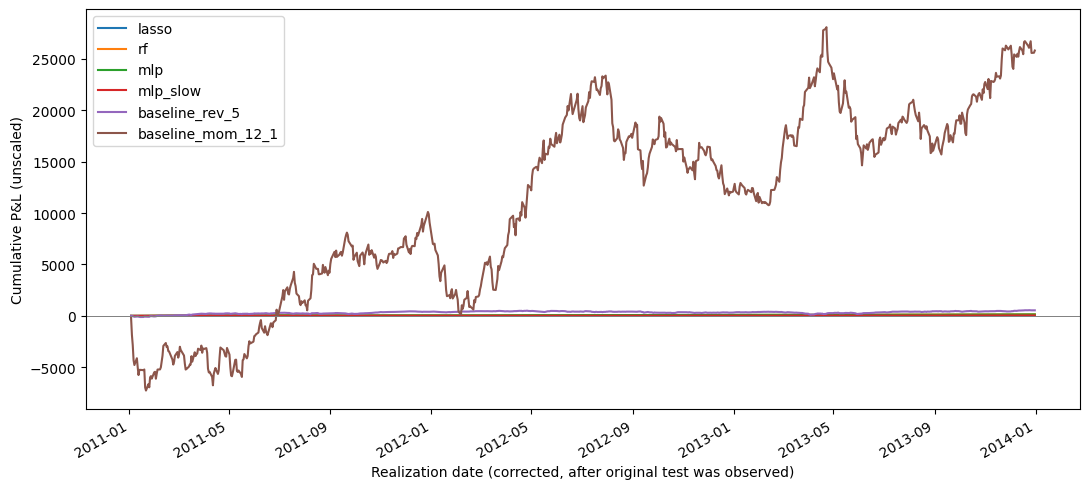

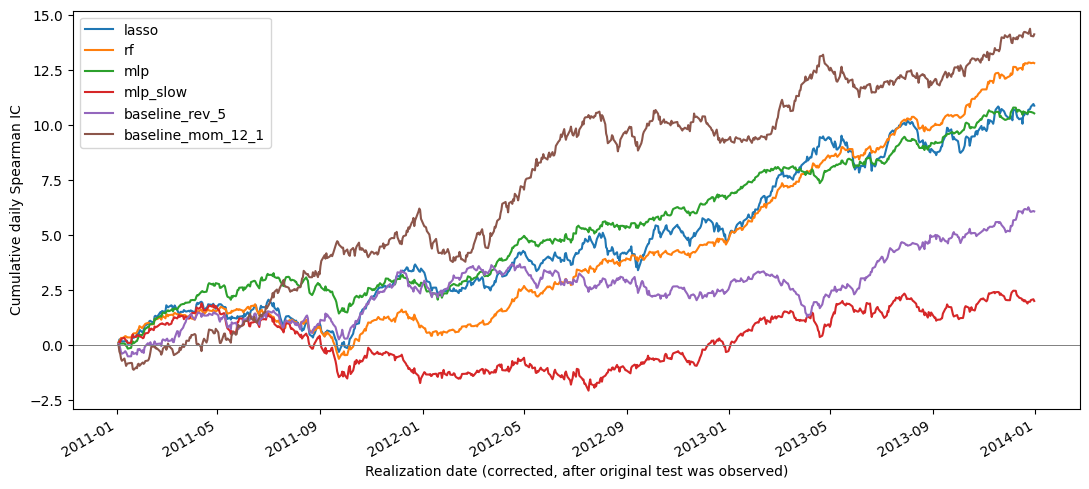

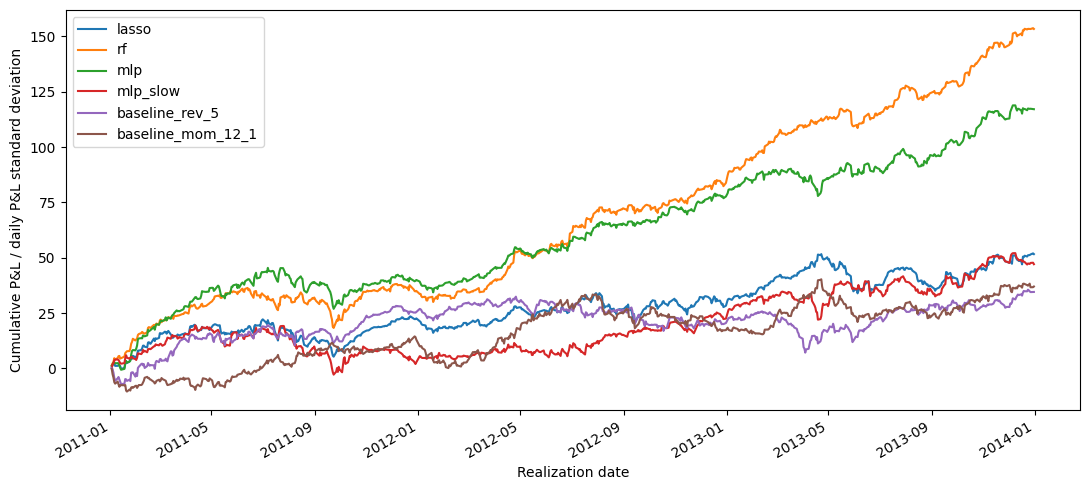

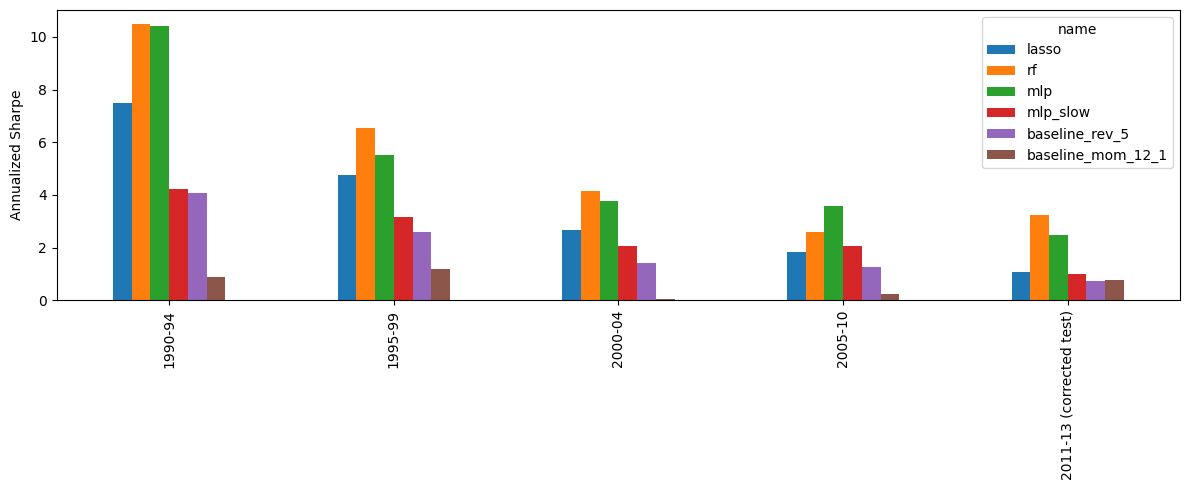

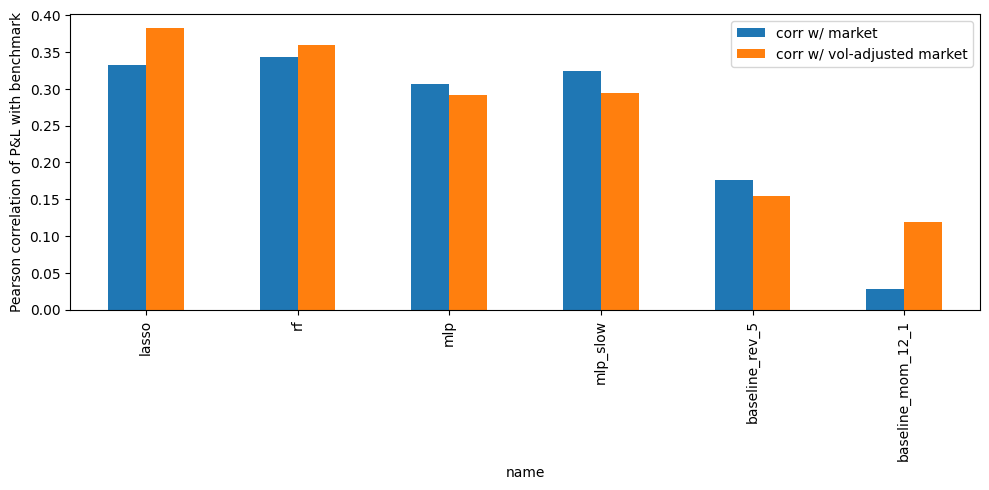

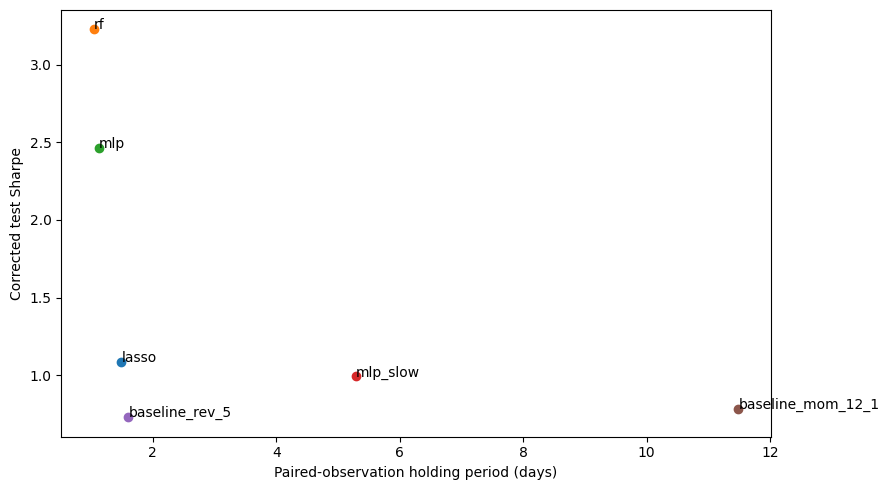

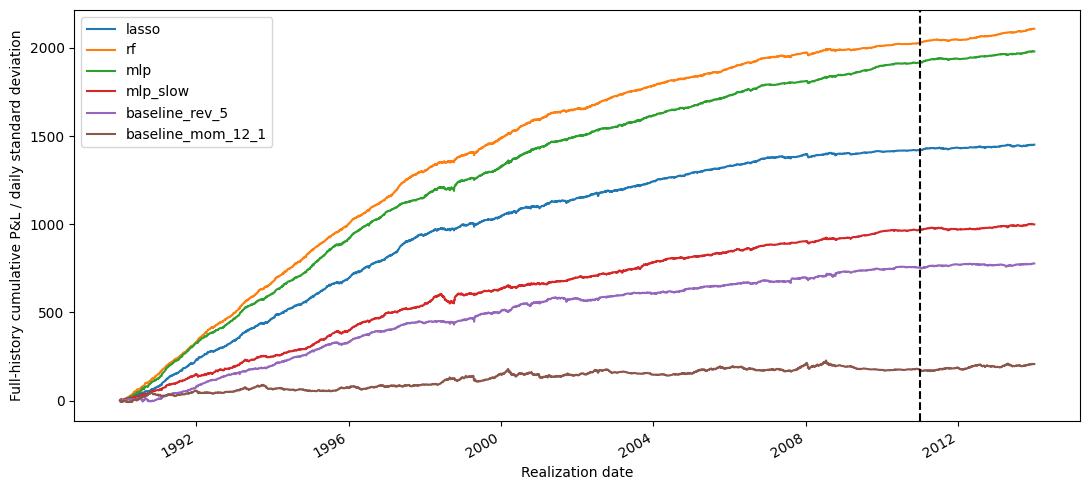

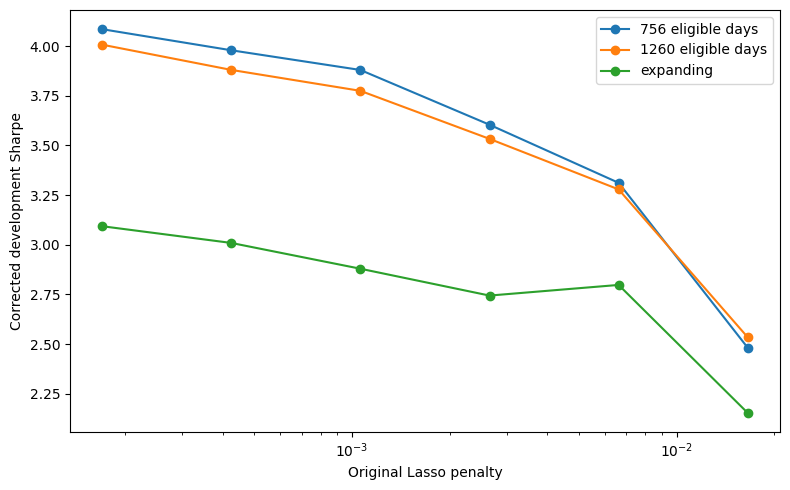

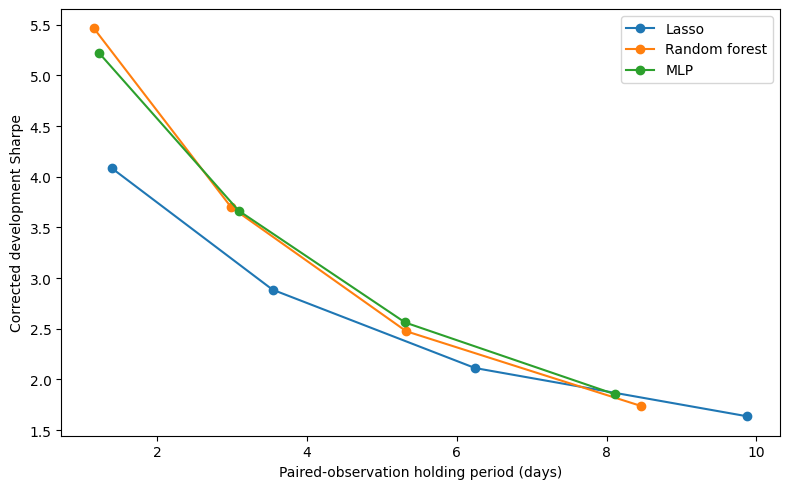

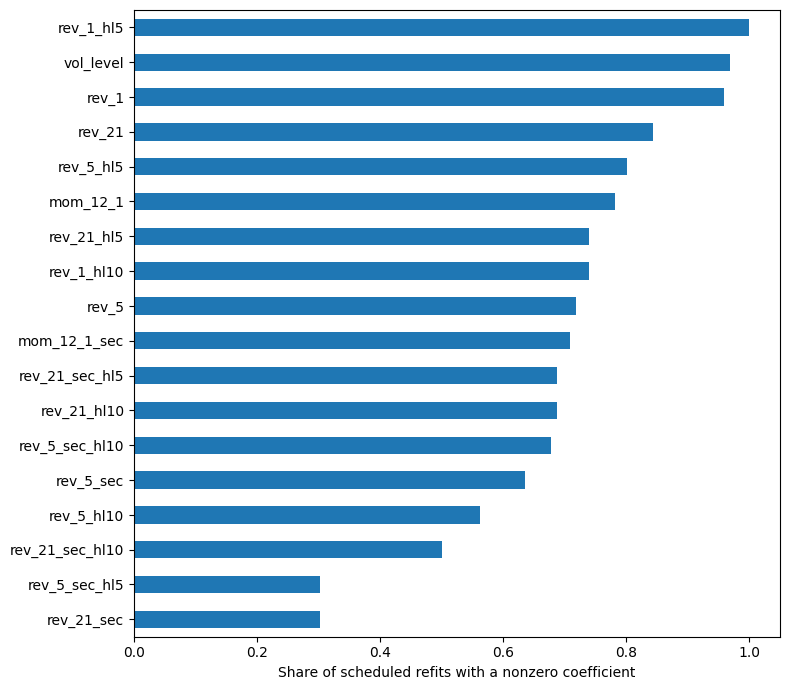

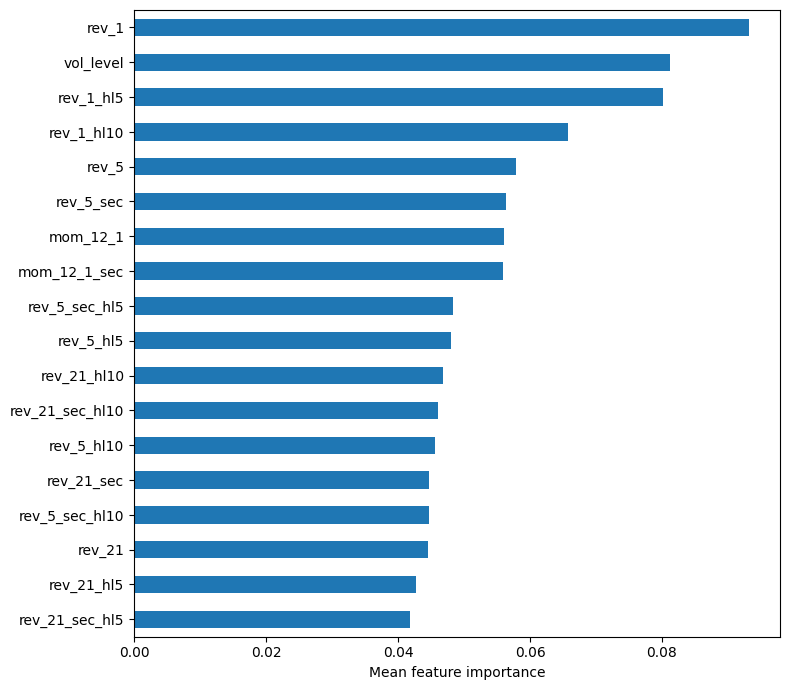

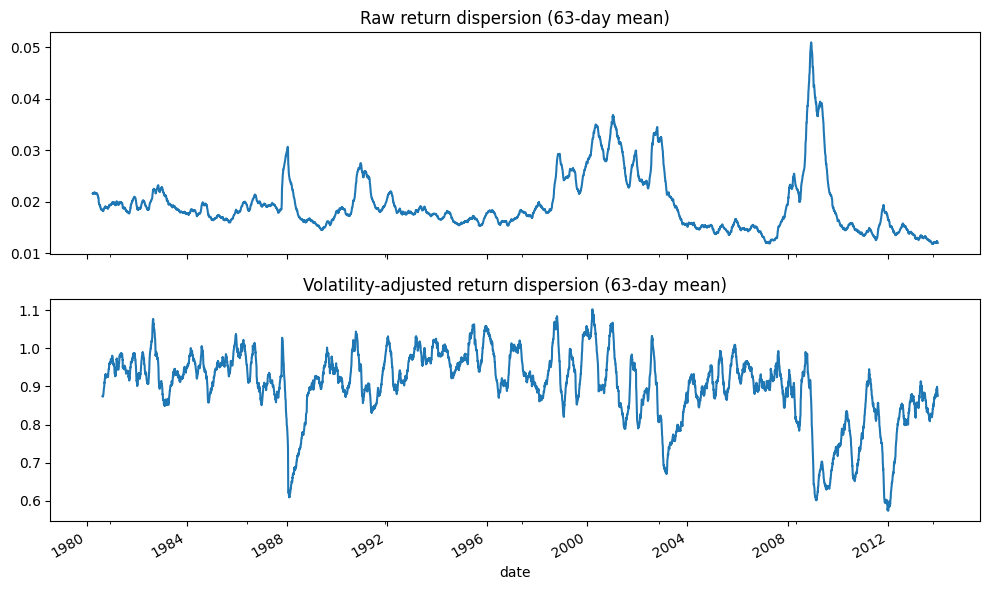

[PosixPath('results/corrected_v2/figures/test_pnl.pdf'),
 PosixPath('results/corrected_v2/figures/test_ic.pdf'),
 PosixPath('results/corrected_v2/figures/test_pnl_normalized.pdf'),
 PosixPath('results/corrected_v2/figures/sharpe_by_window.pdf'),
 PosixPath('results/corrected_v2/figures/benchmark_correlations.pdf'),
 PosixPath('results/corrected_v2/figures/sharpe_vs_holding.pdf'),
 PosixPath('results/corrected_v2/figures/full_pnl_normalized.pdf'),
 PosixPath('results/corrected_v2/figures/lasso_grid.pdf'),
 PosixPath('results/corrected_v2/figures/smoothing_tradeoff.pdf'),
 PosixPath('results/corrected_v2/figures/lasso_features.pdf'),
 PosixPath('results/corrected_v2/figures/rf_features.pdf'),
 PosixPath('results/corrected_v2/figures/volatility_adjustment.pdf')]

In [20]:
plot_corrected(OUT, show=True)

## AI assistance: original prompt and experiment history
The following is the original Claude agent prompt and historical log, included verbatim for disclosure. Its old protocol and instructions are historical context, superseded by the corrected protocol above. Claims in that historical log are attributed records of the original work, not new verification by ChatGPT.

# Task 3 Agent Prompt (ECSE 551, Assignment 1)

You are working in our group's repository for ECSE 551 Assignment 1, Task 3: predicting next-day volatility-adjusted returns of S&P 500 stocks from historical returns and sentiment signals.

Your job is to run a careful, honest experimental study under a fixed protocol. You are NOT optimizing for the highest possible number. A negative result is acceptable and must be reported honestly. Every member of our group will be questioned individually in an oral demo about every line of code and every result, so clarity and correctness matter more than cleverness.

Before doing anything else, read this entire file, then reply with a short plan and any questions. Do not start Phase 0 until we answer.

---

## 0. Ground rules (apply throughout, no exceptions)

1. **Frozen harness.** After Phase 0, `src/task3_data.py` and `src/task3_eval.py` are frozen. You may import them but never edit them. At every checkpoint, run `git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py` and show us the output. It must be empty. If you believe the harness has a bug, stop and tell us; do not fix it yourself.

2. **Test set lockout.** The test period is 2011-01-01 to 2013-12-31. During Phases 1 and 2 you must never compute any metric, plot, or statistic on test-period predictions or test-period returns. All model selection and hyperparameter tuning uses the development period only. The test period is evaluated exactly once, in Phase 3, only for finalists we approve, and only after the frozen configurations have been committed.

3. **No lookahead.** A prediction made at the close of day t may use only information available at the close of day t. Concretely:
   - Features at row t may only use data from rows up to and including t.
   - The training target for row s is the clipped vol-adjusted return on day s+1. That return is only known at the close of s+1. Therefore a model used to predict on day t may only be trained on rows s <= t-1. Enforce this with an `assert` in the training code, not just a comment.
   - Sentiment follows the timing rule in Section 2.5.
   - Leakage tests in Phases 1 and 2 are mandatory.

4. **Experiment log.** Every configuration you evaluate (including failed runs, controls, and anything you abandon) gets one row appended to `results/experiment_log.csv`. Never delete or edit rows. Columns: `exp_id, timestamp, phase, model, features, hyperparams, target_variant, demean, pred_smoothing_halflife, refit_every, train_window, dev_sharpe, dev_sharpe_1990_1999, dev_sharpe_2000_2010, mean_ic, ic_tstat, holding_period, corr_market, min_preds_per_day, runtime_s, notes`. We will report the total number of configurations tried, because that is the multiple-testing context for any result.

5. **Scope.** Only the model families the assignment asks for: sparse linear regression (Lasso), a basic MLP, and a random forest, plus the simple rule-based baselines listed below. scikit-learn implementations are allowed for Task 3. No gradient boosting libraries, no deep learning frameworks, no external data.

6. **Code we can explain.** Plain functions with short docstrings that say what the function does and why. Comments on every line that involves a time shift (`shift`, `rolling`, `ewm`, date slicing), stating which days the value depends on. No class hierarchies, decorators, or clever pandas one-liners where a clear three-line version exists. Keep each module under about 300 lines. Fixed random seed 42 everywhere. The final submission is a single notebook, so modules must be self-contained enough to paste into notebook cells.

7. **Checkpoints.** At the end of each phase, stop: summarize what you did in plain language, show results, list any decisions you made and why, show the frozen-harness diff, then end your turn and wait for us to reply "continue". Do not start the next phase on your own.

8. **Git hygiene.** Commit locally at the end of each phase with message `task3 phase N: <summary>`. Never commit anything in `data/`. Never push, force, rebase, or rewrite history.

9. **Boundaries.** Do not modify files for Tasks 1 and 2, the `report/` folder, or `notebooks/task3.ipynb`. Use the current Python environment; ask before installing any package.

10. **When in doubt, stop and ask.** If a rule blocks something you think is necessary, explain the problem instead of working around it.

11. **Running record.** Maintain `results/AGENT_LOG.md` throughout: each decision with its reason, each problem with its fix, and each question you asked us with our answer. This file is cited in our report.

---

## 1. Repository layout

```
data/                    CSVs (gitignored, read-only for you)
notebooks/task3.ipynb    our verified exploration, source of truth for Section 2 (do not edit)
src/                     modules (you create task3_*.py here)
tests/                   tests (you create)
results/                 logs, tables, figures (you create)
AGENT_PROMPT.md          this file
```

---

## 2. Established pipeline (built and verified by us)

`notebooks/task3.ipynb` contains our verified implementation of everything in this section. When extracting it in Phase 0, copy the logic exactly.

### 2.1 Data facts

- `eq_returns.csv`: rows are trading days (8577 days, 1980-01-02 to 2013-12-31), columns are permnos plus a `date` column. Values are daily excess returns as decimals.
- `eq_indicator.csv`: same shape. 1 if the stock is an S&P 500 member that day, else 0. About 500 members per day (min 489).
- `eq_stock_metadata.csv`: `permno, cname, gics` (8-digit GICS; sector = first 2 digits).
- `psych_bullish.csv`, `psych_bearish.csv`: rows are CALENDAR days (weekends included) starting 2009-07-10. Columns are permnos (606 stocks). NaN most likely means no messages that day, which is different from a score of 0.
- `psych_stock_metadata.csv`: `permno, ticker` (not needed for joining).

### 2.2 Cleaning (already decided, reproduce exactly)

- 21 permnos appear twice as column headers. pandas renames the second copy `XXXX.1`. We rename it `XXXX_b` and treat it as a distinct security, because the two series are never identical (correlation 0.06 to 0.47 on overlapping days) and are often both members on the same day. The metadata has matching duplicate rows in the same order; the second occurrence gets id `XXXX_b`.
- 21 columns with no data at all are dropped, leaving 1314 securities.
- Stock ids stay strings throughout (`"12431_b"` is not an integer).
- Non-member days have returns for about 255 stocks per day (2,190,592 cells). These are used ONLY for volatility estimation and feature construction, never as training targets, predictions, or evaluation. The dataset only contains stocks that were members at some point in 1980 to 2013, so training on pre-inclusion days would leak future index membership.

### 2.3 Volatility adjustment

Per stock, every day, in this order (EWMA filters, assignment eqs. (2) and (3)):

```
mu_t     = (1 - beta2) * r_t + beta2 * mu_{t-1}
a_t      = r_t - mu_t
sigma2_t = (1 - beta1) * a_t^2 + beta1 * sigma2_{t-1}
vadj_t   = r_t / sigma_{t-1}          # note t-1: implemented as sig.shift(1)
```

beta1 = 0.97, beta2 = 0.99, initial variance 0.02**2, burn-in of 100 observations per stock (sigma is NaN before that), state carried forward unchanged on NaN days.

### 2.4 Targets, masks, and evaluation

- `vadj_c = vadj.clip(-5, 5)`: for features and training targets only.
- `Y = vadj.shift(-1)`: UNclipped, for evaluation only. `Y[t]` is the realized vol-adjusted return on day t+1, earned by a prediction made at the close of day t.
- `mem = ind.astype(bool)`.
- `evaluate(P, start, end, windows, demean, label, plot)`: takes a prediction DataFrame `P` (dates x stocks, `P[t]` = prediction made at close of day t), restricts to members on day t, optionally demeans each day, and reports: annualized Sharpe of the daily P&L `sum_i P[t,i] * Y[t,i]`, Sharpe by year and by window, mean daily Spearman rank IC and its t-stat, cumulative P&L and cumulative IC plots, average holding period (assignment eq. (7), stocks with at least 20 predictions), correlation of the P&L with an equal-weight long-only portfolio of members, and the minimum number of predictions per day.

### 2.5 Sentiment timing rule

Sentiment for calendar day d may contain posts made after that day's market close. To be safe, sentiment dated d is first usable for the prediction made at the close of the first trading day STRICTLY AFTER d. Sentiment from non-trading days (weekends, holidays) is aggregated into that same first usable trading day. Example: Friday, Saturday, and Sunday sentiment all become usable at Monday's close; Monday's sentiment becomes usable at Tuesday's close.

Of the 19 duplicated permnos that remain, check which have sentiment columns. For each one, if exactly one of the two securities has returns during the sentiment period, map the sentiment to that one. If both do, exclude sentiment for both. Log what you did in `AGENT_LOG.md`.

---

## Phase 0: Extract, verify, freeze (then STOP)

1. Create `src/task3_data.py` with `load_data()`, `ewma_vol()`, and `build_targets()` (returning `ret, ind, meta, sig, vadj, vadj_c, Y, mem`), copying the logic from the notebook. The only allowed change is turning globals into function arguments or return values.
2. Create `src/task3_eval.py` with `sharpe()` and `evaluate()`, copied from the notebook. Same allowed change only: `Y` and `mem` become arguments.
3. Create `tests/test_task3_pipeline.py` that checks these values reproduce (tolerance 1e-3 relative unless exact):

   | Check | Expected |
   |---|---|
   | duplicated permno columns renamed `_b` | 21 |
   | empty columns dropped | 21 |
   | securities remaining | 1314 |
   | metadata index equals return columns | True |
   | mean members per day / min | 499.79 / 489 |
   | member cells with NaN return | 0 |
   | non-member cells with a return | 2,190,592 |
   | non-NaN vol-adjusted returns on member cells | 4,227,347 |
   | std of those | 1.0574 |
   | excess kurtosis | 22.75 (tolerance 0.05) |
   | fraction with abs value > 5 | 0.00076 |

4. Run the harness controls on 2011-01-01 to 2013-12-31 (this is the one allowed use of the test period before Phase 3, because these controls contain no model): perfect-foresight `P = Y` must give an absurd Sharpe (above 50); i.i.d. N(0,1) predictions with seed 42 must give an absolute Sharpe below 1.5; always-long `P = 1` must give market correlation above 0.9. Report the 5-day reversal baseline (`-vadj_c.rolling(5, min_periods=3).mean()`, demeaned) over 1985 to 2010 only.
5. Commit, write the commit hash to `results/FROZEN_COMMIT.txt`, commit that file too, and STOP with an expected-vs-actual table.

---

## Phase 1: Features and leakage tests (then STOP)

Create `src/task3_features.py`. All features are computed per stock from data up to and including row t, then transformed cross-sectionally each day among members: rank, scaled to [-0.5, 0.5]. Missing values after ranking become 0 (neutral); log the fraction filled per feature.

Return-based features (from `vadj_c` and `sig`):
- `rev_1`: vadj_c on day t
- `rev_5`: mean of vadj_c over days t-4..t
- `rev_21`: mean over t-20..t
- `mom_12_1`: sum over t-251..t-21 (skips the most recent month)
- `vol_level`: log(sig_t)
- sector-relative versions of `rev_5`, `rev_21`, `mom_12_1`: subtract the same-day mean among members of the same GICS sector (first 2 digits), before ranking
- smoothed versions: EWMA over time of the ranked feature with half-lives 5 and 10 days

Sentiment features (from 2009-07 onward, Section 2.5 timing): bullish, bearish, net = bullish - bearish, activity = bullish + bearish, each also EWMA-smoothed with half-lives 5 and 21 days, plus a 0/1 availability flag.

Leakage tests in `tests/test_leakage.py` (mandatory):
- **Truncation test:** for 20 random dates t (seed 42) spread across 1985 to 2010, recompute all features using only data up to t (returns, and sentiment respecting the timing rule) and assert row t matches the full-data computation to 1e-10.
- **Training-window assertion:** a unit test showing the training function raises an error if given any row s >= t when predicting on day t.

STOP with a feature table: name, formula, lookback in days, first available date, mean coverage among members.

---

## Phase 2: Walk-forward experiments on the development period (then STOP)

### Protocol

- **Training data:** member rows only. Target = `vadj_c.shift(-1)`, cross-sectionally demeaned each day (default), or raw (one variant only).
- **Walk-forward:** at each refit date d, fit on rows s in [d - window, d - 1], then predict every day from d until the next refit. Refit every 63 trading days for Lasso and every 252 trading days for random forest and MLP (compute budget). Training windows: 3 years, 5 years, expanding (try on Lasso; pick one for RF/MLP and log why).
- **Development period:** predictions from 1990-01-01 to 2010-12-31. Selection metric: dev Sharpe of demeaned predictions, but prefer configurations that are consistent across the windows 1990-1994, 1995-1999, 2000-2004, 2005-2010 over ones with a higher total driven by one window. Report holding period for everything.
- **Sentiment models:** sentiment starts 2009-07, so their development window is 2010-01-01 to 2010-12-31 with expanding training from 2009-07. That is very little data: use a tiny grid (at most 6 configurations) and flag the limitation clearly.
- **Coverage:** at least 100 predictions per day; report the minimum.

### Models

- Baselines: 5-day reversal, 12-1 momentum (rule-based, no fitting).
- Lasso (`sklearn.linear_model.Lasso`): alpha grid of about 6 values on a log scale. Record which coefficients are nonzero at each refit.
- Random forest (`RandomForestRegressor`): `n_estimators=100`, `max_depth` in {4, 6, 8}, `min_samples_leaf` in {200, 1000}, subsample 200,000 training rows per fit (seed 42), `n_jobs=-1`.
- MLP (`MLPRegressor`): one hidden layer of 16 or 32 units, alpha in {1e-4, 1e-2}. Do NOT use `early_stopping=True`: it splits randomly, which mixes future and past. Instead, choose the number of epochs with a time-ordered holdout (the most recent 20% of each training window by date).
- Post-processing variants on the best configurations: demean on/off, and EWMA smoothing of predictions over time with half-life in {0, 2, 5, 10} days to show the Sharpe vs holding-period trade-off.

### Budget and controls

- At most about 60 configurations in total for Phase 2. Every one goes in the log.
- **Positive control:** take one Lasso configuration and shift its features one day into the future (`shift(-1)`). The dev Sharpe must jump dramatically. This proves the pipeline is sensitive to leakage.
- **Negative control:** same configuration, but permute training targets across stocks within each day. Dev Sharpe should be near 0.
- Controls are logged but never eligible for selection.
- If any single configuration takes more than about 15 minutes, reduce cost (fewer refits, smaller subsample), log it, and continue.

STOP with: the full results table sorted by dev Sharpe, windowed Sharpe for the top configurations, the control results, and a proposal of at most 4 finalists (at least one Lasso, one random forest, one MLP, and a sentiment variant only if it looks viable), each with a short justification. Save figures to `results/figures/` as PDF with large fonts (at least 14 pt).

---

## Phase 3: Freeze, then test once (only after we approve the finalists)

1. Write the approved finalists to `results/final_configs.json` and commit with message `task3: freeze finalists` BEFORE running anything on the test period.
2. Run walk-forward predictions through 2013-12-31 with the same rules (training on rows up to t-1, same refit schedule) and evaluate each finalist plus the two baselines on 2011-01-01 to 2013-12-31, exactly once. Save to `results/test_results.csv`.
3. Do not change any configuration after seeing test results. If you discover a bug, stop and tell us; any fix and re-run must be disclosed in `AGENT_LOG.md` and the experiment log.
4. Also produce full walk-forward curves for 1990 to 2013, clearly marking 1990 to 2010 as the development period (used for selection, so not truly out-of-sample).
5. Figures (PDF, large fonts): cumulative P&L on the test period for all finalists and baselines; cumulative rank IC on the test period; Sharpe by window as a bar chart; Sharpe vs holding period scatter over all dev configurations plus finalists; Lasso nonzero-coefficient frequency across refits; random forest feature importances.

---

## Phase 4: Write-up support (then STOP)

1. `results/SUMMARY.md`: protocol, every number we need for the report, and an honest interpretation. Compare against the assignment's rough benchmarks: Sharpe of 0.6 or more is interesting for long holding periods, about 2 for one-day holding periods; standard error of the Sharpe is roughly 1/sqrt(years), so about 0.58 for the 3-year test period. State limitations plainly.
2. `results/EXPLAIN.md`: a walkthrough of every function in `src/task3_*.py`, in plain language, followed by about 15 likely demo questions with concise answers (e.g. why sigma_{t-1}, why train only on rows up to t-1, why demean, why rank features, what the controls show).
3. `notebooks/task3_agent.ipynb`: imports the modules and reproduces every final table and figure top to bottom, with outputs saved.
4. Final checks: frozen-harness diff empty, total configuration count from the log, all tests passing. Commit and STOP.

# Task 3 agent log

Running record of decisions, problems, and questions for ECSE 551 Assignment 1, Task 3.
Entries are added in order and never rewritten. Dates are in 2026.

## Commit hashes (made by a group member, not by the agent)

| What | Hash |
|---|---|
| Phase 0 frozen harness (`src/task3_data.py`, `src/task3_eval.py`) | `cceeb15e720d5b637c2082d1da9a74c5f101496a` |
| Phase 3 frozen finalists (`results/final_configs.json`) | `f817d04c028b0cec2b804a5cfde2a4ca89df9564` |

## Environment

Conda `base`, Python 3.14.6, macOS, 8 cores, 8 GB RAM. Packages installed with pip on Oct 9 with the group's permission:

| Package | Version |
|---|---|
| numpy | 2.4.6 |
| pandas | 3.0.5 |
| scipy | 1.17.1 |
| scikit-learn | 1.9.0 |
| matplotlib | 3.11.1 |
| pytest | 9.1.1 (already present) |
| nbformat | 5.11.1 |
| ipykernel | 7.4.0 |

## Before Phase 0 (Oct 9)

The agent read `AGENT_PROMPT.md`, inspected the repository and `notebook/task3.ipynb` without changing anything, and asked four questions.

### Questions and answers

| # | Question | Answer |
|---|---|---|
| Q1 | The prompt requires perfect-foresight Sharpe above 50, but the notebook's own output is 16.6 on 2011-2013. Lower the threshold (suggested: above 10)? | Not answered in chat yet. Phase 0 reports the result against the threshold as written. See Problem 1. |
| Q2 | The current environment has no scikit-learn. May I use the `ecgfm` conda environment that the notebook used? | No. Stay in the current environment; installing numpy, pandas, scipy, scikit-learn, matplotlib, pytest, nbformat and ipykernel is allowed. Versions recorded above. |
| Q3 | The prompt says `notebooks/`, the repository has `notebook/`. Keep `notebook/`? | Not answered in chat yet. Nothing renamed. |
| Q4 | The repository has no commits. What goes in the first commit? | The agent never stages, commits, or pushes. At each commit point it lists the files, suggests a message, and waits. A group member commits and sends back the hash. In Phase 3 nothing runs on the test period until the group confirms `final_configs.json` is committed and gives its hash. |

### Defaults proposed by the agent, all accepted

1. `evaluate(P, Y, mem, start, end, windows, demean, label, plot)`: `Y` and `mem` become the second and third arguments, body unchanged.
2. In Phases 1 and 2 every coverage statistic, fill fraction and prediction stops at 2010-12-31, including sentiment. The Phase 0 pipeline checks use the full history because the expected values require it.
3. The log has two window columns (1990-1999, 2000-2010). The four selection windows per configuration are saved separately in `results/dev_windows.csv`.
4. Lasso alpha grid: six log-spaced values chosen from the first training window only.
5. The expanding training window starts on the first date all return features exist (about mid-1981).
6. MLP epochs are chosen on the most recent 20% of each training window by date, then the model is refit on the whole window with that number of epochs.

## Phase 0 (Oct 9)

### What was done

- `src/task3_data.py`: `load_data()`, `ewma_vol()`, `build_targets()`, copied from notebook cells 1 to 3.
- `src/task3_eval.py`: `sharpe()`, `evaluate()`, copied from notebook cell 3.
- `src/task3_log.py`: `append_log()`, an append-only writer for `results/experiment_log.csv`.
- `src/task3_phase0.py`: the four harness controls.
- `tests/test_task3_pipeline.py`: 12 tests, all passing.

### Decisions

| # | Decision | Reason |
|---|---|---|
| D1 | Package versions pinned to the ones in the notebook's environment (numpy 2.4.6, pandas 3.0.5, scipy 1.17.1, scikit-learn 1.9.0, matplotlib 3.11.1). | The notebook's numbers were verified with those versions, so the extraction can be checked exactly. |
| D2 | The notebook's exploratory `print` calls in the loading cell were not copied into `load_data()`. | They are checks, not logic. The same checks are now assertions in the pipeline test. |
| D3 | `data_dir` is an argument of `load_data()` and `build_targets()`, default `"data"` (repository root). | The notebook used the global `DATA = Path("../data")`. Turning a global into an argument is the one change the prompt allows. |
| D4 | The scripts select the matplotlib `Agg` backend themselves; the harness is untouched. | `evaluate()` calls `plt.show()`, which would open a window and block a script. |
| D5 | The Phase 0 controls are logged as rows E001 to E004 with `phase = 0` and an empty `dev_sharpe`. Their Sharpe is in the `notes` column. | They are not development-period results (three are on the test period, one on 1985-2010), so they must not look like candidates. |
| D6 | The test for "fraction above 5" uses an absolute tolerance of 5e-6 instead of 1e-3 relative. | The expected value 0.00076 is given to two significant digits; the computed value is 0.000755. |

### Problems

**Problem 1: perfect-foresight control is below the prompt's threshold.** `P = Y` gives Sharpe 16.598 on 2011-2013, identical to the notebook, but the prompt requires above 50. The harness was copied unchanged and was not modified. The value is far beyond any realistic strategy (rank IC is exactly 1.0), so the control still shows that predictions and returns are aligned. It cannot reach 50 because the daily P&L is the sum of squared returns across stocks, which varies a lot from day to day. Status: reported as failing the threshold as written; waiting for the group to set the threshold.

**Problem 2: the notebook's tail fractions use the wrong denominator.** The notebook reports that 0.076% of member vol-adjusted returns exceed 5 in absolute value. That number divides by all 8577 x 1314 = 11,270,178 cells, because in pandas 3 `.stack()` keeps NaN cells (non-members and burn-in days). Among the 4,227,347 actual member values the fraction is 8,509 / 4,227,347 = 0.201%. The same applies to the other two thresholds:

| Threshold | Count | Notebook (all cells) | Among member values |
|---|---|---|---|
| abs > 3 | 55,538 | 0.493% | 1.314% |
| abs > 5 | 8,509 | 0.076% | 0.201% |
| abs > 10 | 933 | 0.008% | 0.022% |

This is in an exploratory print only. The harness, the count, the standard deviation and the kurtosis are not affected (those functions skip NaN). The test asserts both numbers. Status: reported to the group; the report draft currently quotes 0.08%.

### Phase 0 results: pipeline checks

| Check | Expected | Actual | Pass |
|---|---|---|---|
| duplicated permno columns renamed `_b` | 21 | 21 | yes |
| empty columns dropped | 21 | 21 | yes |
| securities remaining | 1314 | 1314 | yes |
| metadata index equals return columns | True | True | yes |
| mean members per day | 499.79 | 499.7938 | yes |
| min members per day | 489 | 489 | yes |
| member cells with NaN return | 0 | 0 | yes |
| non-member cells with a return | 2,190,592 | 2,190,592 | yes |
| non-NaN vol-adjusted returns on member cells | 4,227,347 | 4,227,347 | yes |
| std of those | 1.0574 | 1.05744 | yes |
| excess kurtosis | 22.75 | 22.7496 | yes |
| fraction with abs value > 5 | 0.00076 | 0.000755 over all cells; 0.002013 over member values | yes, see Problem 2 |

### Phase 0 results: harness controls

| Control | Period | Expected | Actual | Pass |
|---|---|---|---|---|
| perfect foresight `P = Y`, Sharpe | 2011-2013 | above 50 | 16.598 | no, see Problem 1 |
| random N(0,1), seed 42, absolute Sharpe | 2011-2013 | below 1.5 | 0.314 | yes |
| always long `P = 1`, correlation with market | 2011-2013 | above 0.9 | 1.000 | yes |

### Phase 0 results: 5-day reversal baseline, demeaned, 1985-2010 only

| Metric | Value |
|---|---|
| Sharpe 1985-2010 | 2.327 |
| Sharpe 1985-1989 | 3.25 |
| Sharpe 1990-1994 | 4.09 |
| Sharpe 1995-1999 | 2.59 |
| Sharpe 2000-2004 | 1.39 |
| Sharpe 2005-2010 | 1.25 |
| mean rank IC | 0.0255 |
| IC t-stat | 18.49 |
| holding period (days) | 1.57 |
| correlation with market | 0.159 |
| min predictions per day | 493 |

The yearly Sharpes for 1985 to 2010 match the notebook's values exactly.

### Frozen-harness diff

Not yet possible: there is no commit to diff against. It will be run as soon as the group provides the Phase 0 hash.

## Phase 0 follow-up (Oct 9, after the checkpoint)

### Answers received

| # | Answer |
|---|---|
| Q1 | Confirmed: the perfect-foresight threshold is lowered from Sharpe above 50 to Sharpe above 10. |
| Q3 | Rename `notebook/` to `notebooks/`, as the prompt's layout assumes. |
| new | Add `__pycache__/` and `.DS_Store` to `.gitignore`. |

### Changes made

| # | Change | Reason |
|---|---|---|
| C1 | `src/task3_phase0.py`: the perfect-foresight check is now `Sharpe > 10` (was `> 50`), with a comment pointing here. | Group decision on Q1. The threshold only has to separate a leaking predictor from a realistic one; 16.6 with rank IC 1.0 does that. The evaluation code was not changed. |
| C2 | `results/phase0_controls.csv`: first row edited by hand from `> 50, False` to `> 10, True`. The measured Sharpe (16.598) is unchanged. | The controls were not re-run, because a second run would append four duplicate rows to the experiment log. |
| C3 | `notebook/` renamed to `notebooks/` with `mv`. `task3.ipynb` itself was not opened or edited. | Group decision on Q3. |
| C4 | The module docstrings of `src/task3_data.py` and `src/task3_eval.py` now say `notebooks/task3.ipynb`. No code line changed. | Follows C3. Done before the frozen commit, so the freeze is not affected. |
| C5 | `.gitignore` now contains `data`, `__pycache__/`, `.DS_Store`. | Group request. |

Problem 1 is closed by C1. Updated control row:

| Control | Period | Expected | Actual | Pass |
|---|---|---|---|---|
| perfect foresight `P = Y`, Sharpe | 2011-2013 | above 10 (lowered from 50) | 16.598 | yes |

The experiment log was not touched: rows E001 to E004 never recorded a threshold or a pass flag.

After these changes the 12 pipeline tests were run again and all pass.

## Phase 0 freeze (Oct 9)

A group member committed Phase 0 as `cceeb15e720d5b637c2082d1da9a74c5f101496a` ("task3 phase 0: initial commit with frozen harness"). The agent wrote that hash to `results/FROZEN_COMMIT.txt` and filled it into the table at the top of this file (the only earlier line changed).

From this commit on, `src/task3_data.py` and `src/task3_eval.py` are frozen. First frozen-harness check, run right after the hash was recorded:

```
$ git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py
(empty)
```

## Phase 1: features and leakage tests (Oct 9)

Started after the group replied "continue, phase 1 now". No model was fitted and no configuration was evaluated, so the experiment log is unchanged (4 rows).

### What was done

- `src/task3_features.py`: 24 return features and 13 sentiment features.
- `src/task3_train.py`: `fit_model()`, which asserts that every training row is dated strictly before the prediction date. Every Phase 2 fit will go through it.
- `src/task3_phase1.py`: writes `results/feature_table.csv` (statistics stop at 2010-12-31).
- `tests/test_leakage.py`: 6 tests, all passing (about 3 minutes).

### Decisions

| # | Decision | Reason |
|---|---|---|
| D7 | Windows: `rev_5` needs at least 3 of 5 values, `rev_21` at least 15 of 21, `mom_12_1` all 231. | `rev_5` then equals the group's 5-day reversal baseline. A mean with a few missing days is still comparable; a partial sum is not. Gaps are rare (5,231 cells in total up to 2010). |
| D8 | All 8 base return features get smoothed versions (half-lives 5 and 10), giving 24 return features. | Literal reading of the prompt. See Problem 4 for the six that are near-duplicates. |
| D9 | Smoothing is applied to the ranked feature AFTER missing ranks are set to 0, using the plain recursion `s[t] = a x[t] + (1 - a) s[t-1]`. | One rule for all features. A stock with no recent information drifts back to neutral instead of keeping a stale value forever, which matters for sentiment (90% missing). Cost: a stock that just joined the index has smoothed features shrunk toward 0 for its first days. |
| D10 | Smoothed features are not re-ranked. | The prompt says "EWMA over time of the ranked feature". They stay inside [-0.5, 0.5]. |
| D11 | A stock alone in its sector on a given day gets a sector-relative value of 0. Three GICS sector codes (18, 28, 46) contain one stock each. | Its value minus its own mean is 0, which ranks near the middle. |
| D12 | Sentiment from several calendar days landing on the same trading day is averaged, ignoring NaN. | The scores are intensities between 0 and 4, so a mean keeps Monday on the same scale as other days. A sum would make Monday about three times larger. |
| D13 | `sent_net` and `sent_act` are NaN when the stock had no messages. | Up to 2010 bullish and bearish are always missing together, and 0 is a real score (9,370 bullish zeros, 24,165 bearish zeros), so NaN is never treated as 0 before ranking. |
| D14 | `sent_flag` stays 0/1 and is not ranked. | It is already on a fixed scale. |
| D15 | Sentiment features are stored only for trading days from 2009-07-13 on. | Nothing exists before; saves memory. |
| D16 | Features are stored as float32. | 37 tables of 8577 x 1314 would need 3.3 GB in float64 on an 8 GB machine. A rank among 500 stocks needs three digits. The truncation test still passes at 1e-10. |
| D17 | Truncation test dates: one random day from each of 20 equal blocks of 1985-2010 (seed 42), which guarantees the spread. Plus 30 extra random days in 2009-07 to 2010 for sentiment only. | Sentiment exists for only 1.5 of the 26 years, so plain random dates would test it once at most. With the blocks, one of the 20 dates falls in the sentiment period; the 30 extra dates include Mondays. |
| D18 | Three tests beyond the two mandatory ones: the truncation check must fail on a deliberately leaky feature; the Friday/Saturday/Sunday example of Section 2.5 on a toy table; `mom_12_1` must ignore days t-20..t and day t-252. | A leakage test is only convincing if it is shown to catch a leak, and the two trickiest time shifts get an explicit check. |

### Sentiment mapping for duplicated permnos

606 sentiment columns. 18 belong to securities dropped as empty. 572 are ordinary permnos. Of the 19 duplicated permnos that remain, 16 have a sentiment column:

| Action | Permnos |
|---|---|
| mapped to the first security (only it has returns) | 48653, 77157, 79129 |
| mapped to the `_b` security (only it has returns) | 25232, 25582, 32707, 46703 |
| excluded, both have returns | 12431, 23536, 79237, 90537 |
| unused, neither has returns in the sentiment period | 12650, 19166, 21979, 45356, 79057 |

In total 579 columns are mapped to an equity id.

### Problems and disclosures

**Problem 3: the sentiment mapping looks at whether returns exist after 2010.** The group's rule says "has returns during the sentiment period", which runs to 2013. The function therefore checks whether each of the two securities has any return from 2009-07-10 on, test period included, and during exploration the agent printed the number of non-NaN return cells per duplicated permno for 2009-07 to 2010 and for 2011 to 2013. No return value, statistic or prediction from the test period was looked at. It changes one case: for 12431 the second security only has returns from 2011, so with data up to 2010 the sentiment would be mapped to the first one, and with the full period it is excluded. The effect is to remove information (31 member-days up to 2010), not to add any. The mapping is a fixed cleaning step, like dropping the 21 empty columns, and is the one input the truncation test does not recompute.

**Problem 4: six smoothed features are near-duplicates of their base feature.** Correlation with the base feature over member cells, 1990-2010: `mom_12_1_hl5` 0.98, `mom_12_1_hl10` 0.97, `vol_level_hl5` 0.99, `vol_level_hl10` 0.97, and the same 0.98 / 0.97 for the two smoothed `mom_12_1_sec`. The base features already move slowly, so smoothing them changes little. Lasso will pick between near-identical columns almost arbitrarily, which makes the "which coefficients are nonzero" table harder to read. Status: kept, question put to the group.

**Problem 5: sentiment is sparse.** In 2010 only 270 of 500 members have a sentiment column at all, and on an average day only 12% of members (about 60 stocks) have a usable score. The raw sentiment features are 0 for the other 88%. Smoothed versions are nonzero for 51%. This is below the 100 predictions per day the protocol asks for if a model used raw sentiment alone, so sentiment can only be an addition to the return features. Status: reported.

**Limitation: sector codes are static.** The metadata gives one GICS code per security for the whole of 1980-2013, and GICS did not exist before 1999. The sector-relative features in the early years therefore use a classification assigned later. This is a property of the data provided; it is not something the truncation test can detect.

**Fix during the phase:** the first run of the truncation test crashed for dates before 2009-07 because the truncated sentiment table was empty. The test now checks that no sentiment is dated before such a date and skips the recomputation. `task3_features.py` was not changed.

**Fix during the phase:** the first version of the feature table had an empty correlation column, because `.stack()` keeps NaN in pandas 3 (the same cause as Problem 2). It now uses a boolean mask.

### Feature table (statistics up to 2010-12-31)

Coverage is the share of members with a real, not filled, value, averaged from the first available date to 2010-12-31. For smoothed features it is the share of members whose value is not exactly 0. Fill fraction is 1 minus coverage. Full table with formulas: `results/feature_table.csv`.

| Feature | Lookback (trading days) | First available | Mean coverage | Fill fraction |
|---|---|---|---|---|
| `rev_1` | 1 | 1980-05-23 | 0.9978 | 0.0022 |
| `rev_5`, `rev_5_sec` | 5 | 1980-05-28 | 0.9978 | 0.0022 |
| `rev_21`, `rev_21_sec` | 21 | 1980-06-13 | 0.9975 | 0.0025 |
| `mom_12_1`, `mom_12_1_sec` | 252 | 1981-05-22 | 0.9869 | 0.0131 |
| `vol_level` | all past, 100-day burn-in | 1980-05-22 | 0.9979 | 0.0021 |
| smoothed return features (`_hl5`, `_hl10`) | base + EWMA | same as base | same as base (momentum: 0.9907) | same as base (momentum: 0.0093) |
| `sent_bull`, `sent_bear`, `sent_net`, `sent_act`, `sent_flag` | 1 to 4 calendar days | 2009-07-13 | 0.0986 (2010 only: 0.1197) | 0.9014 |
| smoothed sentiment features (`_hl5`, `_hl21`) | base + EWMA | 2009-07-13 | 0.437 (2010 only: 0.515) | 0.563 |

The expanding training window (default 5) therefore starts on 1981-05-22.

### Tests

`tests/test_task3_pipeline.py`: 12 passed. `tests/test_leakage.py`: 6 passed. The truncation test passes at a tolerance of 1e-10 on all 20 + 30 dates; on the one date inspected by hand (2000-06-15) the largest difference was exactly 0.0.

### Frozen-harness diff at the Phase 1 checkpoint

```
$ git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py
(empty)
```

## Phase 1 follow-up (Oct 9, after the checkpoint)

### Instructions received

1. Drop the six near-duplicate smoothed features and use the remaining 18 return features.
2. Decide the duplicate-permno sentiment mapping using data up to 2010-12-31 only, and freeze it.
3. Re-run all tests, regenerate `results/feature_table.csv`, and stop.

### Changes made

| # | Change | Reason |
|---|---|---|
| C6 | Removed `mom_12_1_hl5`, `mom_12_1_hl10`, `mom_12_1_sec_hl5`, `mom_12_1_sec_hl10`, `vol_level_hl5`, `vol_level_hl10`. `task3_features.py` now smooths only the features listed in `RETURN_SMOOTHED` (`rev_1`, `rev_5`, `rev_21`, `rev_5_sec`, `rev_21_sec`). 18 return features remain: 8 base and 10 smoothed. | Group decision. The six had a correlation of 0.97 to 0.99 with their base feature (Problem 4), because momentum and volatility already move slowly. Near-identical columns would make the Lasso choice between them arbitrary. This replaces decision D8 and closes Problem 4. |
| C7 | `sentiment_column_map()` now checks for returns between 2009-07-10 and 2010-12-31 only (`SENT_MAP_END`). | Group decision, so that no decision depends on test-period data. This replaces the rule described in Problem 3. |
| C8 | The mapping is frozen in `results/sentiment_column_map.json`. A new test asserts that the function returns exactly that mapping, and that the result is identical when every row after 2010-12-31 is removed from the returns. | So the mapping cannot drift, and so its independence from the test period is checked, not just stated. |

### Disclosure on the earlier mapping rule

During Phase 1 exploration the agent printed, for each of the 16 duplicated permnos that have a sentiment column, the number of non-NaN return cells and the number of member days in 2011 to 2013, next to the same counts for 2009-07 to 2010. These are availability counts only. No return value, statistic, plot or prediction from the test period was viewed or computed. The first version of the mapping rule used that availability ("any return from 2009-07-10 on"). The rule was then changed (C7) so that no decision depends on test-period data.

The change affects one permno. 12431: the first security has returns in 2009-07 to 2010 and the second does not, so the sentiment is now mapped to `12431` (it was excluded under the first rule). The other 15 are unchanged.

Known consequence, stated because the availability counts were already seen: the second security `12431_b` starts trading during the test period, so from then on the sentiment column of permno 12431 stays attached to `12431` although two securities share the permno. This is accepted as the price of a rule that uses development data only.

### Frozen sentiment mapping (data up to 2010-12-31)

| Action | Permnos |
|---|---|
| mapped to the first security (only it has returns) | 12431, 48653, 77157, 79129 |
| mapped to the `_b` security (only it has returns) | 25232, 25582, 32707, 46703 |
| excluded, both have returns | 23536, 79237, 90537 |
| unused, neither has returns | 12650, 19166, 21979, 45356, 79057 |

580 of the 606 sentiment columns are mapped to an equity id (572 ordinary permnos and 8 duplicated ones).

### Regenerated feature table

31 features: 18 return and 13 sentiment. The return rows are unchanged apart from the six removed. The sentiment coverage moved slightly because of 12431: 0.0988 up to 2010 (was 0.0986) and 0.1200 in 2010 (was 0.1197).

### Tests

All 19 tests pass: 12 in `tests/test_task3_pipeline.py` and 7 in `tests/test_leakage.py` (the 6 from the checkpoint plus the new mapping test).

### Frozen-harness diff

```
$ git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py
(empty)
```

## Phase 2: walk-forward experiments on the development period (Oct 9)

Started after the group replied "continue". The Phase 1 commit is `e463be1`.

### What was done

- `src/task3_walkforward.py`: target, stacked panel of member rows, walk-forward loop, prediction smoothing.
- `src/task3_models.py`: Lasso, random forest and MLP behind one function, `fit_config()`. Every fit first calls the training-window assertion.
- `src/task3_experiments.py`: `score_and_log()` runs the frozen `evaluate()` and appends one row to the experiment log. It refuses any evaluation ending after 2010-12-31.
- `src/task3_phase2.py`, `src/task3_phase2b.py`: the stages (baselines, Lasso grid, random forest, MLP, variants and controls, sentiment, post-processing).
- `src/task3_phase2_report.py`: `results/phase2_results.csv` and six figures in `results/figures/`.
- `tests/test_walkforward.py`: 7 tests.

51 configurations were evaluated in Phase 2 (log rows E005 to E055). With the 4 Phase 0 rows the log has 55 rows. No run failed. The slowest configuration took 492 seconds.

| Group | Configurations | Log rows |
|---|---|---|
| Rule-based baselines | 2 | E005, E006 |
| Lasso, 6 penalties x 3 windows | 18 | E007 to E024 |
| Random forest, 3 depths x 2 leaf sizes | 6 | E025 to E030 |
| MLP, 2 sizes x 2 penalties | 4 | E031 to E034 |
| Lasso with raw target | 1 | E035 |
| Negative and positive control | 2 | E036, E037 |
| Sentiment study (2010 only) | 6 | E038 to E043 |
| Post-processing of the best Lasso, RF, MLP | 12 | E044 to E055 |

### Decisions

| # | Decision | Reason |
|---|---|---|
| D19 | The panel of training rows ends on 2010-12-31, and periods are defined by PREDICTION date. The prediction made on 2010-12-31 is scored by the frozen harness against the return of 2011-01-03, and the test period will start with the prediction made on 2011-01-03 (scored on the return of 2011-01-04). | This is how the frozen `evaluate()` slices dates. No return is used in both periods. The last refit in Phase 2 is on 2010-12-29, so the latest training row is 2010-12-28 and its target is the return of 2010-12-29. |
| D20 | Features are standardized at each refit with the mean and standard deviation of the training rows only, for all three models. | Smoothed features have a much smaller spread than raw ranks, and a Lasso penalty or an MLP treats small-scale features differently. Using training rows only avoids lookahead. Trees are unaffected; one code path for all models is simpler. |
| D21 | Lasso penalty grid: `alpha_max * 0.5 * 0.4**k`, k = 0..5, where `alpha_max` = 0.0331 is the smallest penalty that zeroes every coefficient on the first expanding training window (1981-05-22 to 1989-12-29, 1,085,244 rows). Values: 1.66e-2, 6.63e-3, 2.65e-3, 1.06e-3, 4.24e-4, 1.70e-4. Saved in `results/lasso_alpha_grid.json`. | Accepted default 4: chosen from the first training window only. |
| D22 | Random forest uses `max_features = 1/3`. | The prompt does not set it. The scikit-learn default for regression uses all features at every split, which is bagging, not a random forest. One third is the textbook value for regression. |
| D23 | One random subsample of 200,000 training rows per refit is shared by the six forests (seed 42). | Same data for every forest at a given refit, so differences come from the hyperparameters. |
| D24 | MLP: Adam with scikit-learn defaults, batch size 1024, one epoch = one `partial_fit` pass. Epochs are chosen between 1 and 30 by the squared error on the most recent 20% of the training days; a fresh network is then trained on all training days for that many epochs. | Accepted default 6. `early_stopping=True` is not used. The cap was first 10; it was raised to 30 before any development run, see the smoke-test disclosure below. |
| D25 | Models that share features, target, window and refit schedule are fitted in one pass over time, on the same training rows. `runtime_s` is the fit-and-predict time of that configuration, without the shared data preparation. | Identical results to separate runs, much less time. |
| D26 | Training window for the chosen Lasso, and for random forest and MLP: 3 years. | Among the 18 Lasso runs, 3 years has the highest development Sharpe (4.06, against 4.00 for 5 years and 3.09 for expanding) and the best last window (1.81, against 1.54 and 1.32). The gap between 3 and 5 years is small compared with the standard error (about 0.22 over 21 years), so this is a weak preference; 3 years is also the cheapest. Expanding is clearly worse, which suggests the relationship drifts over time. |
| D27 | Best of each family for post-processing: Lasso E012 (3 years, smallest penalty), random forest E029 (depth 8, leaf 200), MLP E033 (32 units, alpha 1e-4). | Highest development Sharpe in its family. E012 and E029 are also best or tied in at least three of the four windows. E033 and E034 are tied (5.16 and 5.14). |
| D28 | Sentiment study, 6 configurations on 2010 only: Lasso on return features alone and on return plus sentiment features, each at two penalties (grid index 5, the main choice, and index 2, about 16 times larger); Lasso on sentiment alone; random forest on return plus sentiment (depth 4, leaf 1000). All train on an expanding window from 2009-07-13. | The matched return-only runs on the same short history are the fair comparison for "does sentiment add anything". The larger penalty is near the noise level of a six-month sample. The forest is shallow because the first fit has only about 60,000 rows. |
| D29 | Prediction smoothing uses `ewm(halflife).mean()` on the stored development predictions and is scored with daily demeaning. "Demean off" variants are scored without it. | Post-processing only: no model is refitted. |
| D30 | Prediction tables are stored in `results/cache/` (885 MB). They are not meant to be committed. | Needed for post-processing and figures without refitting. |
| D31 | Figure colours: Lasso blue, random forest orange, MLP green, baselines grey, the same in every figure; fonts 14 pt or larger; PDF. The three colours were checked with a colour-blindness validator. | Prompt requirement on fonts and format; consistent identity across figures. |

### Smoke tests outside the development period (not logged as configurations)

Before the first logged run, the engine was tried on prediction dates 1986-01-01 to 1987-12-31, which are before the development period. Eight specs were run there (six Lasso penalties, one forest, one MLP) plus the two reversal rules, and their Sharpe ratios on 1986-1987 were printed. One setting was changed as a result: the MLP epoch cap went from 10 to 30, because the holdout error was still falling at epoch 10. That decision used the holdout error curve, not a Sharpe ratio. The sentiment and control code paths were dry-run on Oct to Dec 2009 and on 1985 without scoring anything. None of this touched 1990-2010 or the test period.

One observation from that smoke test that matters for interpretation: on 1986-1987 the one-day reversal rule had a Sharpe of -3.5 while the five-day reversal rule had +3.3. In this data yesterday's return tends to continue for one more day, and the reversal appears over several days.

### Results: top configurations (development period, demeaned predictions)

Full table: `results/phase2_results.csv`. Per-window values: `results/dev_windows.csv`.

| Row | Configuration | Sharpe 1990-2010 | 1990-94 | 1995-99 | 2000-04 | 2005-10 | Holding period (days) | Mean IC |
|---|---|---|---|---|---|---|---|---|
| E029 | RF, depth 8, leaf 200 | 5.50 | 9.52 | 6.25 | 3.95 | 2.55 | 1.14 | 0.033 |
| E030 | RF, depth 8, leaf 1000 | 5.19 | 9.21 | 5.77 | 3.71 | 2.41 | 1.21 | 0.033 |
| E033 | MLP, 32 units, alpha 1e-4 | 5.16 | 8.56 | 6.08 | 3.73 | 2.56 | 1.29 | 0.033 |
| E034 | MLP, 32 units, alpha 1e-2 | 5.14 | 8.61 | 6.05 | 3.66 | 2.57 | 1.30 | 0.033 |
| E027 | RF, depth 6, leaf 200 | 5.14 | 8.95 | 5.87 | 3.74 | 2.27 | 1.19 | 0.032 |
| E012 | Lasso, 3 years, alpha 1.70e-4 | 4.06 | 7.48 | 4.77 | 2.60 | 1.81 | 1.39 | 0.030 |
| E018 | Lasso, 5 years, alpha 1.70e-4 | 4.00 | 7.49 | 4.31 | 2.92 | 1.54 | 1.35 | 0.029 |
| E024 | Lasso, expanding, alpha 1.70e-4 | 3.09 | 6.75 | 2.31 | 2.26 | 1.32 | 1.05 | 0.016 |
| E005 | Baseline: 5-day reversal | 2.18 | 4.09 | 2.59 | 1.39 | 1.25 | 1.56 | 0.023 |
| E006 | Baseline: 12-1 momentum | 0.52 | 0.85 | 1.22 | -0.01 | 0.23 | 10.91 | 0.012 |

All configurations have at least 487 predictions per day.

### Results: variants of the best models

| Variant | Lasso E012 | RF E029 | MLP E033 |
|---|---|---|---|
| As selected (demeaned, no smoothing): Sharpe / holding period | 4.06 / 1.39 | 5.50 / 1.14 | 5.16 / 1.29 |
| Scored without daily demeaning | 4.06 | 5.12 | 3.73 |
| Predictions smoothed, half-life 2 | 2.86 / 3.55 | 3.79 / 2.95 | 3.55 / 3.30 |
| Predictions smoothed, half-life 5 | 2.08 / 6.27 | 2.53 / 5.23 | 2.45 / 5.73 |
| Predictions smoothed, half-life 10 | 1.61 / 9.92 | 1.76 / 8.29 | 1.75 / 8.87 |

Training the Lasso on the raw target instead of the demeaned one (E035) gives the same Sharpe, 4.06.

### Results: controls

| Row | Control | Sharpe 1990-2010 | Mean IC | Expected | Verdict |
|---|---|---|---|---|---|
| E037 | Positive: features shifted one day into the future | 68.28 | 0.995 | dramatic jump | pass: 17 times the real Lasso (4.06) |
| E036 | Negative: training targets shuffled within each day | -0.02 | 0.003 | near 0 | pass |

Note on the negative control: its Sharpe by window is 1.22, -0.05, 0.06, -0.67. These are not close to 0 individually. The reason is that the shuffled-target Lasso still outputs a random mix of real features, and features like reversal have a strong true effect, so whichever random sign the fit lands on is carried for many consecutive refits (each 3-year window overlaps the next by 92%). Over the whole period the signs cancel.

### Results: sentiment study (2010 only, one year)

| Row | Model | Features | Sharpe 2010 | Mean IC |
|---|---|---|---|---|
| E038 | Lasso, alpha index 5 | return | 0.43 | 0.003 |
| E039 | Lasso, alpha index 5 | return + sentiment | 0.32 | 0.003 |
| E040 | Lasso, alpha index 2 | return | 0.37 | 0.003 |
| E041 | Lasso, alpha index 2 | return + sentiment | 0.37 | 0.003 |
| E042 | Lasso, alpha index 5 | sentiment only | -0.90 | -0.002 |
| E043 | RF, depth 4, leaf 1000 | return + sentiment | 1.32 | 0.004 |

The standard error of a one-year Sharpe is about 1.0, so none of these differ from each other or from zero. Adding sentiment to the Lasso does not help at either penalty, and sentiment alone is negative. For context, the long-history models using return features only have these 2010 Sharpe ratios (slices of already logged P&L, not new configurations): Lasso E012 1.66, RF E029 3.67, MLP E033 2.43, 5-day reversal 1.21. The sentiment models, trained on 6 to 18 months, are all below them. Sentiment does not look viable as a finalist.

### What the models use

Lasso E012 over its 85 refits (standardized features): `rev_1_hl5` is nonzero in every refit with a negative coefficient (mean -0.066, by far the largest): a stock that rose over the last week or so is predicted to fall. `rev_1` is nonzero in 95% of refits with a mostly positive coefficient (mean +0.013): yesterday's move partly continues. `vol_level` is nonzero in 99% of refits, mostly negative. On average 12.7 of the 18 coefficients are nonzero (minimum 9, maximum 16). Random forest E029: the largest mean importances are `rev_1` (0.11), `rev_1_hl5` (0.10), `vol_level` (0.09) and `rev_1_hl10` (0.08).

### Problems and cautions

**Problem 6: the best configuration of every family sits on the edge of its grid.** Lasso: the smallest penalty is best in all three windows, and the Sharpe is still rising as the penalty falls (3.96 to 4.06 on the last step), so the Lasso is close to ordinary least squares. Random forest: the deepest trees with the smallest leaves are best. MLP: the larger network is best, and 67% of the refits chose the maximum of 30 epochs, so the networks are probably under-trained. The grids were fixed in advance by the prompt or by the accepted defaults and were not extended. Status: reported; extending a grid is a group decision.

**Caution 1: the development Sharpe ratios are far above the assignment's benchmark of about 2 for one-day holding periods.** The positive and negative controls, the truncation tests and the training-window assertion give no sign of leakage, and the 5-day reversal rule alone, with nothing fitted, already reaches 2.18. The harness has no transaction costs, and a holding period of 1.1 to 1.4 days means the whole book is replaced almost daily.

**Caution 2: performance decays steadily.** Every model and the reversal baseline lose roughly three quarters of their Sharpe between 1990-1994 and 2005-2010 (RF 9.5 to 2.6, Lasso 7.5 to 1.8, reversal 4.1 to 1.3). The development total is dominated by the 1990s. The last window is the most relevant guide for the test period.

**Caution 3: selection and multiple testing.** 51 configurations were scored on the same 21 years. The standard error of a 21-year Sharpe is about 0.22, so the ranking inside a family (for example RF 5.50 against 5.19, MLP 5.16 against 5.14) is not reliable. The ordering RF and MLP above Lasso above reversal holds in every window.

**Caution 4: the strategies are not market neutral in the beta sense.** With daily demeaning the P&L still has a correlation of 0.21 to 0.29 with the equal-weight market return.

**Caution 5: smoothing costs a lot.** Because the signal lives at the one-day horizon, a half-life of 5 days halves the Sharpe for a holding period of about 5 to 6 days.

### Proposed finalists

| # | Row | Configuration | Why |
|---|---|---|---|
| 1 | E012 | Lasso, 18 return features, 3-year window, alpha 1.70e-4, refit every 63 days | Best Lasso overall and in the most recent window; the simplest model and the one whose coefficients can be read. |
| 2 | E029 | Random forest, depth 8, leaf 200, 3-year window, refit every 252 days | Best configuration overall and best in every window among the forests. |
| 3 | E033 | MLP, 32 units, alpha 1e-4, 3-year window, refit every 252 days | Best MLP; tied with E034, chosen for the higher total. |
| 4 (optional) | E054 | MLP E033 with predictions smoothed, half-life 5 | A slow variant (holding period 5.7 days, Sharpe 2.45) to compare against the assignment's long-holding-period benchmark of 0.6. Chosen over the forest with the same smoothing (E050, Sharpe 2.53) because it is steadier in the last window (1.46 against 0.79). |

No sentiment finalist is proposed.

### Figures (`results/figures/`, PDF, 14 pt fonts)

`phase2_lasso_grid.pdf`, `phase2_sharpe_by_window.pdf`, `phase2_sharpe_vs_holding.pdf`, `phase2_smoothing_tradeoff.pdf`, `phase2_controls.pdf`, `phase2_cumulative_pnl.pdf`.

### Tests

All 26 tests pass: 12 in `tests/test_task3_pipeline.py`, 7 in `tests/test_leakage.py`, 7 in `tests/test_walkforward.py`. The new file checks, on small synthetic data, that every refit trains on days strictly before the refit date, that predictions up to a date do not change when later data is removed, that the shuffle of the negative control keeps each day's values, and that smoothing only looks backwards. It also reads the refit records of the real Phase 2 runs (2,026 refits) and asserts that the last training day is before the refit date in every one.

### Frozen-harness diff at the Phase 2 checkpoint

```
$ git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py
(empty)
```

## Phase 2 follow-up: grid extension, delay diagnostic, freeze (Oct 9, after the checkpoint)

### Instructions received

Finalists E012, E029, E033 and E054 approved in principle. Before writing `final_configs.json`, on the development period only and with every run logged:

1. Grid extension, at most 5 configurations: Lasso with alpha = 0 on the 3-year window; random forest depth 10 and 12 with leaf 200; MLP 32 units with epoch cap 60; MLP 64 units. Rule fixed by the group before the runs: replace a finalist only if the extension beats it by more than 0.22 in development Sharpe; otherwise keep it and report a plateau.
2. Delayed-execution diagnostic: evaluate `P.shift(1)` on 1990-2010 for the finalists and the reversal baseline, from the cached predictions. Diagnostic only, not a selection criterion.
3. Add `results/cache/` to `.gitignore`.
4. Write the expected range of test Sharpe for each finalist, based on 2005-2010 performance.
5. Write `final_configs.json`, stop, and run nothing on the test period until the group sends the commit hash.

### Changes to the code

| # | Change | Reason |
|---|---|---|
| C9 | `task3_models.py`: new spec `{"model": "ols"}` (scikit-learn `LinearRegression`), and the MLP epoch cap can be set per spec with `max_epochs` (default still 30). | Needed for the extension. `Lasso(alpha=0)` is not used because scikit-learn advises against it; least squares is the same model. |
| C10 | `task3_phase2b.py`: stages `extension` and `delay`; the dict `FINALISTS`. `task3_phase2_report.py`: the window and cumulative P&L figures now show the final finalists. | Requested runs. |
| C11 | `.gitignore`: added `results/cache/`. | Requested. |
| C12 | New `src/task3_finalists.py`, which writes `results/final_configs.json`. | So the frozen file is generated by code and can be checked against the log. |

### Grid extension results (rows E056 to E060)

| Row | Extension | Sharpe 1990-2010 | 1990-94 | 1995-99 | 2000-04 | 2005-10 | Compared with | Difference | Rule (> 0.22) |
|---|---|---|---|---|---|---|---|---|---|
| E056 | Lasso alpha = 0 (least squares), 3 years | 4.199 | 7.65 | 4.93 | 2.69 | 2.01 | E012: 4.064 | +0.135 | keep E012 |
| E057 | RF depth 10, leaf 200 | 5.682 | 9.96 | 6.41 | 4.13 | 2.56 | E029: 5.500 | +0.182 | keep |
| E058 | RF depth 12, leaf 200 | 5.784 | 10.19 | 6.49 | 4.14 | 2.70 | E029: 5.500 | +0.284 | replace |
| E059 | MLP 32 units, epoch cap 60 | 5.394 | 9.20 | 6.33 | 3.86 | 2.69 | E033: 5.159 | +0.235 | replace |
| E060 | MLP 64 units, epoch cap 30 | 5.387 | 8.94 | 6.78 | 3.71 | 2.61 | E033: 5.159 | +0.228 | replace |

Slowest extension run: 484 seconds.

Applying the rule:

- **Lasso: E012 stays.** Removing the penalty completely adds 0.135, less than 0.22. Performance plateaus as the penalty goes to zero.
- **Random forest: E029 is replaced by E058 (depth 12).** The gain flattens (depth 8 to 10: +0.18, depth 10 to 12: +0.10), which is expected because a leaf of 200 rows already limits how deep the trees can usefully grow.
- **MLP: E033 is replaced by E059 (32 units, cap 60).** Two extensions pass the rule and are tied (5.394 and 5.387). E059 is taken because it has the higher total and is better in three of the four windows. It is the same network as E033 trained longer. With the cap at 60, 41% of the refits still stop at the cap (67% at cap 30); the mean chosen number of epochs is 53.
- **Slow variant: E054 stays as approved** (the predictions of E033 smoothed with a half-life of 5 days). No extension run was a smoothed model, so nothing beat it under the rule. Consequence: the slow finalist is built on the 30-epoch network E033, not on the new MLP finalist E059, so Phase 3 must also carry E033 forward as the base of the slow variant. Deriving the slow variant from E059 instead would need one more development run that the group did not ask for. Status: reported as an open choice for the group before the freeze is committed.

Both replacements beat the threshold by a small margin (0.284 and 0.235 against 0.22, where 0.22 is one standard error of a 21-year Sharpe), and all five extensions improve on their starting point. The honest reading is a slow, continuing improvement with more capacity, not a newly found optimum.

### Delayed-execution diagnostic (rows E061 to E065, not eligible for selection)

Every prediction is used one day late: the prediction made at the close of day t-1 is held over day t+1.

| Finalist | On time: Sharpe 1990-2010 | One day late | 1990-94 | 1995-99 | 2000-04 | 2005-10 | Share kept |
|---|---|---|---|---|---|---|---|
| Lasso E012 | 4.06 | 2.70 | 3.53 | 3.88 | 2.13 | 1.16 | 67% |
| RF E058 | 5.78 | 3.81 | 5.07 | 4.67 | 3.46 | 1.96 | 66% |
| MLP E059 | 5.39 | 3.55 | 5.23 | 4.57 | 2.45 | 2.19 | 66% |
| MLP slow E054 | 2.45 | 1.70 | 2.21 | 2.48 | 1.15 | 1.20 | 70% |
| 5-day reversal E005 | 2.18 | 2.29 | 5.27 | 1.97 | 1.41 | 1.34 | 105% |

The fitted models lose about a third of their Sharpe when execution is one day late, most of it in 1990-1994. The reversal rule loses nothing, which fits the earlier observation that yesterday's return tends to continue for a day: waiting a day removes the part of the rule that fights that continuation. A sizeable part of what the fitted models add over the rule therefore depends on trading at the very close on which the prediction is made.

### Totals before the freeze

65 rows in the experiment log: 4 Phase 0 harness checks and 61 Phase 2 rows (51 at the checkpoint, 5 grid extensions, 5 delay diagnostics). This is one more than the "about 60" budget of the prompt, because of the diagnostics the group asked for. No run failed.

### Expected test-period Sharpe, written before any test-period run

Basis, as asked: the 2005-2010 Sharpe of each finalist. Two reference points are used.

- **No further decay:** the test Sharpe equals the 2005-2010 Sharpe.
- **Decay continues:** between consecutive development windows the Sharpe of the finalists and of the reversal rule was multiplied by 0.64 on median (15 ratios, from 0.49 to 0.92). One more step of 0.65 is applied.

The standard error of a 3-year Sharpe is about 0.58, so the range is widened by one standard error on each side.

| Finalist | Sharpe 2005-2010 | Central expectation (decay continues .. no decay) | Expected range (central +/- 1 standard error) |
|---|---|---|---|
| Lasso E012 | 1.81 | 1.2 to 1.8 | 0.6 to 2.4 |
| RF E058 | 2.70 | 1.75 to 2.7 | 1.2 to 3.3 |
| MLP E059 | 2.69 | 1.75 to 2.7 | 1.2 to 3.3 |
| MLP slow E054 | 1.46 | 0.95 to 1.45 | 0.4 to 2.0 |
| Baseline 5-day reversal | 1.25 | 0.8 to 1.25 | 0.2 to 1.8 |
| Baseline 12-1 momentum | 0.23 | about 0.2 | -0.4 to 0.8 |

What would change the interpretation:

- A result below the range would mean the decay accelerated or the 2011-2013 regime differs. It would not by itself indicate a bug.
- A result above the range (for example a forest above 3.3) would be surprising given 20 years of decay and should be checked before it is believed.
- The year-by-year values inside 2005-2010 are very uneven (Lasso from 0.35 in 2008 to 4.29 in 2006; forest from 1.10 to 5.17), so a single 3-year number can land anywhere in these ranges without contradicting the development results.
- Ranking between the forest and the MLP on the test period carries no information: they are tied on 2005-2010 (2.70 and 2.69).

**Disclosure: this expectation is not fully blind for the reversal baseline.** The group's notebook, which the agent read in Phase 0 as the source of truth, contains the 5-day reversal Sharpe by year for 2011 (1.55), 2012 (-0.32) and 2013 (0.85), and 0.83 for the window 2010-2013. The agent has therefore seen that the reversal rule kept decaying in the test period. The ranges above were computed from 2005-2010 numbers by the stated formula, but the choice to treat "decay continues" as a serious scenario cannot be shown to be independent of that knowledge. No test-period result of any fitted model has been computed or seen.

### `results/final_configs.json`

Written by `src/task3_finalists.py`. Contents: the two periods, the walk-forward rules (panel start, refit dates counted from the first trading day of 1990 and continued unchanged through 2013, 3-year window, standardization, target, seed, subsample and smoothing rules), the 18 feature names, the four finalists with their exact hyperparameters, and the two baseline rules. Checked: the feature list equals the column order of the development panel, and each finalist's settings equal the log row it comes from.

| Finalist | From row | Model | Window | Refit | Smoothing |
|---|---|---|---|---|---|
| `lasso` | E012 | Lasso, alpha 1.697e-4 | 3 years | 63 days | none |
| `rf` | E058 | Random forest, depth 12, leaf 200, 100 trees, 200,000 rows per fit | 3 years | 252 days | none |
| `mlp` | E059 | MLP, 32 units, alpha 1e-4, epochs chosen in 1..60 | 3 years | 252 days | none |
| `mlp_slow` | E054 | MLP, 32 units, alpha 1e-4, epochs chosen in 1..30 (network of E033) | 3 years | 252 days | half-life 5 |

Nothing has been run on the test period. Phase 3 starts only after the group sends the hash of the commit that contains this file.

## Slow finalist changed before the freeze (Oct 9)

The Phase 2 commit made by the group is `ecf4534`.

### Instruction received

Replace `mlp_slow` with the predictions of E059 smoothed at half-life 5, computed from the cached development predictions. The choice is fixed regardless of its development Sharpe. Log the run and its expected test range by the same method as the others, update `final_configs.json`, and give the files for the freeze commit. In the Phase 3 output, also include the full development window Sharpes and holding periods for E058, E059 and the new slow variant.

### What was done

| # | Change | Reason |
|---|---|---|
| C13 | New stage `slow` in `task3_phase2b.py`. It smooths the cached development predictions of E059 with a half-life of 5 days and scores them with daily demeaning. Logged as row E066. | Group decision. This closes the open choice reported at the previous checkpoint: the slow finalist is now built on the MLP finalist itself, so Phase 3 no longer needs the 30-epoch network E033. |
| C14 | `task3_finalists.py` and `results/final_configs.json`: `mlp_slow` now points to E066 (network of E059, epochs chosen in 1..60, smoothing half-life 5). | Same. |

The earlier slow candidate E054 (E033 smoothed) is no longer a finalist. Its rows E054 and E064 stay in the log.

### Row E066: MLP E059 with predictions smoothed, half-life 5

| Sharpe 1990-2010 | 1990-94 | 1995-99 | 2000-04 | 2005-10 | Holding period (days) | Mean IC | Min predictions per day |
|---|---|---|---|---|---|---|---|
| 2.53 | 4.02 | 3.46 | 1.71 | 1.43 | 5.56 | 0.019 | 493 |

For comparison, the candidate it replaces (E054): 2.45, with 3.67, 3.35, 1.66, 1.46 by window and a holding period of 5.73 days. The two are equivalent within noise; the choice was fixed before this number was computed. No delayed-execution diagnostic was run for E066, because it was not asked for.

### Expected test-period Sharpe for the new slow finalist (same method)

| Finalist | Sharpe 2005-2010 | Central expectation (decay continues .. no decay) | Expected range (central +/- 1 standard error) |
|---|---|---|---|
| MLP slow E066 | 1.43 | 0.93 to 1.43 | 0.35 to 2.0 |

This replaces the "MLP slow E054" line of the earlier table. The other lines, and the disclosure about the reversal baseline, are unchanged.

### Final frozen configuration

| Finalist | From row | Model | Window | Refit | Smoothing | Dev Sharpe | Dev 2005-10 | Holding (days) |
|---|---|---|---|---|---|---|---|---|
| `lasso` | E012 | Lasso, alpha 1.697e-4 | 3 years | 63 days | none | 4.06 | 1.81 | 1.39 |
| `rf` | E058 | Random forest, depth 12, leaf 200, 100 trees, 200,000 rows per fit | 3 years | 252 days | none | 5.78 | 2.70 | 1.09 |
| `mlp` | E059 | MLP, 32 units, alpha 1e-4, epochs chosen in 1..60 | 3 years | 252 days | none | 5.39 | 2.69 | 1.27 |
| `mlp_slow` | E066 | the predictions of `mlp`, smoothed | 3 years | 252 days | half-life 5 | 2.53 | 1.43 | 5.56 |

66 rows are in the experiment log at the freeze: 4 Phase 0 checks and 62 Phase 2 rows. Nothing has been run on the test period.

### To do in Phase 3 (requested)

The Phase 3 output must include the development Sharpe by window and the holding period for E058, E059 and E066 next to the test results.

### Frozen-harness diff before the freeze

```
$ git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py
(empty)
```

## Phase 3: freeze recorded, then one test evaluation (Oct 9)

### Freeze

The group committed the frozen finalists as `f817d04c028b0cec2b804a5cfde2a4ca89df9564` ("task3: freeze finalists") and told the agent to start Phase 3. Before running anything the agent checked that this commit contains `results/final_configs.json` and `src/task3_finalists.py`, that the working copies of both are identical to the committed versions, that nothing else is modified apart from the group's own uncommitted edits in `report/`, and that `results/test_results.csv` does not exist yet. The hash was filled into the table at the top of this file. The commit before it, `3cb48b5`, holds the slow-finalist run E066.

### What was done

- `src/task3_phase3.py`, stage `predict`: walk-forward of the three fitted finalists from 1990 to 2013-12-31 with the frozen rules, the slow finalist derived from the MLP predictions, and the two baseline rules. Predictions were saved. Nothing after 2010 was evaluated in this stage.
- Reproduction check before touching the test period: the development Sharpe of all six was recomputed from the new predictions and compared with the frozen values. All six match to four decimals (4.0640, 5.7837, 5.3944, 2.5310, 2.1757, 0.5196).
- Stage `test`: one call of the frozen `evaluate()` per finalist and baseline on 2011-01-01 to 2013-12-31, with daily demeaning. The stage refuses to run if `results/test_results.csv` exists. It was run once, at 20:37 on Oct 9.
- `src/task3_phase3_report.py`: seven figures.
- `src/task3_truncation_check.py`: an end-to-end lookahead check on real data (see below).
- `results/FINALISTS_COMMIT.txt` holds the freeze hash, so a test can check that `final_configs.json` is unchanged.
- No configuration was changed after the test results were seen.

### Decisions

| # | Decision | Reason |
|---|---|---|
| D32 | The test evaluations are logged as six rows with `phase = 3` (E067 to E072). Their `dev_sharpe` columns hold development values; `mean_ic`, `ic_tstat`, `holding_period`, `corr_market` and `min_preds_per_day` hold TEST-period values, and the test Sharpe is in `notes`. The complete numbers are in `results/test_results.csv`. | The log has no test columns, and every evaluation must have a row. |
| D33 | Prediction and evaluation are two separate stages. | A crash during the walk-forward cannot leave the test period half evaluated, and the development reproduction check runs before any test number exists. |
| D34 | The walk-forward for 1990-2013 is one run with the refit dates counted from the first trading day of 1990, exactly as in development. | Stated in `final_configs.json`. It makes the development predictions reproduce exactly and avoids choosing a new refit calendar for the test period. |
| D35 | In the cumulative P&L figures each series is divided by its own daily standard deviation. | The models' predictions have different scales, so raw P&L is not comparable; after scaling, the slope of a line is proportional to its Sharpe. |

### Test results (2011-01-01 to 2013-12-31, 753 days, evaluated once)

| Finalist | From row | Test Sharpe | 2011 | 2012 | 2013 | Mean IC | IC t-stat | Holding period (days) | Corr. with market | Expected range | Inside |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Lasso | E012 | 1.07 | 1.31 | 0.64 | 1.22 | 0.014 | 2.67 | 1.48 | 0.38 | 0.6 to 2.4 | yes |
| Random forest | E058 | 3.65 | 3.20 | 3.69 | 4.15 | 0.018 | 5.55 | 0.94 | 0.39 | 1.2 to 3.3 | **no, above** |
| MLP | E059 | 3.01 | 2.02 | 3.22 | 4.09 | 0.018 | 5.65 | 1.04 | 0.31 | 1.2 to 3.3 | yes |
| MLP, smoothed (half-life 5) | E066 | 1.40 | 0.11 | 1.54 | 2.85 | 0.007 | 1.84 | 4.51 | 0.40 | 0.35 to 2.0 | yes |
| Baseline: 5-day reversal | E005 | 0.73 | 1.55 | -0.32 | 0.85 | 0.008 | 1.87 | 1.61 | 0.15 | 0.2 to 1.8 | yes |
| Baseline: 12-1 momentum | E006 | 0.79 | 0.75 | 0.48 | 1.15 | 0.019 | 3.21 | 11.44 | 0.12 | -0.4 to 0.8 | yes |

At least 491 predictions per day for every row. The standard error of a 3-year Sharpe is about 0.58. The yearly values of the reversal baseline are identical to the ones in the group's notebook (1.55, -0.32, 0.85), which confirms that the harness scores the test period the same way as in Phase 0.

### Development values next to the test values (requested by the group)

| Finalist | Row | Dev Sharpe 1990-2010 | 1990-94 | 1995-99 | 2000-04 | 2005-10 | Dev holding period | Test Sharpe 2011-13 | Test holding period |
|---|---|---|---|---|---|---|---|---|---|
| Lasso | E012 | 4.06 | 7.48 | 4.77 | 2.60 | 1.81 | 1.39 | 1.07 | 1.48 |
| Random forest | E058 | 5.78 | 10.19 | 6.49 | 4.14 | 2.70 | 1.09 | 3.65 | 0.94 |
| MLP | E059 | 5.39 | 9.20 | 6.33 | 3.86 | 2.69 | 1.27 | 3.01 | 1.04 |
| MLP, smoothed | E066 | 2.53 | 4.02 | 3.46 | 1.71 | 1.43 | 5.56 | 1.40 | 4.51 |
| 5-day reversal | E005 | 2.18 | 4.09 | 2.59 | 1.39 | 1.25 | 1.56 | 0.73 | 1.61 |
| 12-1 momentum | E006 | 0.52 | 0.85 | 1.22 | -0.01 | 0.23 | 10.91 | 0.79 | 11.44 |

### The random forest is above the range written down before the test

Before the freeze this log said that a forest above 3.3 "would be surprising" and "should be checked before it is believed". The test value is 3.65. Checks made after seeing it, none of which changes a configuration or evaluates the test period again:

| Check | Result |
|---|---|
| Development Sharpe reproduced from the Phase 3 predictions | exact for all six |
| Baseline test values against the group's notebook | identical by year |
| Refit records of the 1990-2013 run (97 Lasso, 25 forest, 25 MLP refits): last training day before the refit date | true for all (test added) |
| `task3_truncation_check.py lasso 2012-06-29`: all raw data after 2012-06-29 removed, features, targets and walk-forward recomputed from scratch, predictions for 1990 to 2012-06-29 compared with the saved ones | identical, largest difference 0 over 5,672 days |
| `task3_truncation_check.py rf 2012-06-29`: the same for the forest | identical, largest difference 0 over 5,672 days |
| Frozen harness and `final_configs.json` | unchanged |

So the forest's predictions through the first half of the test period are provably independent of any later data. No sign of a bug was found.

A likely reason the range was too low, found after the fact and therefore weaker than a prediction: the "no decay" reference was the pooled 2005-2010 Sharpe (2.70), and that number is pulled down by 2008. The forest's daily P&L had a standard deviation of 1.86 in 2008 against 1.40 for 2005-2010 as a whole and 1.00 in the test period. Its yearly development Sharpes were 3.14, 5.17, 2.13, 1.10, 2.69 and 3.92 for 2005 to 2010 (mean 3.02), and 3.18 for 2009-2010 pooled. The test value of 3.65 is in line with the calm years. Its rank IC did not rise: 0.020 in 2005-2010 and 0.018 in the test period. The forest did not predict better in 2011-2013; its P&L was steadier.

How unusual is it: 3.65 is 0.35 above the top of the range, and 1.6 standard errors above the no-decay reference of 2.70.

### Interpretation

- **All four finalists beat both baselines on the test period.** The forest (3.65) and the MLP (3.01) are far above the assignment's benchmark of about 2 for one-day holding periods, and their IC t-statistics (5.6) are large for three years. The Lasso (1.07) is positive but only 0.34 above the reversal rule, about 0.6 standard errors.
- **The decay stopped for the non-linear models but not for the linear ones.** From 2005-2010 to the test period the Lasso went from 1.81 to 1.07 and the reversal rule from 1.25 to 0.73, both a factor of about 0.6, which is the "decay continues" scenario. The forest and the MLP went from 2.70 to 3.65 and from 2.69 to 3.01. The gap between linear and non-linear models, about 0.9 in 2005-2010, is about 2 to 2.6 on the test period. This is one 3-year sample.
- **Forest against MLP:** 3.65 against 3.01 is a difference of about one standard error and is not evidence that one is better.
- **The slow finalist** (holding period 4.5 days, Sharpe 1.40) is above the assignment's 0.6 benchmark for long holding periods, but almost all of it comes from 2012 and 2013 (0.11 in 2011), and its IC t-statistic is 1.84.
- **Momentum** has the highest test IC (0.019) but a Sharpe of only 0.79.

### Limitations that apply to the test numbers

1. **No transaction costs.** The forest's holding period on the test period is 0.94 days: the whole book is replaced every day. The harness has no cost model.
2. **Execution at the close.** On the development period, using predictions one day late cost the fitted models about a third of their Sharpe (rows E061 to E064). That diagnostic was NOT run on the test period, because it would be a second evaluation of the test period. Running it is a group decision and would have to be disclosed.
3. **Not market neutral.** The correlation of the P&L with the equal-weight market return is 0.31 to 0.40 on the test period for the finalists, higher than in development (0.24 to 0.29).
4. **One test period of three years.** Standard error about 0.58 per Sharpe.
5. **72 rows in the experiment log**, of which 62 development configurations and diagnostics were tried before the freeze. Two finalists were chosen at the edge of an extended grid by a margin of about one standard error.
6. **Static sector codes** and a sentiment mapping fixed with data up to 2010 (see Phase 1). Sentiment is not used by any finalist.

### Figures (`results/figures/`, PDF, 14 pt fonts)

| File | Content |
|---|---|
| `phase3_test_cumulative_pnl.pdf` | cumulative P&L on the test period, finalists and baselines |
| `phase3_test_cumulative_ic.pdf` | cumulative rank IC on the test period |
| `phase3_sharpe_by_window.pdf` | Sharpe in the four development windows and the test period |
| `phase3_sharpe_vs_holding.pdf` | all development runs in grey; each finalist from development (hollow) to test (filled) |
| `phase3_lasso_nonzero_frequency.pdf` | share of the 97 Lasso refits in which each coefficient is nonzero |
| `phase3_rf_feature_importance.pdf` | mean feature importance over the 25 forest refits |
| `phase3_full_cumulative_pnl.pdf` | cumulative P&L 1990-2013, development period labelled as used for selection, test period shaded |

### Problem 7: one unexplained failure of a leakage test (not reproduced)

After the test evaluation, one run of the full test suite reported `1 failed, 27 passed`. The failing test was `tests/test_leakage.py::test_truncation_all_features_20_dates`, which had passed in every earlier run. The agent had kept only the last two lines of that run's output, so the assertion message (which names the date and the feature) is lost. That was a mistake in how the run was recorded.

What was done to reproduce it, with no code change in between:

| Attempt | Result |
|---|---|
| The failing test alone | passed |
| The full suite, twice more | 28 passed, both times |
| `build_return_features` recomputed 12 times on the full data and compared bit for bit with a first run | all 18 tables identical every time |
| The logic of the failing test repeated 6 times (120 truncated recomputations of the return features, plus sentiment where it exists), printing every mismatch | 0 mismatches |
| `np.log(sig)` on 60 truncated tables against the full table (the one feature that uses a non-exact math function) | bit-identical |

Status: **not explained and not reproduced**. `task3_features.py` and `tests/test_leakage.py` have not changed since the Phase 1 commit. The code is deterministic as far as these checks can tell, and independent evidence agrees: the Phase 3 run reproduced all six development Sharpes to four decimals, and the two real-data truncation checks reproduced 5,672 days of Lasso and forest predictions with a largest difference of exactly 0. The agent's best guess is a transient problem of the machine during that run (it has 8 GB of memory and was under heavy memory pressure during Phase 3), but there is no evidence for that guess. If the test fails again, the full output must be kept.

### Tests at the Phase 3 checkpoint

28 tests: 12 in `tests/test_task3_pipeline.py`, 7 in `tests/test_leakage.py`, 9 in `tests/test_walkforward.py` (two new: the refit records of the 1990-2013 run, and `final_configs.json` unchanged since the freeze commit). Last two full runs: 28 passed. One earlier run had the unexplained failure described in Problem 7.

### Frozen files at the Phase 3 checkpoint

```
$ git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py
(empty)
$ git diff $(cat results/FINALISTS_COMMIT.txt) -- results/final_configs.json
(empty)
```

## Post-hoc analyses and test-suite audit (Oct 10)

The Phase 3 commit made by the group is `44c2ed5`.

### Instructions received

"continue", with three things to do before the Phase 4 write-up, all labelled as post-hoc analyses of the frozen predictions, with no configuration change and logged as their own rows:

1. Delayed execution on the test period: evaluate `P.shift(1)` for all finalists and baselines on 2011-2013.
2. Market-hedged Sharpe on the test period: regress each daily P&L on the equal-weight market return as used in `evaluate`; report beta, its t-statistic, the Sharpe of the residual, and each market correlation.
3. Flaky test: check whether any test depends on shared or mutable state, run the full suite 5 times keeping the complete output, and record the results in Problem 7.

Also: `EXPLAIN.md` must include demo questions on why the forest beat its expected range and how it was checked, what the delayed-execution and market-hedged results mean, and why the Lasso barely beats reversal on the test period.

### What was done

- `src/task3_posthoc.py`, stages `delay` and `hedge`. Both read the predictions and the daily P&L saved by the single test evaluation. Nothing was refitted. Each stage refuses to run a second time.
- 12 new log rows, E073 to E084, with `phase = 3`, model `posthoc_delayed_execution` or `posthoc_market_hedged`, and notes starting with "POST-HOC".
- Output files: `results/posthoc_test_delay.csv`, `results/posthoc_test_hedge.csv`.

These analyses were run after the test results were known. They describe the test result; they are not additional out-of-sample tests, and no decision depends on them.

### Decisions

| # | Decision | Reason |
|---|---|---|
| D36 | The delayed predictions are `P.shift(1)` of the whole 1990-2013 table, scored with daily demeaning. | Same definition as the development diagnostic. The first test day then uses the prediction made on 2010-12-31. |
| D37 | "Sharpe of the residual" is reported as the Sharpe of `pnl - beta * market`, which keeps the intercept. | The pure regression residual has mean zero by construction, so its Sharpe would always be 0. What matters is the P&L left after removing the market part. |
| D38 | Beta is estimated on the test period itself, with classical least-squares standard errors. | Asked that way. With one regressor and 753 days the optimism from fitting in-sample is negligible. |
| D39 | The market series is `Y.where(mem).mean(axis=1)` over the test period. | It is the series `evaluate()` uses for its market correlation, so the correlations match `test_results.csv` exactly. |

### Post-hoc result 1: delayed execution, 2011-2013

| Finalist | On time | One day late | Share kept | 2011 | 2012 | 2013 | Late IC t-stat |
|---|---|---|---|---|---|---|---|
| Lasso | 1.07 | 0.72 | 68% | 0.77 | 0.01 | 1.34 | 1.56 |
| Random forest | 3.65 | 1.24 | 34% | 0.73 | 0.04 | 2.99 | 1.45 |
| MLP | 3.01 | 1.02 | 34% | 0.26 | 0.49 | 2.77 | 1.50 |
| MLP, smoothed | 1.40 | 0.93 | 67% | -0.36 | 1.11 | 2.37 | 0.97 |
| 5-day reversal | 0.73 | 0.69 | 96% | 1.12 | -0.64 | 1.63 | 0.80 |
| 12-1 momentum | 0.79 | 0.82 | 104% | 0.74 | 0.51 | 1.23 | 3.28 |

Reading: on the test period the forest and the MLP keep one third of their Sharpe when every position is entered a day late (they kept two thirds on the development period). A day late, the forest is 0.55 above the reversal rule, about one standard error, and most of what remains comes from 2013. Two thirds of the headline result of the two best models therefore depends on the harness assumption that a position can be taken at the same close the prediction uses.

### Post-hoc result 2: market-hedged Sharpe, 2011-2013

| Finalist | Market correlation | Beta | Beta t-stat | R squared | Sharpe unhedged | Sharpe hedged | 2011 | 2012 | 2013 |
|---|---|---|---|---|---|---|---|---|---|
| Lasso | 0.382 | 0.591 | 11.3 | 0.146 | 1.07 | 0.70 | 1.36 | 0.22 | 0.51 |
| Random forest | 0.394 | 0.611 | 11.7 | 0.155 | 3.65 | 3.50 | 3.43 | 3.50 | 3.61 |
| MLP | 0.309 | 0.545 | 8.9 | 0.096 | 3.01 | 2.81 | 2.12 | 2.99 | 3.52 |
| MLP, smoothed | 0.401 | 0.453 | 12.0 | 0.161 | 1.40 | 1.04 | 0.09 | 1.19 | 2.17 |
| 5-day reversal | 0.154 | 3.73 | 4.3 | 0.024 | 0.73 | 0.56 | 1.61 | -0.49 | 0.49 |
| 12-1 momentum | 0.120 | 129.7 | 3.3 | 0.014 | 0.79 | 0.66 | 0.73 | 0.36 | 0.94 |

The equal-weight market had a Sharpe of 1.10 over the period. Betas are in each strategy's own P&L units and are not comparable across strategies; correlations and t-statistics are.

Reading: every strategy has a clear positive market exposure even though its predictions are demeaned each day. Removing it costs the forest 0.15 and the MLP 0.20, so their test result is not a market effect. It costs the Lasso a third of its Sharpe (1.07 to 0.70), which leaves it 0.14 above the hedged reversal rule (0.56).

### Why the Lasso barely beats reversal on the test period (for `EXPLAIN.md`)

The Lasso's coefficients, read from the 97 refits of the 1990-2013 run (standardized features):

| Period of the refits | Refits | Sum of absolute coefficients (mean) | `rev_1_hl5` (mean) | `rev_1` (mean) |
|---|---|---|---|---|
| 1990-1994 | 21 | 0.244 | -0.057 | +0.040 |
| 2005-2010 | 24 | 0.178 | -0.052 | -0.002 |
| 2011-2013 | 12 | 0.083 | -0.011 | -0.005 |

The linear relationships the Lasso relies on have faded: its coefficients on the test-period refits are a third of what they were in the early 1990s, and its main coefficient is a fifth. What is left is close to the reversal rule.

### Problem 7, continued: audit of the test suite and five recorded runs

**Does any test depend on shared or mutable state?** Checked by reading every test and every function they call, and then by adding tests that prove it.

| Possible source of hidden state | Finding |
|---|---|
| Fixtures shared between tests | `world` (leakage file), `data` / `raw_columns` / `member_vadj` (pipeline file) and `toy` (walk-forward file) are created once per file and shared. No test assigns into them. |
| In-place modification in `src/` | One function modifies its argument in place: `permute_target_within_day`. Its test passes a copy of the target. `rank_fill_smooth` removes entries from a dict that its caller has just created. `sector_relative` writes into a new table. `load_data` adds a column to a table it has just read. No function writes into `ret`, `ind`, `vadj_c`, `sig`, `mem` or the sentiment tables. |
| Proof by test | Two new tests, each the last of its file, compare a checksum of all shared tables at the end with the checksum taken when the fixture was built: `test_shared_data_is_not_modified_by_the_tests` and `test_shared_toy_data_is_not_modified_by_the_tests`. Both pass. |
| `results/cache/` | No test reads it. |
| Other files read by tests | `sentiment_column_map.json`, the refit record files, `test_results.csv`, `final_configs.json` and `FINALISTS_COMMIT.txt`. The test that failed reads none of them, only `data/`. |
| Test order | The test that failed is the first test of the first file, so nothing but its own fixture runs before it. Two of the five runs below use other orders. |
| Random numbers | Every random draw uses a local generator with seed 42. No test uses numpy's global random state. |

Conclusion: no dependence on shared or mutable state, on `results/cache/`, or on test order was found.

**Five full runs with complete output**, saved in `results/test_runs/run_1.txt` to `run_5.txt` (Oct 10, 11:50 to 12:06):

| Run | Order | Result | Time |
|---|---|---|---|
| 1 | default (`pytest tests -v`) | 30 passed | 213 s |
| 2 | default | 30 passed | 180 s |
| 3 | default | 30 passed | 193 s |
| 4 | files in reverse order (walk-forward, pipeline, leakage) | 30 passed | 198 s |
| 5 | leakage tests in reverse order, then pipeline, then walk-forward | 30 passed | 190 s |

In run 5 the shared-data test runs first, so it proves nothing there; in runs 1 to 4 it runs after all the leakage tests.

**Status of Problem 7: still not explained, still not reproduced.** Counting everything since the failure, `test_truncation_all_features_20_dates` has now passed in 7 full-suite runs (2 on Oct 9, 5 on Oct 10) and 1 isolated run, its logic was repeated 6 more times with 0 mismatches, and the full feature computation was repeated 12 times with bit-identical results. The single failure happened on Oct 9 shortly after the Phase 3 jobs, with its output not kept. A transient machine problem remains the agent's guess, without evidence. All later runs keep their complete output.

### Tests

30 tests: 12 pipeline, 8 leakage, 10 walk-forward.

## Phase 4: write-up support (Oct 10)

### What was done

- `results/SUMMARY.md`: protocol, every number for the report, comparison with the assignment's benchmarks, interpretation, limitations, counts, and a file index.
- `results/EXPLAIN.md`: how the modules fit together, a plain-language description of every function in `src/task3_*.py`, and 26 demo questions with answers. The four topics the group asked for are questions 20 (the forest above its expected range and how it was checked), 21 (delayed execution), 22 (market hedge) and 23 (why the Lasso barely beats reversal).
- `notebooks/task3_agent.ipynb`: imports the modules and reproduces the final tables and figures top to bottom, with outputs saved.

### Decisions

| # | Decision | Reason |
|---|---|---|
| D40 | The notebook recomputes the pipeline checks, the harness controls, the 1990-2013 walk-forward of the four finalists, their development and test scores and both post-hoc analyses, and asserts that each equals the saved file. The 62 development rows of Phase 2 are loaded from the log, not rerun. | Rerunning Phase 2 takes about two hours. The notebook says at the top what is recomputed and what is loaded. |
| D41 | The notebook's test-period cell repeats the frozen evaluation with recomputed predictions. It writes nothing to the experiment log. | It is a reproduction of the same numbers (all six match to three decimals), not a new evaluation and not a new configuration. |
| D42 | Three small refactors so the notebook can call the same code as the scripts: `compute_predictions()` split out of `stage_predict()` in `task3_phase3.py`; `hedge_stats()` split out of `stage_hedge()` in `task3_posthoc.py`; `save()` in the report modules no longer closes the figure (the `run_report()` functions close all figures at the end). | So that a notebook can display the figures and reuse the walk-forward without scoring or logging. `hedge_stats()` was checked to reproduce the saved post-hoc table exactly. The five full test runs were made after these changes. |
| D43 | The notebook was executed with a small script that drives a Jupyter kernel through `jupyter_client` (already installed as a dependency of `ipykernel`). | `nbclient` and `nbconvert` are not installed and were not on the list of packages the group allowed. |

### Reproduction results from the notebook

Run on Oct 10, 12:06 to 12:31; the walk-forward cell took 1,386 seconds. No cell raised an error and every assertion passed.

| Table | Recomputed in the notebook | Saved value | Match |
|---|---|---|---|
| Development Sharpe of the 4 finalists and 2 baselines | 4.064, 5.784, 5.394, 2.531, 2.176, 0.520 | same | yes |
| Test Sharpe | 1.067, 3.650, 3.009, 1.399, 0.725, 0.786 | same | yes |
| Test Sharpe, one day late | 0.724, 1.236, 1.024, 0.931, 0.694, 0.821 | same | yes |
| Test Sharpe, market hedged | 0.699, 3.499, 2.805, 1.044, 0.562, 0.659 | same | yes |

This is the third independent computation of the finalists' predictions (Phase 3, the truncation checks, the notebook), all with identical results.

### Problem 8: the notebook was edited by someone else while it was being produced

`notebooks/task3_agent.ipynb` was created by the agent at 11:55 and executed from 12:06. When the executed file was inspected it contained four code cells the agent did not write, placed right after the setup cell (they load `results/phase2_results.csv` into `results` and print market correlations), and the kernel name in the metadata had changed to `ecgfm`. They were added in the editor between 11:55 and 12:06, were executed together with the rest, and are still in the file with their outputs. The agent did not remove or change them.

Two consequences:

1. The runner read the file at 12:06 and wrote it back at 12:31. Any edit made to the notebook in the editor during those 25 minutes is not in the file on disk.
2. One of the four cells prints "Market Correlation (2011-2013)" for each model family, but it reads `phase2_results.csv`, which holds DEVELOPMENT-period correlations (1990-2010), averaged over every configuration of the family (for example 0.20 for all 28 Lasso rows). The test-period correlations of the finalists are 0.382 (Lasso), 0.394 (forest), 0.309 (MLP) and 0.401 (smoothed MLP), in `results/test_results.csv` and `results/posthoc_test_hedge.csv`. Status: reported to the group; the cells are theirs to keep, fix or delete.

### Final checks

| Check | Result |
|---|---|
| Frozen harness: `git diff $(cat results/FROZEN_COMMIT.txt) -- src/task3_data.py src/task3_eval.py` | empty |
| Frozen finalists: `git diff $(cat results/FINALISTS_COMMIT.txt) -- results/final_configs.json` | empty |
| Rows in the experiment log | 84: 4 Phase 0 harness checks, 62 development rows, 18 Phase 3 rows (6 test evaluations, 12 post-hoc) |
| Log integrity | ids E001 to E084, consecutive, no row marked FAILED |
| Development configurations before the freeze | 62 rows, of which 55 eligible and 7 controls or diagnostics |
| Tests | 30 (12 pipeline, 8 leakage, 10 walk-forward). Five full runs on Oct 10, all 30 passed each time, complete output in `results/test_runs/`. No file in `src/` or `tests/` was modified after those runs started. |
| Module sizes | 18 modules, 2,122 lines in total, the largest 234 lines |
| Figures | 13 PDF files in `results/figures/` |

### Open items for the group

1. Problem 7: one unexplained, unreproduced failure of a leakage test on Oct 9.
2. Problem 8: the four cells added to the notebook, one of them mislabelled.
3. The random forest's test Sharpe is above the range written before the test (Phase 3). No bug was found.
4. The headline test results of the forest and the MLP depend on same-close execution: a day late they keep one third.
5. `report/task3_report_sections.tex` was never edited by the agent. Numbers there should be checked against `results/SUMMARY.md`. The share of vol-adjusted returns above 5 already reads 0.20% there.


## Additional ChatGPT assistance

The user supplied the assignment PDF and repository and asked ChatGPT, via Codex, to review Task 3 for correctness and missing components. ChatGPT read the code and saved outputs, ran targeted checks, identified date/benchmark/holding-period issues, and drafted a plan and disclosure wording. The user explicitly chose the stricter target-availability cutoff and requested implementation while leaving the report unchanged. ChatGPT then edited the pipeline and tests, created the fixed replay manifest and this notebook generator, and added the data folder to Git ignore rules. The exact implementation request and approved plan are recorded in the chat. The executed cells and run manifest establish which numerical runs actually completed; an unexecuted notebook must not be presented as a completed rerun. Other AI assistance remains separately disclosed above.

# Additional ChatGPT assistance for Task 3

This record supplements the original Claude prompt and experiment log; it does not replace the group's disclosure of other AI tools.

## Context and requests

The user supplied `551_Assignment_1.pdf` and the Task 3 repository, including its source, notebooks, saved daily outputs, experiment log, frozen configuration, and draft report.

Initial request, quoted verbatim:

> Read the instructions for assignment 1 carefully in the pdf. Then tell me if task 3 was correctly implemented by looking at the repo and if some things need to be added or replaced

The user next requested an implementation plan for notebook reproducibility, the development/test boundary, market benchmarking, holding-period calculation, and training timing, while deferring report completion. The user also requested LaTeX disclosure wording for Overleaf. In the clarification exchange, the user chose to include the date-boundary correction and the stricter cutoff requiring training targets to precede the prediction day.

The user then explicitly requested implementation of the approved plan. Its main constraints were to retain all model families, hyperparameters, features, scheduled refits and seed; preserve historical results; replay all 62 fixed development definitions; generate an independent notebook; validate dates, coverage and numerical summaries; and leave the report unchanged. The user later supplied the CSVs in `instructions-data` and explicitly required that folder to stay out of GitHub.

## ChatGPT's actual contribution

ChatGPT, through Codex, reviewed the assignment and code, ran targeted checks, verified saved summary statistics against daily outputs, proposed the corrections, drafted the implementation plan, and generated disclosure wording. After explicit implementation authorization, it edited the timing, fitting, evaluation, replay and plotting code; created a fixed experiment manifest, portable-notebook generator, isolated execution runner, tests and usage documentation; and added ignore rules for input data and prediction caches.

The original review lacked the raw CSVs. They were supplied later for the corrected run. An isolated execution starts with only the generated notebook and the five actual CSVs; run outputs and caches are created by the notebook. The notebook's execution metadata, corrected run manifest, test logs and saved-output validation establish which checks completed. Neither an unexecuted template nor a failed run establishes numerical completion.

The changes were made after the original test results had been observed. The same finalist identities and settings are retained, so corrected results must be labeled protocol corrections rather than a newly untouched test. No report edits, Git commits, GitHub pushes, new model-selection rounds or extra datasets are part of this work. The group remains responsible for reviewing, understanding and defending the final submission.

## Completed execution and checks

The isolated numerical run completed all 62 development definitions and the original four finalists plus two baselines, with 754 test outcome dates. The notebook saved 12 inline figures and all code cells executed without error. Independent checks verified the saved daily summaries, corrected finalist development reproduction, 2,388 refit records, and unchanged historical artifacts. The 49-test suite and an additional raw-file truncation check passed; the latter compared 1,393 Lasso prediction days with a maximum difference of 1.1641532182693481e-10 after future-only empty securities were removed. Table formatting and the MLP epoch audit were refreshed from those completed outputs without refitting models.
